# Setup

### Import files and view the data

In [1]:
import pandas as pd 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from scipy.stats import skew

df_raw = pd.read_csv("train.csv")
data = df_raw.copy()
data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


### Select column and make as DataFrame

In [2]:
display(data.columns)

col = ["SalePrice", "MSSubClass", "LotFrontage", "LotArea", "LotConfig", "LandSlope", "Neighborhood", "OverallQual", "ExterQual", "Fireplaces", "FireplaceQu",
                   'GarageType','GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual','GarageCond', 
                   'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath',
                   'BedroomAbvGr']
print(len(col))

df = pd.DataFrame(data[col])
print(df.head())

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

23
   SalePrice  MSSubClass  LotFrontage  LotArea LotConfig LandSlope  \
0     208500          60         65.0     8450    Inside       Gtl   
1     181500          20         80.0     9600       FR2       Gtl   
2     223500          60         68.0    11250    Inside       Gtl   
3     140000          70         60.0     9550    Corner       Gtl   
4     250000          60         84.0    14260       FR2       Gtl   

  Neighborhood  OverallQual ExterQual  Fireplaces  ... GarageFinish  \
0      CollgCr            7        Gd           0  ...          RFn   
1      Veenker            6        TA           1  ...          RFn   
2      CollgCr            7        Gd           1  ...          RFn   
3      Crawfor            7        TA           1  ...          Unf   
4      NoRidge            8        Gd           1  ...          RFn   

  GarageCars  GarageArea GarageQual  GarageCond  BsmtFullBath BsmtHalfBath  \
0          2         548         TA          TA             1          

### Overlook the datatype and change it

In [3]:
print(df.dtypes)

numeric = df.select_dtypes(include="number").columns.tolist()
print(numeric)

categorical = df.select_dtypes(include=["object", "category"]).columns.tolist()
print(categorical)

df['MSSubClass'] = df['MSSubClass'].astype(str)
df['OverallQual'] = df['OverallQual'].astype(str)
df['BedroomAbvGr'] = df['BedroomAbvGr'].astype(str)
df['Fireplaces'] = df['Fireplaces'].astype(str)
print("\nAfter change datatype")
print(df.dtypes)

SalePrice         int64
MSSubClass        int64
LotFrontage     float64
LotArea           int64
LotConfig           str
LandSlope           str
Neighborhood        str
OverallQual       int64
ExterQual           str
Fireplaces        int64
FireplaceQu         str
GarageType          str
GarageYrBlt     float64
GarageFinish        str
GarageCars        int64
GarageArea        int64
GarageQual          str
GarageCond          str
BsmtFullBath      int64
BsmtHalfBath      int64
FullBath          int64
HalfBath          int64
BedroomAbvGr      int64
dtype: object
['SalePrice', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual', 'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'BedroomAbvGr']
['LotConfig', 'LandSlope', 'Neighborhood', 'ExterQual', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond']

After change datatype
SalePrice         int64
MSSubClass          str
LotFrontage     float64
LotArea     

/tmp/ipykernel_825/4034648739.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include=["object", "category"]).columns.tolist()


Reason why to change datatype:
1. If the variable has a datatype of integer but the variable represents a category, change the datatype to string.
2. If the variable has a datatype of integer but the variable is ordinal (the distance between levels is subjective), change the datatype to string
3. If the variable has a datatype of integer and the variable represents something that can be counted in units BUT the number of unique values of the variable is less than or equal to five, change the datatype to a string.

- MSSubClass represents building types rather than numeric quantities → converted to categorical.
- OverallQual and OverallCond are ordinal ratings where the distance between levels is subjective → converted to categorical.
- BedroomAbvGr and Fireplaces are count variables with a small number of distinct values (≤5), and per instruction, are treated as categorical to avoid implying continuous relationships.


### See the missing value and info

In [4]:
print(df[col].info)
print(df[col].isna().sum())

<bound method DataFrame.info of       SalePrice MSSubClass  LotFrontage  LotArea LotConfig LandSlope  \
0        208500         60         65.0     8450    Inside       Gtl   
1        181500         20         80.0     9600       FR2       Gtl   
2        223500         60         68.0    11250    Inside       Gtl   
3        140000         70         60.0     9550    Corner       Gtl   
4        250000         60         84.0    14260       FR2       Gtl   
...         ...        ...          ...      ...       ...       ...   
1455     175000         60         62.0     7917    Inside       Gtl   
1456     210000         20         85.0    13175    Inside       Gtl   
1457     266500         70         66.0     9042    Inside       Gtl   
1458     142125         20         68.0     9717    Inside       Gtl   
1459     147500         20         75.0     9937    Inside       Gtl   

     Neighborhood OverallQual ExterQual Fireplaces  ... GarageFinish  \
0         CollgCr           7  

### Check the duplicate in the dataset
No duplicated

In [5]:
df[df.duplicated()]

,SalePrice,MSSubClass,LotFrontage,LotArea,LotConfig,LandSlope,Neighborhood,OverallQual,ExterQual,Fireplaces,...,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr


# Initial Exploration

## SalePrice (Dependent Variable)

### Descriptive statistics

In [6]:
df.SalePrice.agg({"mean","median","max","min","std"}).round(3)

max       755000.000
min        34900.000
median    163000.000
std        79442.503
mean      180921.196
Name: SalePrice, dtype: float64

No negative values are present, confirming data validity. The high maximum value suggests the presence of outliers. The mean exceeds the median, indicating a right-skewed distribution influenced by high-value properties. 

In [7]:
df.SalePrice.isna().sum()

np.int64(0)

No misisng value

### Univariate Visualization

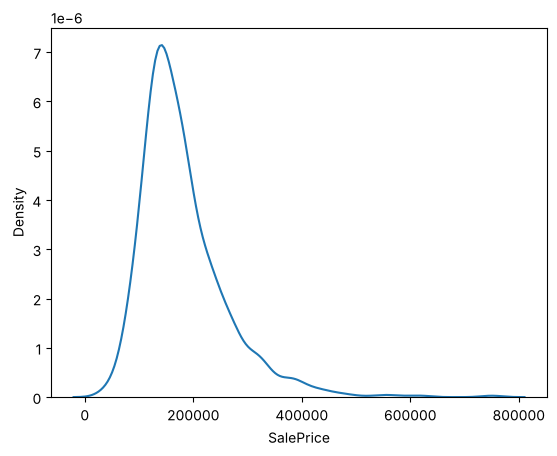

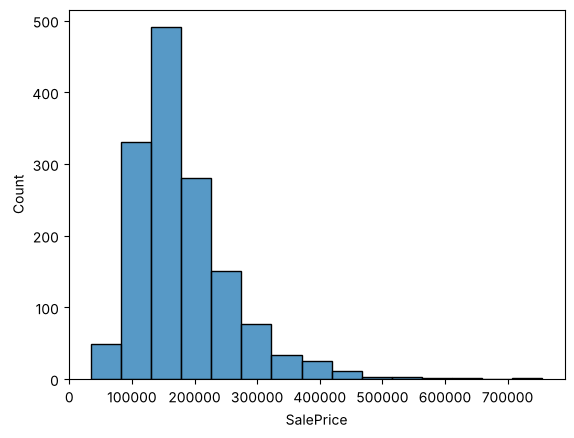

<Axes: xlabel='SalePrice'>

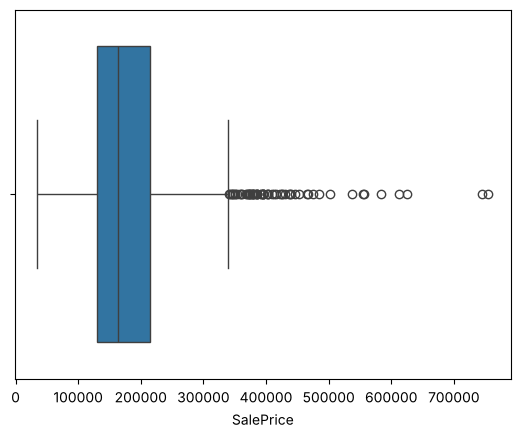

In [8]:
sns.kdeplot(x = 'SalePrice', data = df)
plt.show()
sns.histplot (x = "SalePrice", bins = 15, data = df)
plt.show()
sns.boxplot(x = 'SalePrice', data = df)

Right-skewed distribution

### Cleaning

In [9]:
df["SalePrice"].skew()

np.float64(1.8828757597682129)

If it > 1: Significant right skew

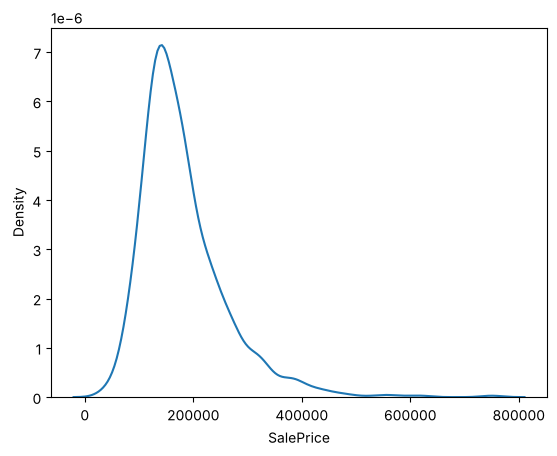

np.float64(0.12133506220521131)

In [10]:
df['SalePrice_log10']= np.log10(df['SalePrice'])
sns.kdeplot(x = 'SalePrice', data = df)
plt.show()
df.SalePrice_log10.skew()

Smaller than 0.5 --> normal distribution now

In [11]:
## Outliers
col = "SalePrice_log10"  

mean = df['SalePrice_log10'].mean()
std = df['SalePrice_log10'].std()

lower = mean - 3 * std
upper = mean + 3 * std

outliers = df[(df['SalePrice_log10'] < lower) | (df['SalePrice_log10'] > upper)]

print("3SD bounds:", lower, "to", upper)
print("Number of outliers:", len(outliers))

3SD bounds: 4.701539729960323 to 5.742418182990932
Number of outliers: 12


In [12]:
df[col] = df[col].clip(lower, upper)

print("\nWINSORIZING results:")
print("Outliers capped to the cutoff values of ", str(lower), "and ", str(upper))
print(df.SalePrice_log10.mean().round(2))


WINSORIZING results:
Outliers capped to the cutoff values of  4.701539729960323 and  5.742418182990932
5.22


0.16190451689091956


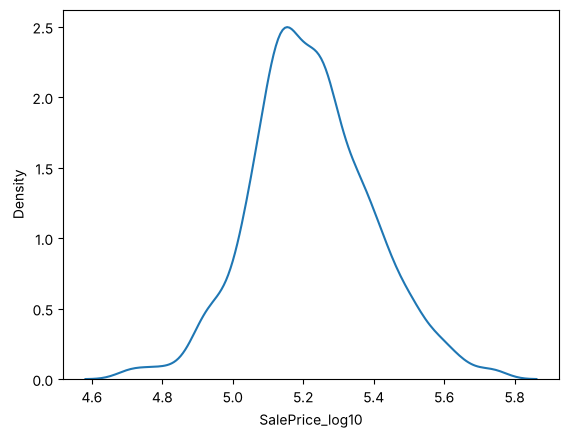

<Axes: xlabel='SalePrice_log10'>

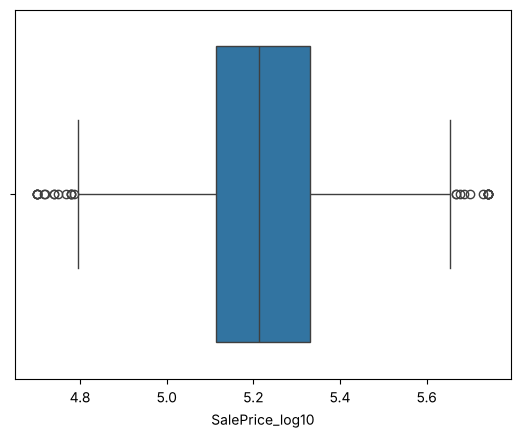

In [13]:
print(df.SalePrice_log10.skew())
sns.kdeplot(x = 'SalePrice_log10', data = df)
plt.show()
sns.boxplot(x = 'SalePrice_log10', data = df)

It becomes normal distribution with fewer outliers on both side.

### Check descriptive stats

In [14]:
df['SalePrice_log10'].agg(['min','mean', 'median','max','std']).round(2)

min       4.70
mean      5.22
median    5.21
max       5.74
std       0.17
Name: SalePrice_log10, dtype: float64

## MSSubClass (Categorical)

### Descriptive Statistics

In [15]:
df.MSSubClass.isna().sum()

np.int64(0)

In [16]:
df.MSSubClass.value_counts(normalize = True)

MSSubClass
20     0.367123
60     0.204795
50     0.098630
120    0.059589
30     0.047260
160    0.043151
70     0.041096
80     0.039726
90     0.035616
190    0.020548
85     0.013699
75     0.010959
45     0.008219
180    0.006849
40     0.002740
Name: proportion, dtype: float64

### Univariate Visualization

Text(0.5, 1.0, 'MSSubClass by Frequency')

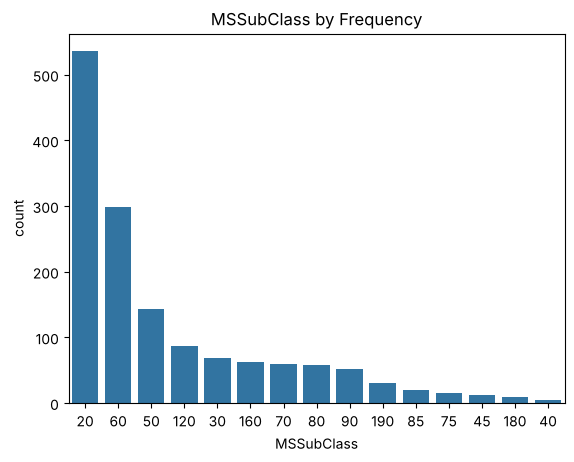

In [17]:
order = df["MSSubClass"].value_counts().index

sns.countplot(x="MSSubClass", data=df, order=order)
plt.title("MSSubClass by Frequency")

### Bivariate Visualization

<Axes: xlabel='MSSubClass', ylabel='SalePrice_log10'>

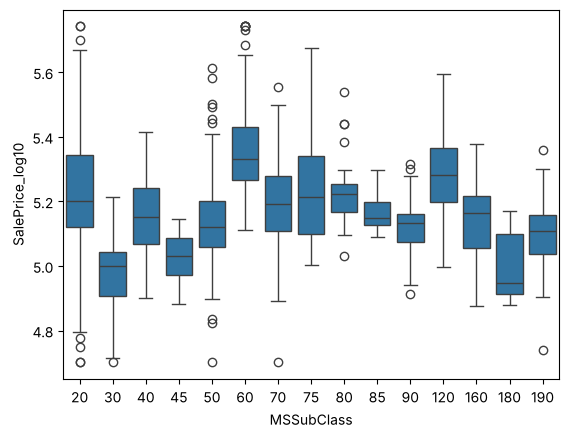

In [18]:
sns.boxplot(x='MSSubClass', y='SalePrice_log10', data = df, order = [20,30,40,45,50,60,70,75,80,85,90,120,160,180,190])

1. Shape of distribution: The variable shows uneven distribtuion. The value counts show that MSSubClass 20 is the highest frequency (536 observations) and Subclass 60 (299 observations), while other subclasses occur much less often.
2. Mising value: There is no missing value
3. Potential outliers: Outliers are not applicable to categorical variables. However, some subclasses contain very few observations (fewer than 10), which may require grouping or special consideration in the analysis.

### Cleaning

In [19]:
mssubclass = df.groupby("MSSubClass")['SalePrice_log10'].agg(['mean','median']).sort_values(by='median',ascending=True)
display(mssubclass)
freq = df["MSSubClass"].value_counts(normalize=True)
rare_classes = freq[freq < 0.01].index
display(rare_classes)

,mean,median
MSSubClass,,
180,4.995146,4.946770
30,4.967940,4.999565
45,5.028710,5.031333
190,5.096382,5.108050
50,5.131842,5.120571
90,5.116389,5.133475
85,5.166309,5.148333
40,5.155259,5.152848
160,5.127798,5.164353


Index(['45', '180', '40'], dtype='str', name='MSSubClass')

In [20]:
df.loc[df["MSSubClass"] == "40", "MSSubClass"] = "85"
df.loc[df["MSSubClass"] == "45", "MSSubClass"] = "30"
df.loc[df["MSSubClass"] == "180", "MSSubClass"] = "30"
df.MSSubClass.value_counts(normalize = True)

MSSubClass
20     0.367123
60     0.204795
50     0.098630
30     0.062329
120    0.059589
160    0.043151
70     0.041096
80     0.039726
90     0.035616
190    0.020548
85     0.016438
75     0.010959
Name: proportion, dtype: float64

MSSubClass was converted to a categorical variable. Rare subclasses were grouped based on similar median SalePrice to reduce sparsity and improve stability. Underrepresented subclasses were grouped with categories that have the closest median and mean SalePrice. Specifically, 40 → 85, and 180 and 45 → 30.

<Axes: xlabel='MSSubClass', ylabel='count'>

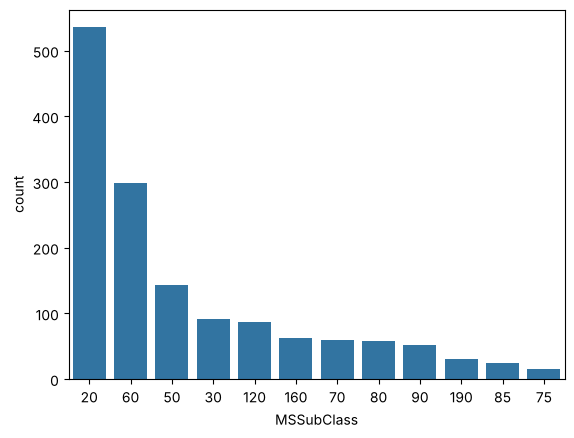

In [21]:
sns.countplot(x="MSSubClass", data=df, order = df.MSSubClass.value_counts().index)

<Axes: xlabel='MSSubClass', ylabel='SalePrice_log10'>

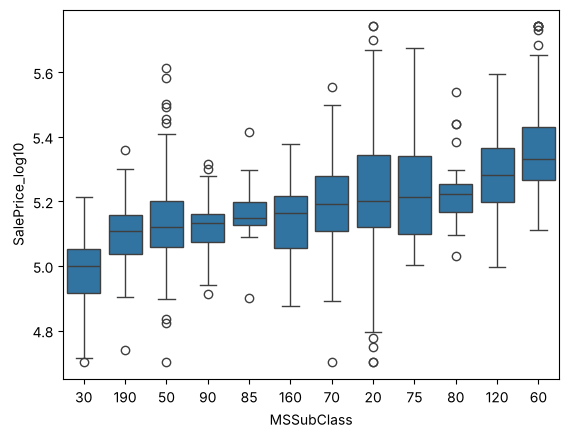

In [22]:
sns.boxplot(x="MSSubClass", y="SalePrice_log10", data=df, order= df.groupby("MSSubClass")["SalePrice"].median().sort_values().index)

The main relationship with SalePrice is preserved after cleaning, with subclasses 20 and 60 still showing the greatest variability.

In [23]:
#One-hot coding

dummies = pd.get_dummies(df["MSSubClass"], prefix="MSSubClass", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["MSSubClass"]), dummies], axis=1)
display(df.head())



,MSSubClass_120,MSSubClass_160,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90
0,0,0,0,0,0,0,1,0,0,0,0,0
1,0,0,0,1,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,1,0,0,0,0,0
3,0,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,0,1,0,0,0,0,0


,SalePrice,LotFrontage,LotArea,LotConfig,LandSlope,Neighborhood,OverallQual,ExterQual,Fireplaces,FireplaceQu,...,MSSubClass_190,MSSubClass_20,MSSubClass_30,MSSubClass_50,MSSubClass_60,MSSubClass_70,MSSubClass_75,MSSubClass_80,MSSubClass_85,MSSubClass_90
0,208500,65.0,8450,Inside,Gtl,CollgCr,7,Gd,0,NaN,...,0,0,0,0,1,0,0,0,0,0
1,181500,80.0,9600,FR2,Gtl,Veenker,6,TA,1,TA,...,0,1,0,0,0,0,0,0,0,0
2,223500,68.0,11250,Inside,Gtl,CollgCr,7,Gd,1,TA,...,0,0,0,0,1,0,0,0,0,0
3,140000,60.0,9550,Corner,Gtl,Crawfor,7,TA,1,Gd,...,0,0,0,0,0,1,0,0,0,0
4,250000,84.0,14260,FR2,Gtl,NoRidge,8,Gd,1,TA,...,0,0,0,0,1,0,0,0,0,0


### Correlation

In [24]:
col1 = df[['SalePrice_log10','MSSubClass_120','MSSubClass_160','MSSubClass_190','MSSubClass_20','MSSubClass_30','MSSubClass_50','MSSubClass_60','MSSubClass_70','MSSubClass_75','MSSubClass_80','MSSubClass_85','MSSubClass_90']]

display(col1.corr()['SalePrice_log10'])

SalePrice_log10    1.000000
MSSubClass_120     0.094030
MSSubClass_160    -0.117152
MSSubClass_190    -0.106509
MSSubClass_20      0.056596
MSSubClass_30     -0.366621
MSSubClass_50     -0.174666
MSSubClass_60      0.403173
MSSubClass_70     -0.029745
MSSubClass_75      0.010781
MSSubClass_80     -0.001354
MSSubClass_85     -0.043601
MSSubClass_90     -0.118837
Name: SalePrice_log10, dtype: float64

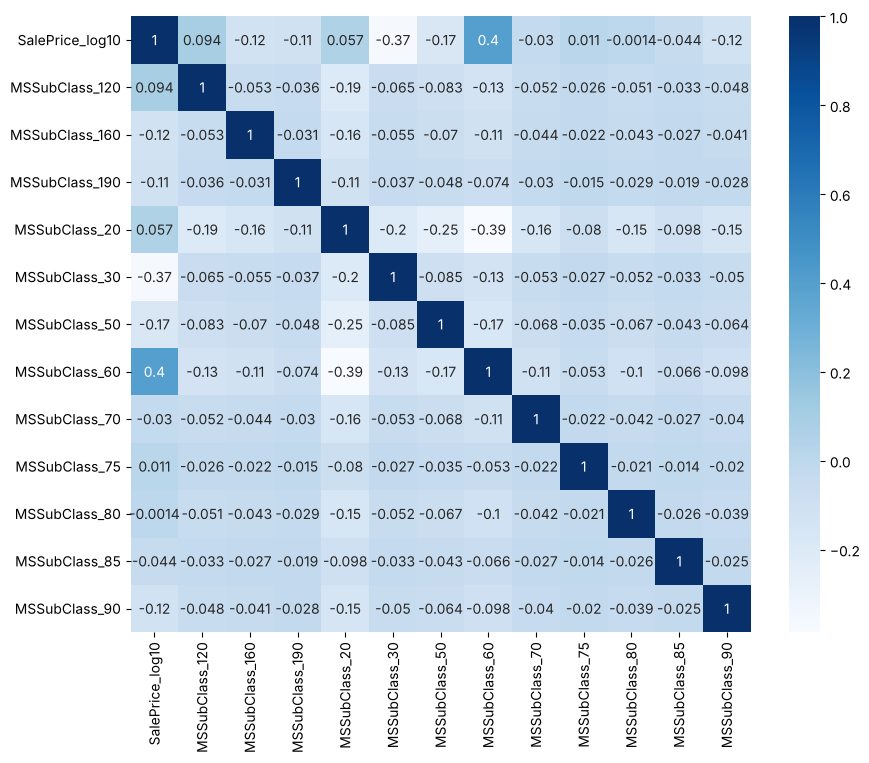

In [25]:
plt.figure(figsize=(10,8))
sns.heatmap(col1.corr(), annot = True, cmap="Blues")  
plt.show() 

The one-hot encoded MSSubClass variables reveal that certain housing types are associated with higher or lower sale prices. For example, MSSubClass_60 shows a positive correlation (r = 0.40), indicating higher-priced homes, while MSSubClass_30 shows a negative correlation (r = -0.33), suggesting lower-priced homes.

## LotFrontage (Numeric) + Linear Regression

### Descriptive statistics

In [26]:
df.LotFrontage.head()
df.LotFrontage.isna().sum()

np.int64(259)

259 missing values, huge number need to clean

In [27]:
df.LotFrontage.agg(['min', 'mean', 'median', 'max', 'std'])

min        21.000000
mean       70.049958
median     69.000000
max       313.000000
std        24.284752
Name: LotFrontage, dtype: float64

### Univariate Visualization

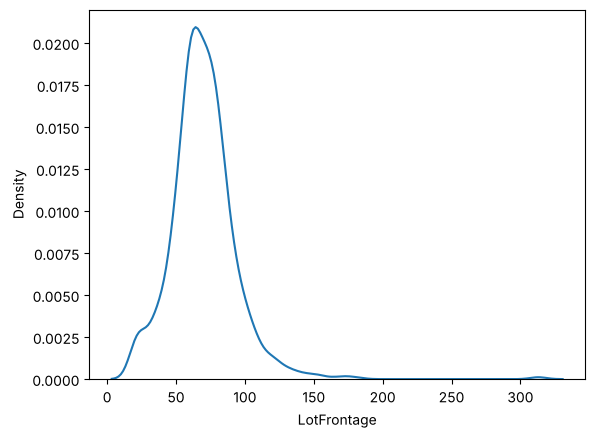

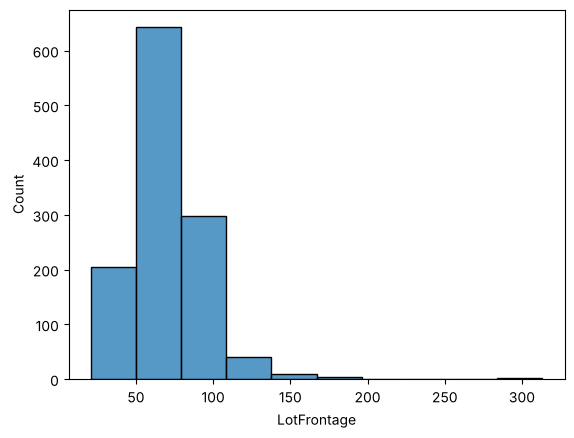

<Axes: xlabel='LotFrontage'>

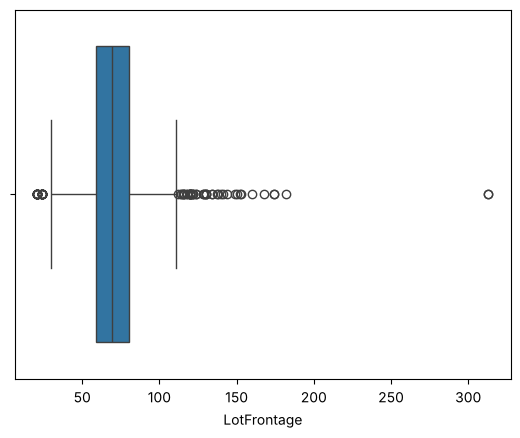

In [28]:
sns.kdeplot(x = "LotFrontage", data = df)
plt.show()
sns.histplot (x = "LotFrontage", bins = 10, data = df)
plt.show()
sns.boxplot(x = "LotFrontage", data = df)


Right-skewed distribution 

### Bivariate Visualization

<Axes: xlabel='LotFrontage', ylabel='SalePrice_log10'>

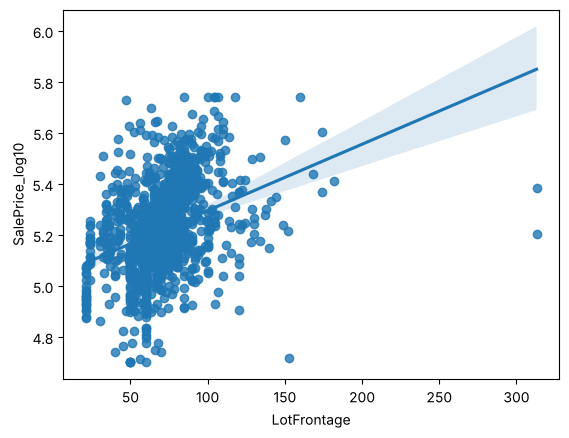

In [29]:
sns.regplot( x = "LotFrontage", y = "SalePrice_log10", data = df)

In [30]:
df[["LotFrontage","SalePrice_log10"]].corr()

,LotFrontage,SalePrice_log10
LotFrontage,1.000000,0.355202
SalePrice_log10,0.355202,1.000000


under 0.5 --> not strong correlation

### Cleaning

In [31]:
df.LotFrontage.skew()

np.float64(2.163569142324884)

LotArea was used to perform linear regression for imputing missing values in LotFrontage. SalePrice was not used, as it is the dependent variable and including it could lead to data leakage. Additionally, LotArea is logically related to LotFrontage, since LotFrontage represents the width of the lot while LotArea reflects the total size.

The distribution of LotFrontage was examined, and winsorization was applied if necessary to reduce the impact of extreme values before modeling.

In [32]:
!pip install pingouin

In [33]:
df.LotArea.corr(df.LotFrontage)

np.float64(0.4260950187718078)

In [34]:
train_data = df[df['LotFrontage'].notnull()]   # Complete cases
missing_data = df[df['LotFrontage'].isnull()]  # Missing cases

display(missing_data.info())

<class 'pandas.DataFrame'>
Index: 259 entries, 7 to 1446
Data columns (total 35 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   SalePrice        259 non-null    int64  
 1   LotFrontage      0 non-null      float64
 2   LotArea          259 non-null    int64  
 3   LotConfig        259 non-null    str    
 4   LandSlope        259 non-null    str    
 5   Neighborhood     259 non-null    str    
 6   OverallQual      259 non-null    str    
 7   ExterQual        259 non-null    str    
 8   Fireplaces       259 non-null    str    
 9   FireplaceQu      169 non-null    str    
 10  GarageType       252 non-null    str    
 11  GarageYrBlt      252 non-null    float64
 12  GarageFinish     252 non-null    str    
 13  GarageCars       259 non-null    int64  
 14  GarageArea       259 non-null    int64  
 15  GarageQual       252 non-null    str    
 16  GarageCond       252 non-null    str    
 17  BsmtFullBath     259 non-null  

None

In [35]:
import pingouin as pg

# Split dataset into known and missing LotFrontage values
train_data = df[df['LotFrontage'].notnull()]    # rows with known LotFrontage
missing_data = df[df['LotFrontage'].isnull()]   # rows with missing LotFrontage

display(missing_data.info())

<class 'pandas.DataFrame'>
Index: 259 entries, 7 to 1446
Data columns (total 35 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   SalePrice        259 non-null    int64  
 1   LotFrontage      0 non-null      float64
 2   LotArea          259 non-null    int64  
 3   LotConfig        259 non-null    str    
 4   LandSlope        259 non-null    str    
 5   Neighborhood     259 non-null    str    
 6   OverallQual      259 non-null    str    
 7   ExterQual        259 non-null    str    
 8   Fireplaces       259 non-null    str    
 9   FireplaceQu      169 non-null    str    
 10  GarageType       252 non-null    str    
 11  GarageYrBlt      252 non-null    float64
 12  GarageFinish     252 non-null    str    
 13  GarageCars       259 non-null    int64  
 14  GarageArea       259 non-null    int64  
 15  GarageQual       252 non-null    str    
 16  GarageCond       252 non-null    str    
 17  BsmtFullBath     259 non-null  

None

In [36]:
# X = LotArea (independent variable)
# y = LotFrontage (dependent variable to be predicted)
reg_results = pg.linear_regression(
    X=train_data[['LotArea']],
    y=train_data['LotFrontage']
)

print("REGRESSION RESULTS:")
print(reg_results)

REGRESSION RESULTS:
       names       coef        se          T          pval        r2  \
0  Intercept  57.055042  1.018395  56.024499  0.000000e+00  0.181557   
1    LotArea   0.001306  0.000080  16.308793  3.697417e-54  0.181557   

     adj_r2      CI2.5     CI97.5  
0  0.180874  55.057009  59.053076  
1  0.180874   0.001149   0.001463  


In [37]:
# Extract coefficients
intercept = reg_results.loc[0, 'coef']
slope = reg_results.loc[1, 'coef']

print("The intercept of the model is", intercept, "and the slope is", slope)

The intercept of the model is 57.055042483859395 and the slope is 0.0013057987813648406


In [38]:
# Predict missing LotFrontage values
predicted_values = intercept + slope * missing_data['LotArea']

# Fill missing values in LotFrontage
df.loc[df['LotFrontage'].isnull(), 'LotFrontage'] = predicted_values

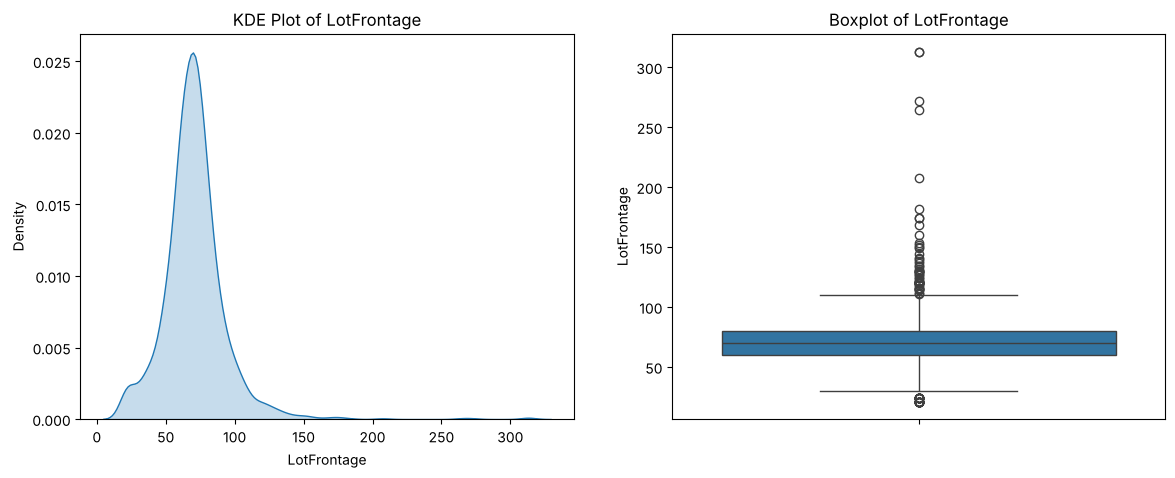

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(
    data=df,
    x='LotFrontage',
    fill=True,
    ax=axes[0]
)
axes[0].set_title("KDE Plot of LotFrontage")
axes[0].set_xlabel("LotFrontage")

sns.boxplot(
    data=df,
    y='LotFrontage',
    ax=axes[1]
)
axes[1].set_title("Boxplot of LotFrontage")
axes[1].set_ylabel("LotFrontage")

plt.show()

In [40]:
# Log-transform first to symmetrize the right-skewed distribution
# This ensures winsorizing clips balanced on BOTH sides, not just the right tail
df["LotFrontage_log"] = np.log(df["LotFrontage"])  # all values > 0, safe to log

Q1 = df["LotFrontage_log"].quantile(0.25)
Q3 = df["LotFrontage_log"].quantile(0.75)
IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR   # correct: Q1 for lower bound
upper = Q3 + 1.5 * IQR

outliers = df[(df["LotFrontage_log"] < lower) | (df["LotFrontage_log"] > upper)]
print("Log-scale IQR Bounds:", lower, "to", upper)
print("Number of outliers:", len(outliers))

Log-scale IQR Bounds: 3.6628214535444292 to 4.813549743351553
Number of outliers: 117


In [41]:
# Winsorize on log scale, then back-transform to original units
df["LotFrontage_log"] = df["LotFrontage_log"].clip(lower, upper)
df["LotFrontage"] = np.exp(df["LotFrontage_log"])
df.drop(columns=["LotFrontage_log"], inplace=True)

print("\nLotFrontage after winsorizing:")
print(df["LotFrontage"].describe().round(2))
print("Skew after fix:", round(df["LotFrontage"].skew(), 3))


LotFrontage after winsorizing:
count    1460.00
mean       70.54
std        18.23
min        38.97
25%        60.00
50%        70.00
75%        80.00
max       123.17
Name: LotFrontage, dtype: float64
Skew after fix: 0.622


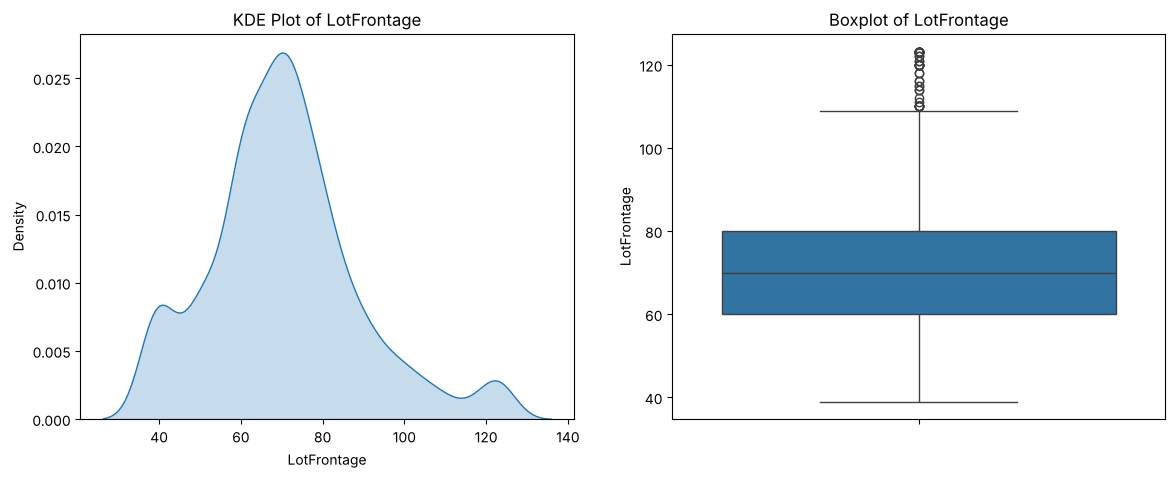

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(
    data=df,
    x='LotFrontage',
    fill=True,
    ax=axes[0]
)
axes[0].set_title("KDE Plot of LotFrontage")
axes[0].set_xlabel("LotFrontage")

sns.boxplot(
    data=df,
    y='LotFrontage',
    ax=axes[1]
)
axes[1].set_title("Boxplot of LotFrontage")
axes[1].set_ylabel("LotFrontage")

plt.show()

### Check and plot 

np.float64(0.38013025353012186)

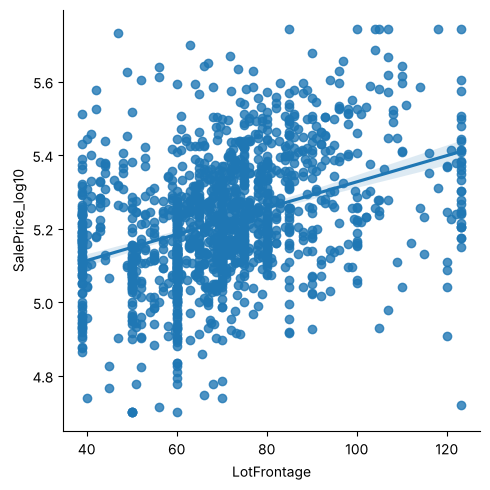

In [43]:
sns.lmplot(x="LotFrontage",y="SalePrice_log10",data=df)
df['LotFrontage'].corr(df['SalePrice_log10'])

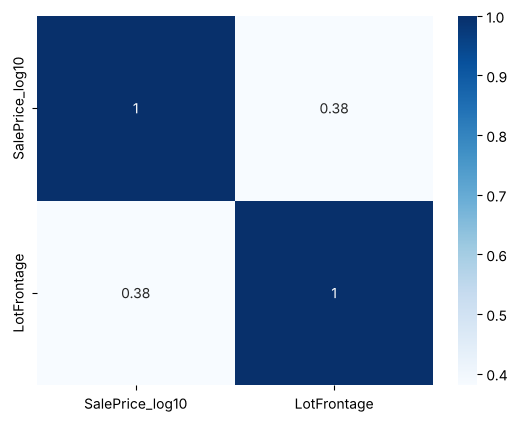

In [44]:
col2 = df[['SalePrice_log10','LotFrontage']]

col2.corr()['SalePrice_log10']

sns.heatmap(col2.corr(), annot = True, cmap="Blues")   
plt.show()     

The correlation increased after cleaning, indicating improved data quality. LotFrontage shows a moderate positive relationship with SalePrice, meaning larger frontage is associated with higher prices.

## LotArea (Numeric)

### Descriptive statistic

In [45]:
display(df.LotArea.head())
df.LotArea.isna().sum()

0     8450
1     9600
2    11250
3     9550
4    14260
Name: LotArea, dtype: int64

np.int64(0)

In [46]:
df.LotArea.agg(['min', 'mean', 'median', 'max', 'std'])

min         1300.000000
mean       10516.828082
median      9478.500000
max       215245.000000
std         9981.264932
Name: LotArea, dtype: float64

### Univariate Visualization

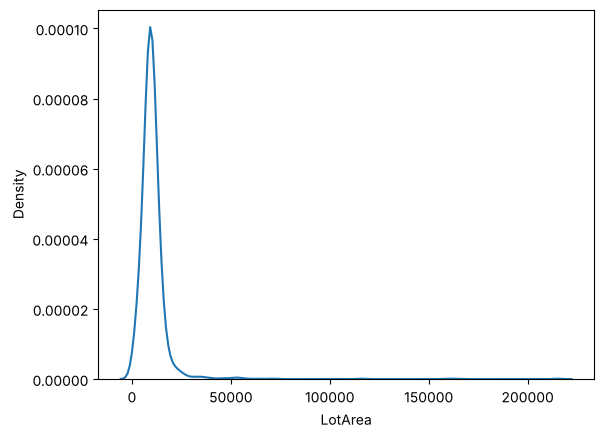

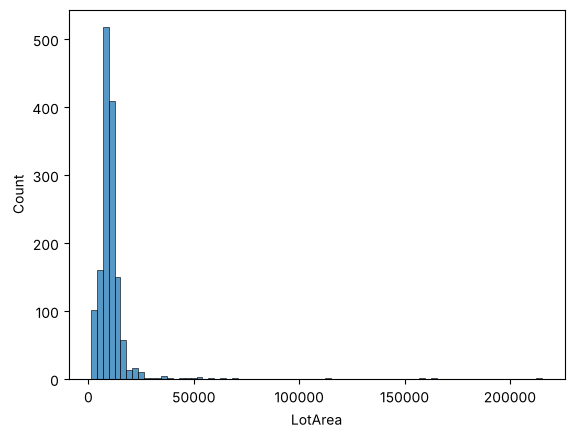

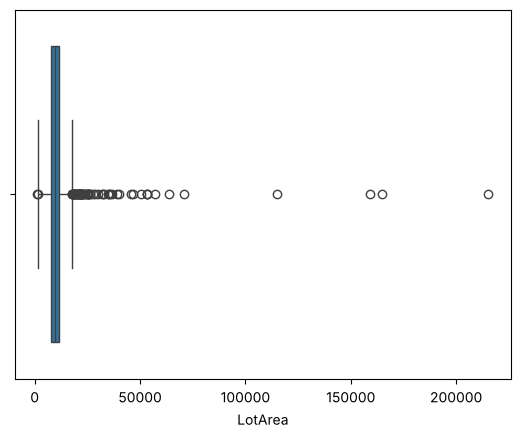

In [47]:
sns.kdeplot(x = "LotArea", data = df)
plt.show()
sns.histplot (x = "LotArea", data = df)
plt.show()
sns.boxplot(x = "LotArea", data = df)
plt.show()

Significant right-skewed distribution and a lot of outliers need to clean

### Bivariate Visualization

Correlation = 0.25861553220279043


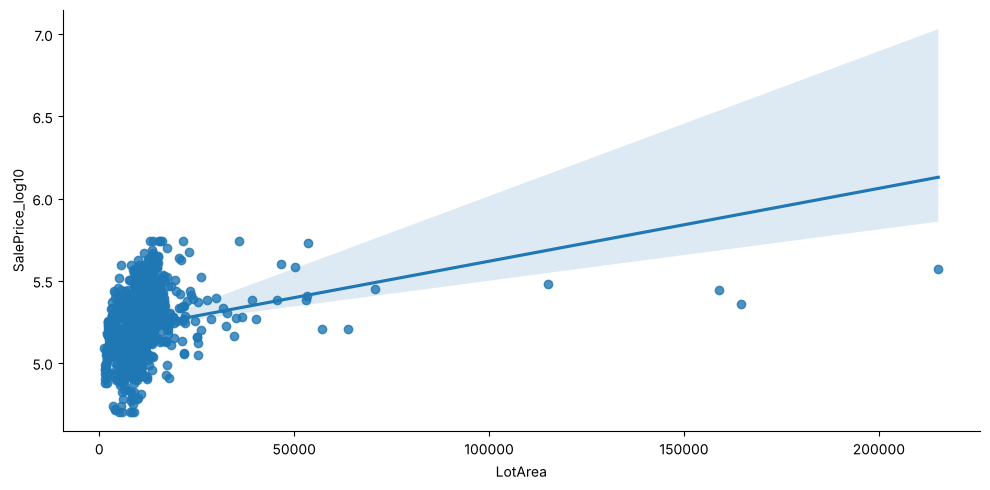

In [48]:
sns.lmplot(x = 'LotArea', y = 'SalePrice_log10', data = df, aspect = 2)
print("Correlation =", df[['LotArea','SalePrice_log10']].corr().iloc[1,0])

In [49]:
df['LotArea'].corr(df['SalePrice_log10'])

np.float64(0.25861553220279093)

Lower than 0.5 so very weak correlation now

### Cleaning

In [50]:
df.LotArea.skew()

np.float64(12.207687851233496)

In [51]:
df["LotArea_log"] = np.log(df["LotArea"])
print(df["LotArea_log"].skew())

df["LotArea_log10"] = np.log10(df["LotArea"])
print(df["LotArea_log10"].skew())

df["LotArea_sqrt"] = np.sqrt(df["LotArea"])
print(df["LotArea_sqrt"].skew())

-0.1379938086958118
-0.13799380869581324
4.139713548289236


The LotArea variable exhibited extreme right skewness (skew = 12.21). Both log and log10 transformations were evaluated, and each reduced skewness to approximately -0.14. A natural log transformation was selected as it is the standard approach in statistical modeling. The transformed variable is approximately symmetric, indicating effective normalization.

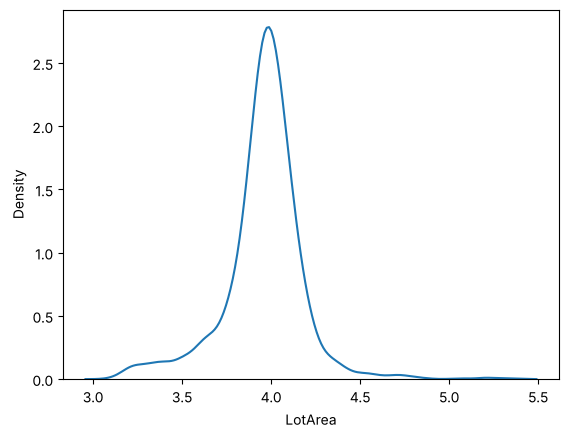

np.float64(-0.1379938086958118)

In [52]:
df['LotArea_log'] = np.log(df.LotArea)
sns.kdeplot(data=df, x=np.log10(df.LotArea))
plt.show()
df.LotArea_log.skew()

In [53]:
col = "LotArea_log"
mean1 = df[col].mean()
std1 = df[col].std()

lower3 = mean1 - 3 * std1
upper3 = mean1 + 3 * std1

outliers3 = df[(df[col] < lower3) | (df[col] > upper3)]

print("3SD bounds:", lower3, "to", upper3)
print("Number of outliers:", len(outliers3))
outliers3[["SalePrice", col]].head()

df[col] = df[col].clip(lower3, upper3)

print("\nWINSORIZING results:")
print("Outliers capped to the cutoff values of ", str(lower3), "and ", str(upper3))
print(df.LotArea_log.mean().round(2))

3SD bounds: 7.558494034668209 to 10.663182444342885
Number of outliers: 33

WINSORIZING results:
Outliers capped to the cutoff values of  7.558494034668209 and  10.663182444342885
9.11


In [54]:
df['LotArea_log'].skew()

np.float64(-0.5819017732770339)

skew is better now, less than 1, not too skewed

### Check

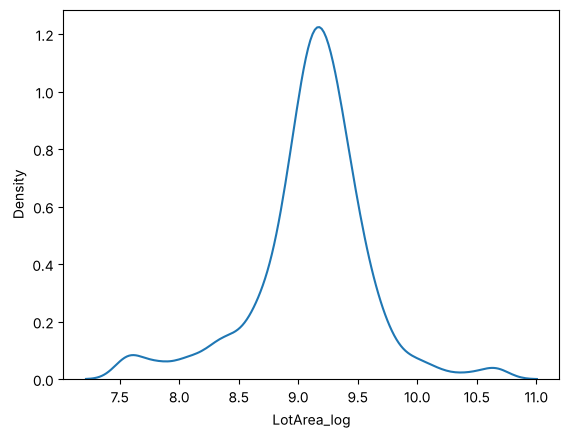

<Axes: xlabel='LotArea_log'>

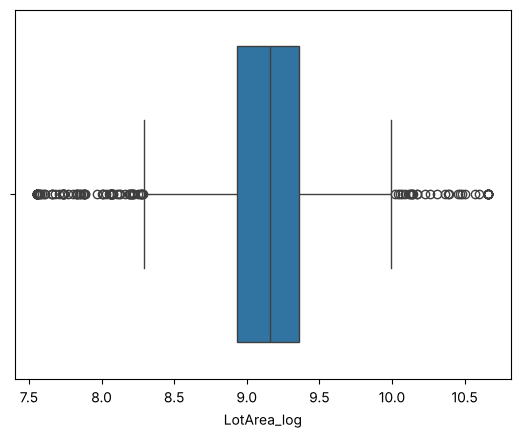

In [55]:
sns.kdeplot(x = 'LotArea_log', data = df)
plt.show()
sns.boxplot(x = 'LotArea_log', data = df)

Correlation = 0.4052994699595013


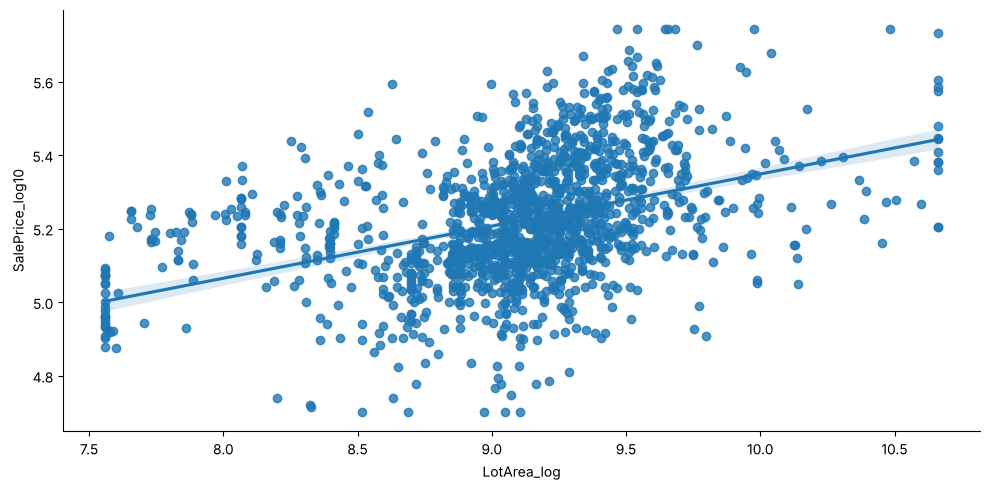

In [56]:
sns.lmplot(x = 'LotArea_log', y = 'SalePrice_log10', data = df, aspect = 2)
print("Correlation =", df[['LotArea_log','SalePrice_log10']].corr().iloc[1,0])

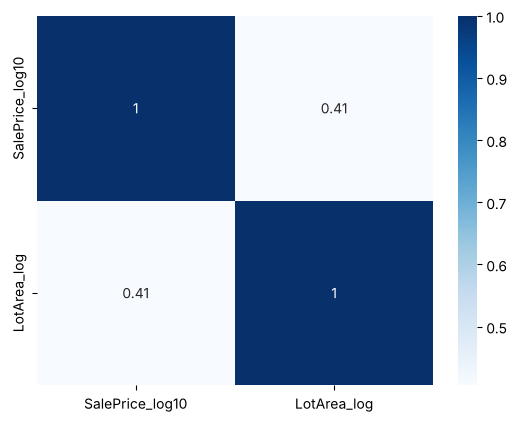

In [57]:
col3 = df[['SalePrice_log10','LotArea_log']]

col3.corr()['SalePrice_log10']

sns.heatmap(col3.corr(), annot = True, cmap="Blues")   
plt.show()  

Correlation increased and cleaning made the correlation more visible. As LotArea increases, SalePrice also increases. LotArea can be a good predictor of SalePrice

## LotConfig (Categorical)

### Descriptive Statistics

In [58]:
display(df.LotConfig.head())
df.LotConfig.isna().sum()

0    Inside
1       FR2
2    Inside
3    Corner
4       FR2
Name: LotConfig, dtype: str

np.int64(0)

In [59]:
df.LotConfig.value_counts(normalize = True)

LotConfig
Inside     0.720548
Corner     0.180137
CulDSac    0.064384
FR2        0.032192
FR3        0.002740
Name: proportion, dtype: float64

No missing value and don't have >1 value

### Univariate Visualization

Text(0.5, 1.0, 'LotConfig')

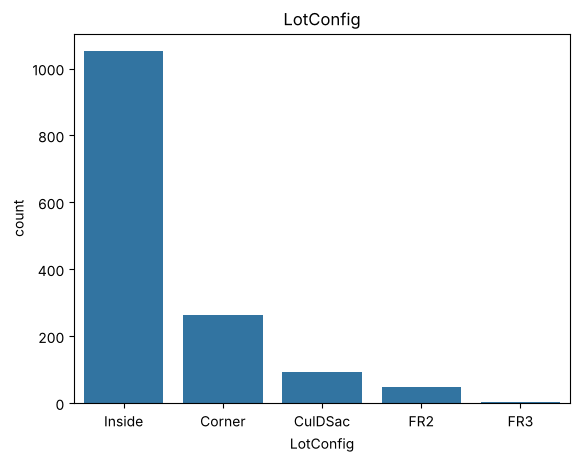

In [60]:
sns.countplot(x="LotConfig", data=df, order = df.LotConfig.value_counts().index)
plt.title("LotConfig")

<Axes: xlabel='LotConfig', ylabel='SalePrice_log10'>

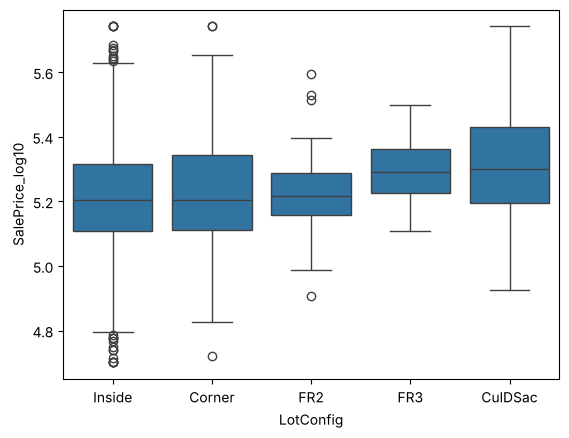

In [61]:
sns.boxplot(x="LotConfig", y="SalePrice_log10", data=df, order= df.groupby("LotConfig")["SalePrice_log10"].median().sort_values().index)

Nearly the same mean price and range for each category

### Cleaning

In [62]:
config_map = {
    "FR2": "MultiConfig",
    "FR3": "MultiConfig",
    "Inside": "Inside",
    "Corner": "Corner",
    "CulDSac": "CulDSac",
}
df["LotConfig"] = df["LotConfig"].map(config_map)
print("\nCounts after mapping:")
display(df["LotConfig"].value_counts(dropna=False))


Counts after mapping:


LotConfig
Inside         1052
Corner          263
CulDSac          94
MultiConfig      51
Name: count, dtype: int64

FR2 and FR3 were grouped into "MultiConfig" due to their similar characteristics of having multiple street frontages, reducing sparsity while maintaining interpretability.

Text(0.5, 1.0, 'LotConfig')

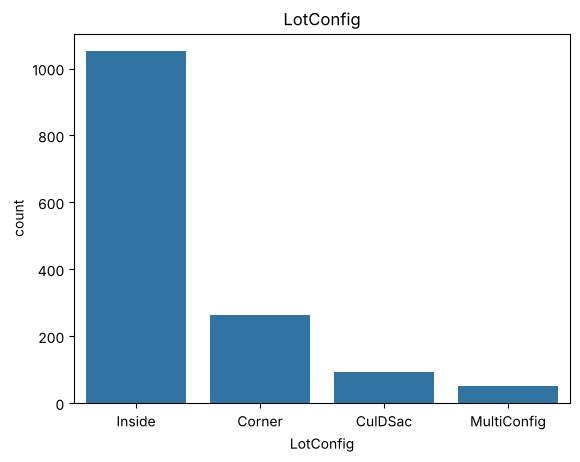

In [63]:
sns.countplot(x="LotConfig", data=df, order = df.LotConfig.value_counts().index)
plt.title("LotConfig")

Text(0.5, 1.0, 'SalePrice by LotConfig (Ordered by Median Price)')

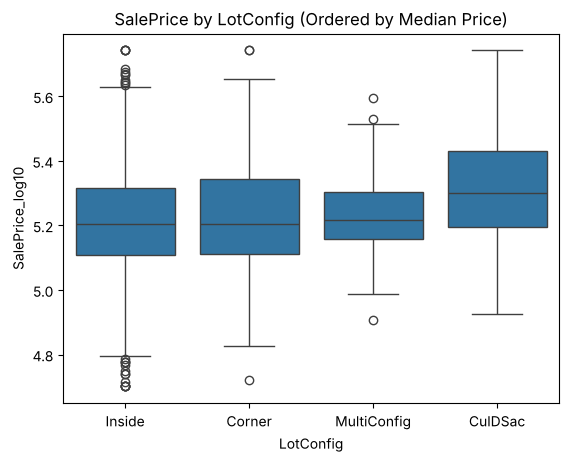

In [64]:
sns.boxplot(x="LotConfig", y="SalePrice_log10", data=df, order= df.groupby("LotConfig")["SalePrice_log10"].median().sort_values().index)
plt.title("SalePrice by LotConfig (Ordered by Median Price)")

In [65]:
#One-hot coding
dummies = pd.get_dummies(df["LotConfig"], prefix="LotConfig", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["LotConfig"]), dummies], axis=1)
display(df.head())

,LotConfig_Corner,LotConfig_CulDSac,LotConfig_Inside,LotConfig_MultiConfig
0,0,0,1,0
1,0,0,0,1
2,0,0,1,0
3,1,0,0,0
4,0,0,0,1


,SalePrice,LotFrontage,LotArea,LandSlope,Neighborhood,OverallQual,ExterQual,Fireplaces,FireplaceQu,GarageType,...,MSSubClass_80,MSSubClass_85,MSSubClass_90,LotArea_log,LotArea_log10,LotArea_sqrt,LotConfig_Corner,LotConfig_CulDSac,LotConfig_Inside,LotConfig_MultiConfig
0,208500,65.0,8450,Gtl,CollgCr,7,Gd,0,NaN,Attchd,...,0,0,0,9.041922,3.926857,91.923882,0,0,1,0
1,181500,80.0,9600,Gtl,Veenker,6,TA,1,TA,Attchd,...,0,0,0,9.169518,3.982271,97.979590,0,0,0,1
2,223500,68.0,11250,Gtl,CollgCr,7,Gd,1,TA,Attchd,...,0,0,0,9.328123,4.051153,106.066017,0,0,1,0
3,140000,60.0,9550,Gtl,Crawfor,7,TA,1,Gd,Detchd,...,0,0,0,9.164296,3.980003,97.724101,1,0,0,0
4,250000,84.0,14260,Gtl,NoRidge,8,Gd,1,TA,Attchd,...,0,0,0,9.565214,4.154120,119.415242,0,0,0,1


### Correlation

In [66]:
col4 = df[['SalePrice_log10','LotConfig_Corner','LotConfig_CulDSac','LotConfig_Inside','LotConfig_MultiConfig']]

col4.corr()['SalePrice_log10']

SalePrice_log10          1.000000
LotConfig_Corner         0.000805
LotConfig_CulDSac        0.149244
LotConfig_Inside        -0.086850
LotConfig_MultiConfig    0.011072
Name: SalePrice_log10, dtype: float64

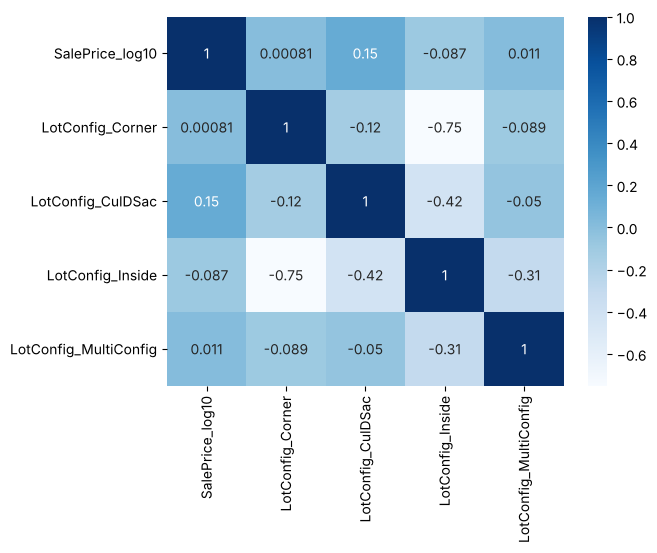

In [67]:
sns.heatmap(col4.corr(), annot = True, cmap="Blues")   
plt.show() 

## LandSlope (Categorical)

### Descriptive Statistics

In [68]:
df.LandSlope.isna().sum()

np.int64(0)

In [69]:
df.LandSlope.value_counts(normalize = True)

LandSlope
Gtl    0.946575
Mod    0.044521
Sev    0.008904
Name: proportion, dtype: float64

No missing value found

### Univariate 

Text(0.5, 1.0, 'LandSlope')

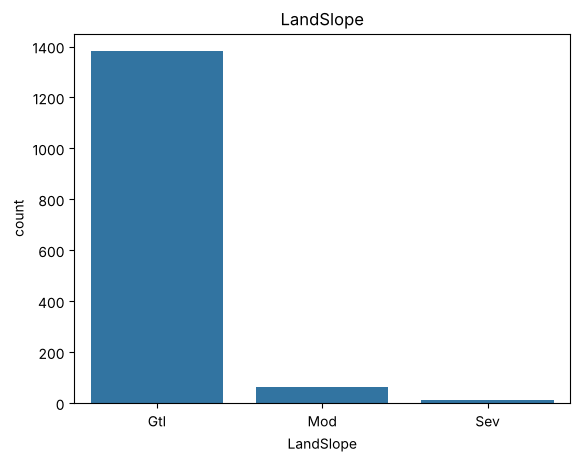

In [70]:
sns.countplot(x="LandSlope", data=df, order = df.LandSlope.value_counts().index)
plt.title("LandSlope")

### Bivariate

<Axes: xlabel='LandSlope', ylabel='SalePrice_log10'>

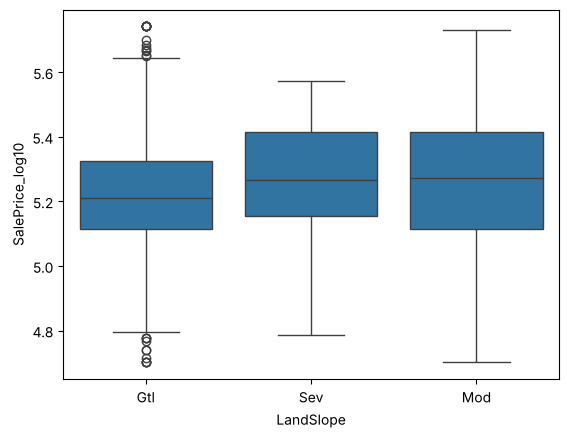

In [71]:
sns.boxplot(x="LandSlope", y="SalePrice_log10", data=df, order= df.groupby("LandSlope")["SalePrice_log10"].median().sort_values().index)

Shape of distribution: The variable shows an uneven distribution, with the majority of observations classified as Gtl, while Mod and Sev occur much less frequently.

Missing values: There are no missing values in this variable.

Potential outliers: Outliers are not applicable to categorical variables. However, Mod and Sev have relatively low frequencies and may contribute less to the analysis.

Cleaning approach: Since the categories represent meaningful differences in slope conditions, no grouping was performed. The variable was kept as is to preserve its interpretability.

### Cleaning

In [72]:
slope_map = {
    "Gtl": "Gtl",
    "Mod": "Mod",
    "Sev": "Mod",
}
df["LandSlope"] = df["LandSlope"].map(slope_map)
print("\nCounts after mapping:")
display(df["LandSlope"].value_counts(dropna=False))


Counts after mapping:


LandSlope
Gtl    1382
Mod      78
Name: count, dtype: int64

Map the common variable, Sev is less then 1% so map it together with Mod

Text(0.5, 1.0, 'LandSlope')

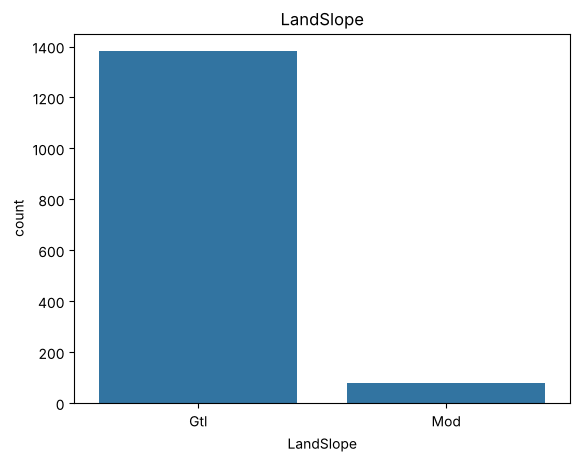

In [73]:
sns.countplot(x="LandSlope", data=df, order = df.LandSlope.value_counts().index)
plt.title("LandSlope")

Text(0.5, 1.0, 'SalePrice by LandSlope (Ordered by Median Price)')

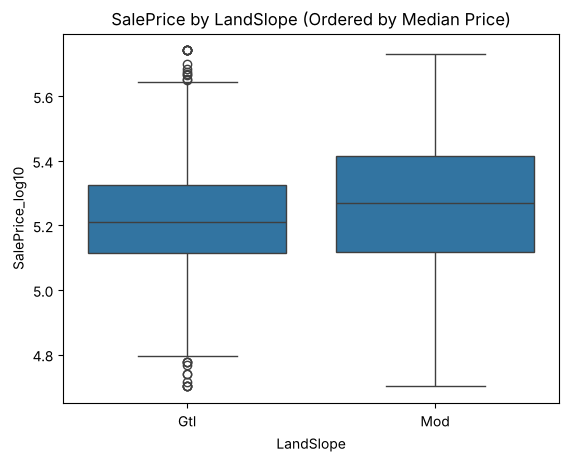

In [74]:
sns.boxplot(x="LandSlope", y="SalePrice_log10", data=df, order= df.groupby("LandSlope")["SalePrice_log10"].median().sort_values().index)
plt.title("SalePrice by LandSlope (Ordered by Median Price)")

In [75]:
#One-hot coding
dummies = pd.get_dummies(df["LandSlope"], prefix="LandSlope", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["LandSlope"]), dummies], axis=1)
display(df.head())

,LandSlope_Gtl,LandSlope_Mod
0,1,0
1,1,0
2,1,0
3,1,0
4,1,0


,SalePrice,LotFrontage,LotArea,Neighborhood,OverallQual,ExterQual,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,...,MSSubClass_90,LotArea_log,LotArea_log10,LotArea_sqrt,LotConfig_Corner,LotConfig_CulDSac,LotConfig_Inside,LotConfig_MultiConfig,LandSlope_Gtl,LandSlope_Mod
0,208500,65.0,8450,CollgCr,7,Gd,0,NaN,Attchd,2003.0,...,0,9.041922,3.926857,91.923882,0,0,1,0,1,0
1,181500,80.0,9600,Veenker,6,TA,1,TA,Attchd,1976.0,...,0,9.169518,3.982271,97.979590,0,0,0,1,1,0
2,223500,68.0,11250,CollgCr,7,Gd,1,TA,Attchd,2001.0,...,0,9.328123,4.051153,106.066017,0,0,1,0,1,0
3,140000,60.0,9550,Crawfor,7,TA,1,Gd,Detchd,1998.0,...,0,9.164296,3.980003,97.724101,1,0,0,0,1,0
4,250000,84.0,14260,NoRidge,8,Gd,1,TA,Attchd,2000.0,...,0,9.565214,4.154120,119.415242,0,0,0,1,1,0


### Correlation

In [76]:
col5 = df[['SalePrice_log10','LandSlope_Gtl','LandSlope_Mod']]

col5.corr()['SalePrice_log10']

SalePrice_log10    1.000000
LandSlope_Gtl     -0.038929
LandSlope_Mod      0.038929
Name: SalePrice_log10, dtype: float64

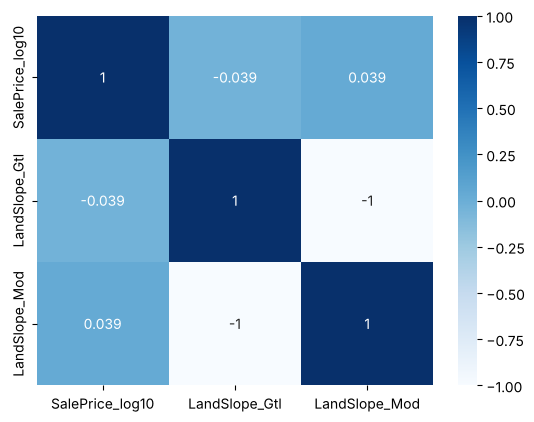

In [77]:
sns.heatmap(col5.corr(), annot = True, cmap="Blues")   
plt.show() 


LandSlope is not a strong predictor of SalePrice. The correlations with SalePrice are very low (maximum around 0.05), indicating little to no influence on housing prices.

Additionally, Slope_Gtl and Slope_Mod exhibit perfect negative correlation due to one-hot encoding. Therefore, they should not be included together in the model to avoid multicollinearity.

## Neighborhood (Categorical)

### Descriptive Stats

In [78]:
df.Neighborhood.isna().sum()

np.int64(0)

In [79]:
df["Neighborhood"].value_counts(normalize = True) 

Neighborhood
NAmes      0.154110
CollgCr    0.102740
OldTown    0.077397
Edwards    0.068493
Somerst    0.058904
Gilbert    0.054110
NridgHt    0.052740
Sawyer     0.050685
NWAmes     0.050000
SawyerW    0.040411
BrkSide    0.039726
Crawfor    0.034932
Mitchel    0.033562
NoRidge    0.028082
Timber     0.026027
IDOTRR     0.025342
ClearCr    0.019178
StoneBr    0.017123
SWISU      0.017123
MeadowV    0.011644
Blmngtn    0.011644
BrDale     0.010959
Veenker    0.007534
NPkVill    0.006164
Blueste    0.001370
Name: proportion, dtype: float64

In [80]:
df.Neighborhood.unique()

<StringArray>
['CollgCr', 'Veenker', 'Crawfor', 'NoRidge', 'Mitchel', 'Somerst',  'NWAmes',
 'OldTown', 'BrkSide',  'Sawyer', 'NridgHt',   'NAmes', 'SawyerW',  'IDOTRR',
 'MeadowV', 'Edwards',  'Timber', 'Gilbert', 'StoneBr', 'ClearCr', 'NPkVill',
 'Blmngtn',  'BrDale',   'SWISU', 'Blueste']
Length: 25, dtype: str

### Univariate 

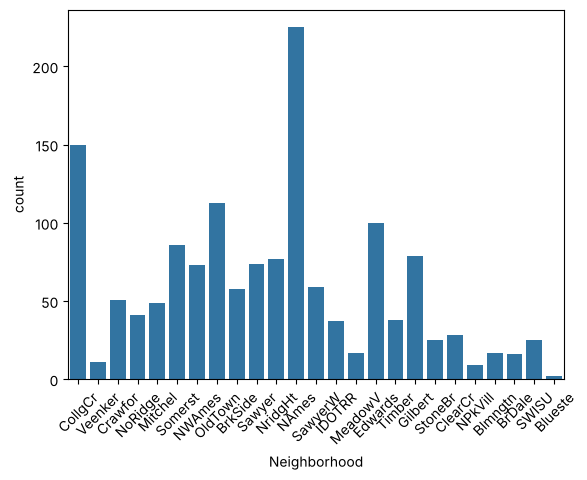

In [81]:
sns.countplot( x = "Neighborhood", data = df)
plt.xticks (rotation = 45)
plt.show()







SalePrices vary a lot by Neighborhood with a different ranges and medians, which might reveal some relationships under it.

### Bivariate

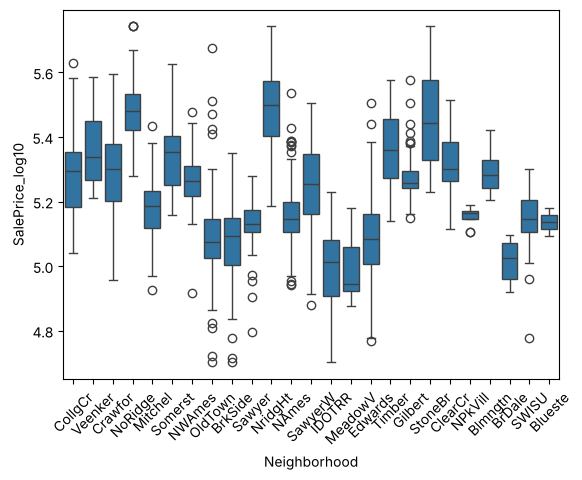

In [82]:
sns.boxplot(x = "Neighborhood", y = "SalePrice_log10", data = df)
plt.xticks (rotation = 45)
plt.show()

SalePrice varies significantly across neighborhoods, with noticeable differences in both ranges and median values. This suggests that location plays an important role and may have a strong relationship with housing prices.

### Cleaning

In [83]:
df.groupby("Neighborhood")['SalePrice_log10'].agg(['mean','count']).sort_values(by='mean',ascending=False)

,mean,count
Neighborhood,,
NoRidge,5.497343,41
NridgHt,5.479642,77
StoneBr,5.465683,25
Timber,5.369380,38
Veenker,5.361007,11
Somerst,5.340300,86
ClearCr,5.315721,28
Crawfor,5.301285,51
Blmngtn,5.285110,17


In [84]:
neighborhood_1 = df['Neighborhood'].value_counts(normalize=True)

neigh = neighborhood_1[neighborhood_1<0.01].index.tolist()
neigh

['Veenker', 'NPkVill', 'Blueste']

In [85]:
df["Neighborhood"]=df["Neighborhood"].apply(lambda x: "Other" if x in neigh else x)
df["Neighborhood"] 

0       CollgCr
1         Other
2       CollgCr
3       Crawfor
4       NoRidge
         ...   
1455    Gilbert
1456     NWAmes
1457    Crawfor
1458      NAmes
1459    Edwards
Name: Neighborhood, Length: 1460, dtype: str

In [86]:
df["Neighborhood"].value_counts(normalize = True) 

Neighborhood
NAmes      0.154110
CollgCr    0.102740
OldTown    0.077397
Edwards    0.068493
Somerst    0.058904
Gilbert    0.054110
NridgHt    0.052740
Sawyer     0.050685
NWAmes     0.050000
SawyerW    0.040411
BrkSide    0.039726
Crawfor    0.034932
Mitchel    0.033562
NoRidge    0.028082
Timber     0.026027
IDOTRR     0.025342
ClearCr    0.019178
StoneBr    0.017123
SWISU      0.017123
Other      0.015068
MeadowV    0.011644
Blmngtn    0.011644
BrDale     0.010959
Name: proportion, dtype: float64



The Neighborhood variable contains several low-frequency categories that may introduce noise in the analysis. To address this, underrepresented neighborhoods are grouped into an "Other" category using a predefined list (neigh).

This reduces sparsity, improves model stability, and simplifies interpretation while preserving the overall structure of the data.

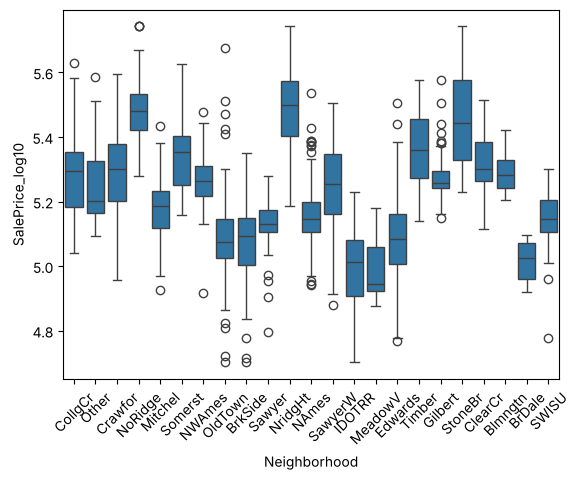

In [87]:
sns.boxplot(x = "Neighborhood", y = "SalePrice_log10", data = df)
plt.xticks (rotation = 45)
plt.show()

In [88]:
#One-hot coding
dummies = pd.get_dummies(df["Neighborhood"], prefix="Neighborhood", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["Neighborhood"]), dummies], axis=1)
display(df.head())

,Neighborhood_Blmngtn,Neighborhood_BrDale,Neighborhood_BrkSide,Neighborhood_ClearCr,Neighborhood_CollgCr,Neighborhood_Crawfor,Neighborhood_Edwards,Neighborhood_Gilbert,Neighborhood_IDOTRR,Neighborhood_MeadowV,...,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_Other,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber
0,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
2,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0


,SalePrice,LotFrontage,LotArea,OverallQual,ExterQual,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,...,Neighborhood_NoRidge,Neighborhood_NridgHt,Neighborhood_OldTown,Neighborhood_Other,Neighborhood_SWISU,Neighborhood_Sawyer,Neighborhood_SawyerW,Neighborhood_Somerst,Neighborhood_StoneBr,Neighborhood_Timber
0,208500,65.0,8450,7,Gd,0,NaN,Attchd,2003.0,RFn,...,0,0,0,0,0,0,0,0,0,0
1,181500,80.0,9600,6,TA,1,TA,Attchd,1976.0,RFn,...,0,0,0,1,0,0,0,0,0,0
2,223500,68.0,11250,7,Gd,1,TA,Attchd,2001.0,RFn,...,0,0,0,0,0,0,0,0,0,0
3,140000,60.0,9550,7,TA,1,Gd,Detchd,1998.0,Unf,...,0,0,0,0,0,0,0,0,0,0
4,250000,84.0,14260,8,Gd,1,TA,Attchd,2000.0,RFn,...,1,0,0,0,0,0,0,0,0,0


### Correlation

In [89]:
col6 = df[['SalePrice_log10','Neighborhood_Blmngtn','Neighborhood_BrDale','Neighborhood_BrkSide','Neighborhood_ClearCr','Neighborhood_CollgCr','Neighborhood_Crawfor','Neighborhood_Edwards','Neighborhood_Gilbert','Neighborhood_IDOTRR','Neighborhood_MeadowV','Neighborhood_Mitchel','Neighborhood_NAmes','Neighborhood_NWAmes','Neighborhood_NoRidge','Neighborhood_NridgHt','Neighborhood_OldTown','Neighborhood_SWISU','Neighborhood_Sawyer','Neighborhood_SawyerW','Neighborhood_Somerst','Neighborhood_StoneBr','Neighborhood_Timber']]

col6.corr()['SalePrice_log10']

SalePrice_log10         1.000000
Neighborhood_Blmngtn    0.039955
Neighborhood_BrDale    -0.127386
Neighborhood_BrkSide   -0.175841
Neighborhood_ClearCr    0.076501
Neighborhood_CollgCr    0.119602
Neighborhood_Crawfor    0.088027
Neighborhood_Edwards   -0.214921
Neighborhood_Gilbert    0.079777
Neighborhood_IDOTRR    -0.225989
Neighborhood_MeadowV   -0.151566
Neighborhood_Mitchel   -0.042824
Neighborhood_NAmes     -0.169514
Neighborhood_NWAmes     0.061844
Neighborhood_NoRidge    0.273501
Neighborhood_NridgHt    0.355238
Neighborhood_OldTown   -0.233935
Neighborhood_SWISU     -0.062343
Neighborhood_Sawyer    -0.124962
Neighborhood_SawyerW    0.034519
Neighborhood_Somerst    0.172826
Neighborhood_StoneBr    0.187941
Neighborhood_Timber     0.140721
Name: SalePrice_log10, dtype: float64

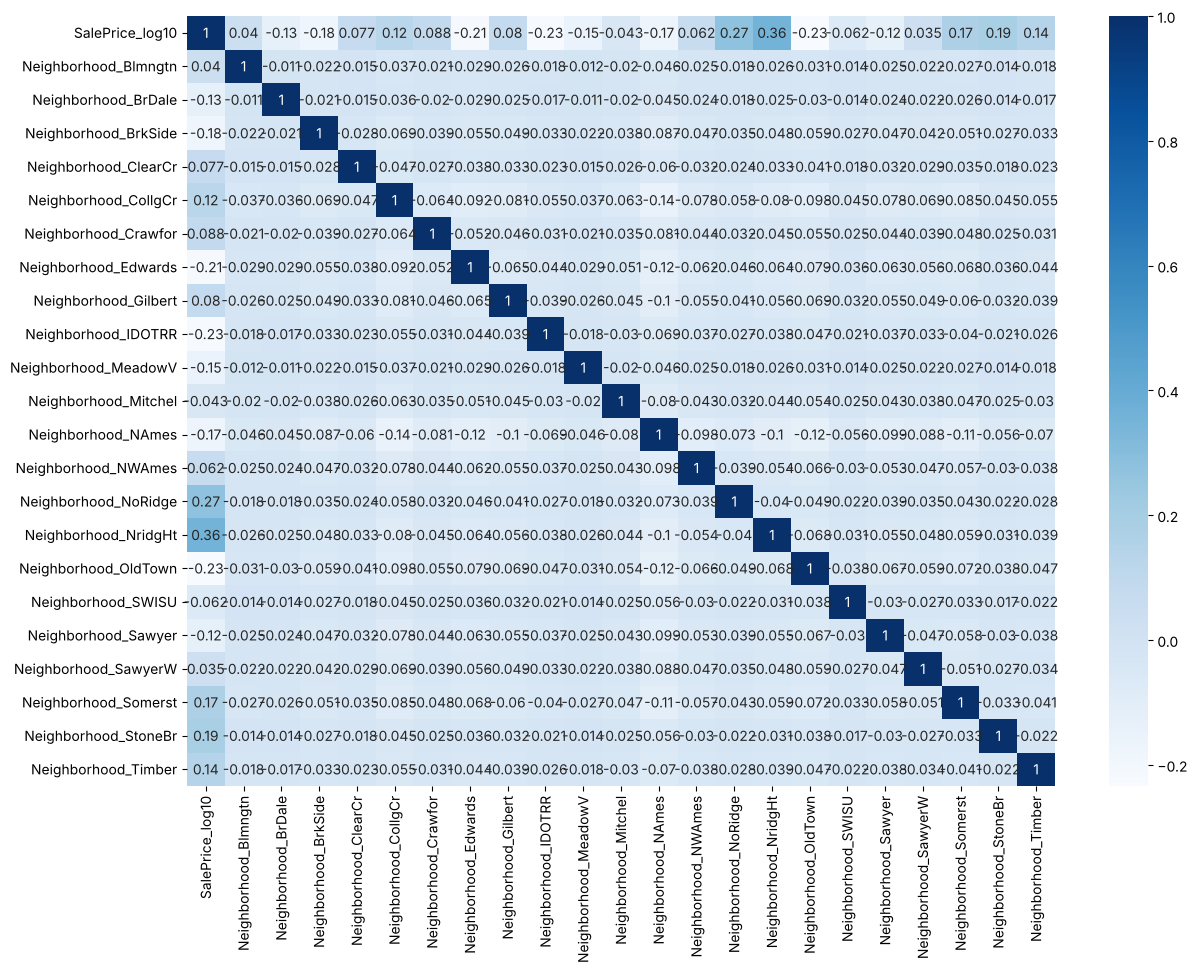

In [90]:
plt.figure(figsize=(14,10))
sns.heatmap(col6.corr(), annot = True, cmap="Blues")   
plt.show() 

Neighborhood is a strong predictor of SalePrice, as housing prices vary significantly across different locations. Nbhd_NridgHt shows the strongest positive correlation (0.35), indicating that homes in this neighborhood tend to have higher prices. In contrast, Nbhd_OldTown has a negative correlation (-0.23), suggesting that homes in this area are generally associated with lower prices.

## OverallQual

### Descriptive Stats

In [91]:
df.OverallQual.value_counts(normalize = True)

OverallQual
5     0.271918
6     0.256164
7     0.218493
8     0.115068
4     0.079452
9     0.029452
3     0.013699
10    0.012329
2     0.002055
1     0.001370
Name: proportion, dtype: float64

In [92]:
df.OverallQual.isna().sum()

np.int64(0)

No missing value and there are underpresented valye

### Univariate

OverallQual
5     397
6     374
7     319
8     168
4     116
9      43
3      20
10     18
2       3
1       2
Name: count, dtype: int64

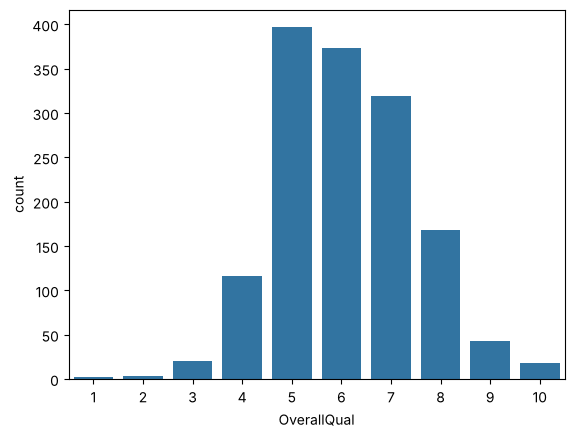

In [93]:
sns.countplot(x= 'OverallQual', data= df, order = sorted(df['OverallQual'].unique(), key=int))
df['OverallQual'].value_counts(normalize = False).round(2)

### Bivariate 

<Axes: xlabel='OverallQual', ylabel='SalePrice_log10'>

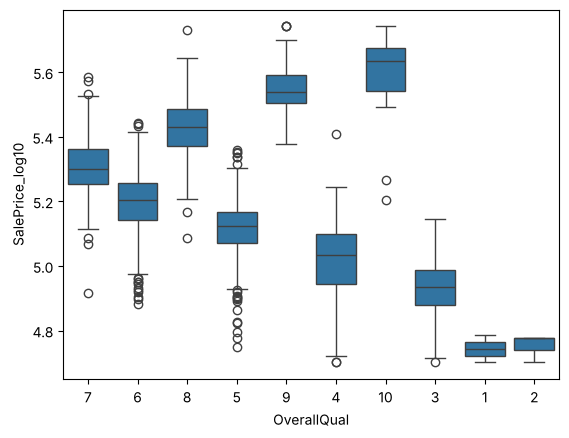

In [94]:
sns.boxplot(x = "OverallQual", y = "SalePrice_log10", data = df)

There are a lot of different quality in SalePrice. Most homes have a typical ("TA") garage quality rating, while poor ("Po"), fair ("Fa"), good ("Gd"), and excellent ("Ex") ratings are rare. The bivariate boxplot shows that typical quality garages dominate the mid-price range, while higher-quality garages are associated with higher sale prices. Low-quality categories (Po, Fa) are sparse and show similar price distributions, making them candidates for merging.

### Cleaning

In [95]:
overall_map = {
    "1": "3 or less",
    "2": "3 or less",
    "3": "3 or less",
    "4": "4",
    "5" : "5",
    "6":"6",
    "7":"7",
    "8":"8",
    "9":"9",
    "10":"10",
}
df["OverallQual"] = df["OverallQual"].map(overall_map)
print("\nCounts after mapping:")
display(df["OverallQual"].value_counts(dropna=False))


Counts after mapping:


OverallQual
5            397
6            374
7            319
8            168
4            116
9             43
3 or less     25
10            18
Name: count, dtype: int64

OverallQual
5            397
6            374
7            319
8            168
4            116
9             43
3 or less     25
10            18
Name: count, dtype: int64

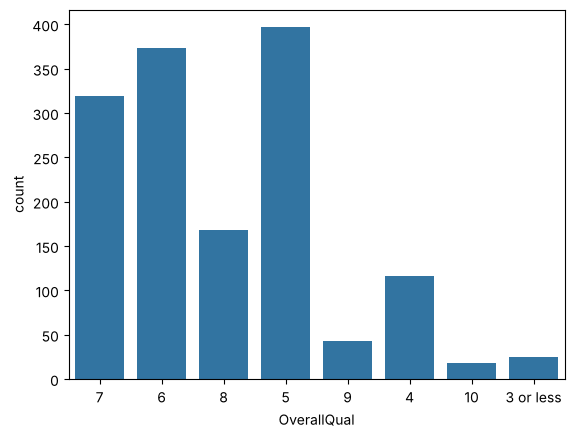

In [96]:
sns.countplot(x='OverallQual',data=df)
df['OverallQual'].value_counts(normalize = False).round(2)

<Axes: xlabel='OverallQual', ylabel='SalePrice_log10'>

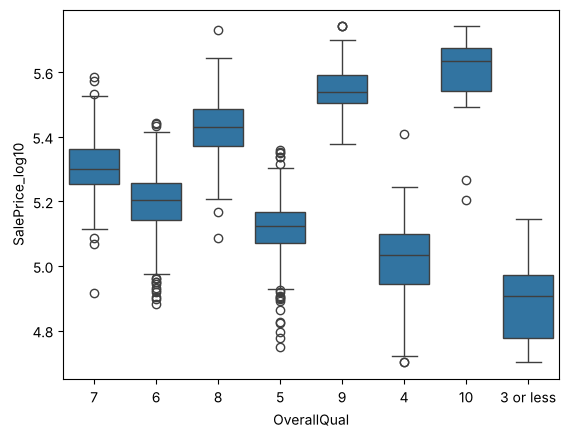

In [97]:
sns.boxplot(x = 'OverallQual', y = 'SalePrice_log10', data = df)

In [98]:
#One-hot coding

dummies = pd.get_dummies(df["OverallQual"], prefix="OverallQual", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["OverallQual"]), dummies], axis=1)
display(df.head())

,OverallQual_10,OverallQual_3 or less,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9
0,0,0,0,0,0,1,0,0
1,0,0,0,0,1,0,0,0
2,0,0,0,0,0,1,0,0
3,0,0,0,0,0,1,0,0
4,0,0,0,0,0,0,1,0


,SalePrice,LotFrontage,LotArea,ExterQual,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,...,Neighborhood_StoneBr,Neighborhood_Timber,OverallQual_10,OverallQual_3 or less,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9
0,208500,65.0,8450,Gd,0,NaN,Attchd,2003.0,RFn,2,...,0,0,0,0,0,0,0,1,0,0
1,181500,80.0,9600,TA,1,TA,Attchd,1976.0,RFn,2,...,0,0,0,0,0,0,1,0,0,0
2,223500,68.0,11250,Gd,1,TA,Attchd,2001.0,RFn,2,...,0,0,0,0,0,0,0,1,0,0
3,140000,60.0,9550,TA,1,Gd,Detchd,1998.0,Unf,3,...,0,0,0,0,0,0,0,1,0,0
4,250000,84.0,14260,Gd,1,TA,Attchd,2000.0,RFn,3,...,0,0,0,0,0,0,0,0,1,0


### Correlation

In [99]:
col7 = df[['SalePrice_log10','OverallQual_10','OverallQual_3 or less','OverallQual_4','OverallQual_5','OverallQual_6','OverallQual_7','OverallQual_8','OverallQual_9']]

col7.corr()['SalePrice_log10']

SalePrice_log10          1.000000
OverallQual_10           0.242804
OverallQual_3 or less   -0.253440
OverallQual_4           -0.344779
OverallQual_5           -0.378312
OverallQual_6           -0.085144
OverallQual_7            0.264937
OverallQual_8            0.432869
OverallQual_9            0.338412
Name: SalePrice_log10, dtype: float64

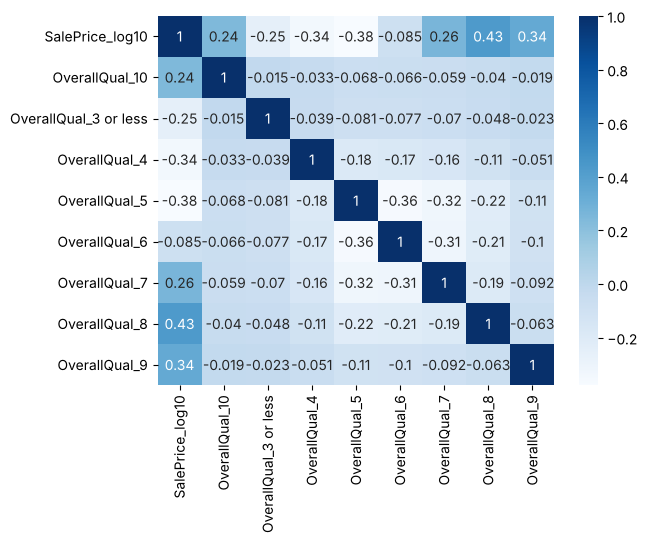

In [100]:
sns.heatmap(col7.corr(), annot = True, cmap="Blues")   
plt.show() 


OverallQual is a strong predictor of SalePrice, as different quality ratings are associated with different price levels. OverallQual_8 shows the strongest positive correlation (0.43), indicating that higher-quality homes tend to have higher prices. In contrast, OverallQual_5 has the strongest negative correlation (-0.37), suggesting lower-quality homes are associated with lower prices.

Since the categories exhibit moderate to strong relationships with SalePrice, this variable is important and should be included in the model.

## ExterQual (Categorical)

### Descriptive Stats

In [101]:
df.ExterQual.value_counts(normalize = True)

ExterQual
TA    0.620548
Gd    0.334247
Ex    0.035616
Fa    0.009589
Name: proportion, dtype: float64

### Univariate

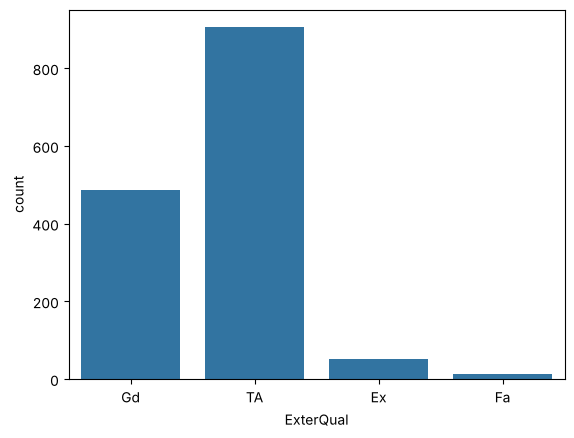

In [102]:
sns.countplot(x= 'ExterQual', data= df)
plt.show()


### Bivariate

<Axes: xlabel='ExterQual', ylabel='SalePrice_log10'>

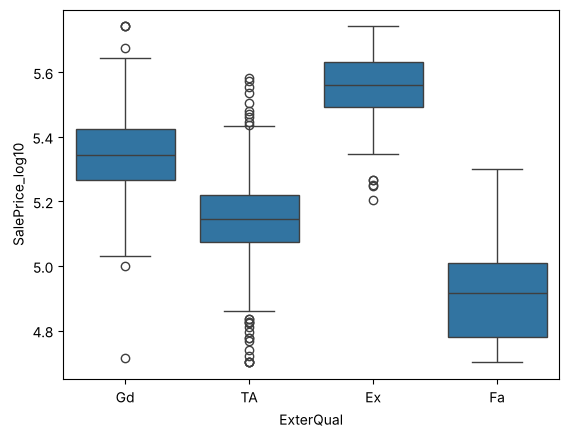

In [103]:
sns.boxplot(x = "ExterQual", y = "SalePrice_log10", data = df)

Different in rating of the SalePrice

### Cleaning

In [104]:
exmap = {
    "Gd": "Gd",
    "TA": "TA",
    "Fa": "TA",
    "Ex": "Ex",
}
df["ExterQual"] = df["ExterQual"].map(exmap)
print("\nCounts after mapping:")
display(df["ExterQual"].value_counts(dropna=False))


Counts after mapping:


ExterQual
TA    920
Gd    488
Ex     52
Name: count, dtype: int64

Fa is underrepresented. Since this is an ordinal variable, Fa is merged with TA, the nearest adjacent category in the ranking (Fa < TA < Gd < Ex).

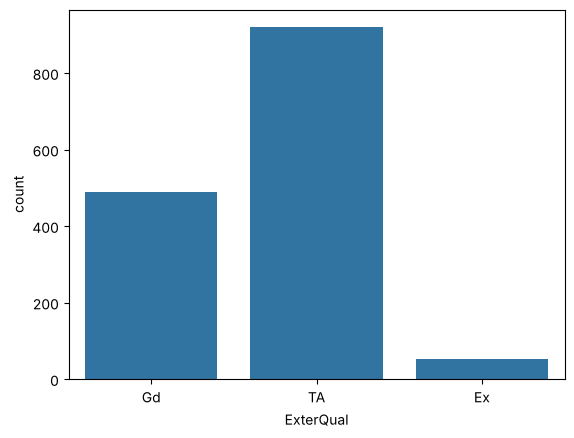

<Axes: xlabel='ExterQual', ylabel='SalePrice_log10'>

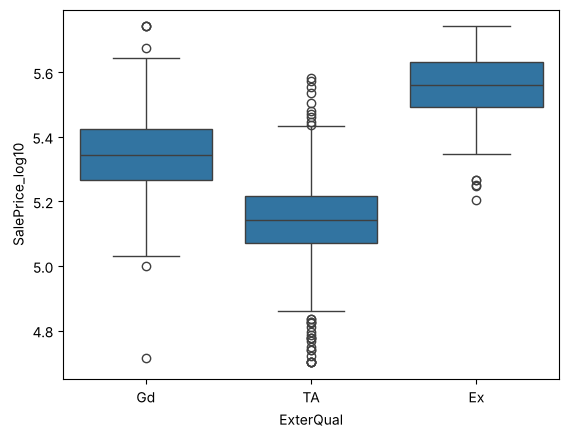

In [105]:
sns.countplot(x='ExterQual',data=df)
plt.show()
sns.boxplot(x = 'ExterQual', y = 'SalePrice_log10', data = df)

In [106]:
#One-hot coding

dummies = pd.get_dummies(df["ExterQual"], prefix="ExterQual", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["ExterQual"]), dummies], axis=1)
display(df.head())

,ExterQual_Ex,ExterQual_Gd,ExterQual_TA
0,0,1,0
1,0,0,1
2,0,1,0
3,0,0,1
4,0,1,0


,SalePrice,LotFrontage,LotArea,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,...,OverallQual_3 or less,OverallQual_4,OverallQual_5,OverallQual_6,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Gd,ExterQual_TA
0,208500,65.0,8450,0,NaN,Attchd,2003.0,RFn,2,548,...,0,0,0,0,1,0,0,0,1,0
1,181500,80.0,9600,1,TA,Attchd,1976.0,RFn,2,460,...,0,0,0,1,0,0,0,0,0,1
2,223500,68.0,11250,1,TA,Attchd,2001.0,RFn,2,608,...,0,0,0,0,1,0,0,0,1,0
3,140000,60.0,9550,1,Gd,Detchd,1998.0,Unf,3,642,...,0,0,0,0,1,0,0,0,0,1
4,250000,84.0,14260,1,TA,Attchd,2000.0,RFn,3,836,...,0,0,0,0,0,1,0,0,1,0


### Correlation 

In [107]:
col8 = df[['SalePrice_log10','ExterQual_Ex','ExterQual_Gd','ExterQual_TA']]

col8.corr()['SalePrice_log10']

SalePrice_log10    1.000000
ExterQual_Ex       0.356490
ExterQual_Gd       0.514498
ExterQual_TA      -0.639586
Name: SalePrice_log10, dtype: float64

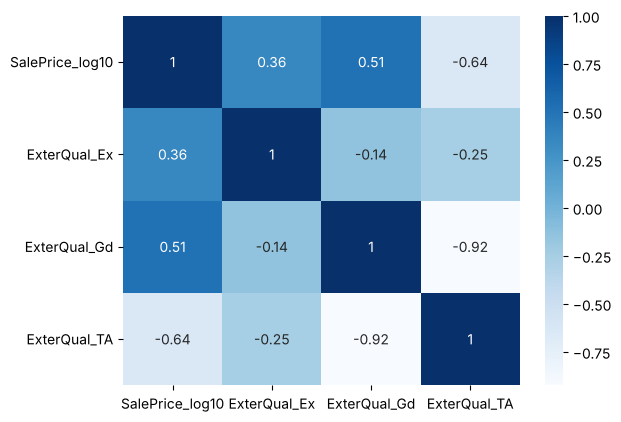

In [108]:
sns.heatmap(col8.corr(), annot = True, cmap="Blues")   
plt.show() 

Exterior Quality is a strong predictor of SalePrice. Each category shows a clear relationship with the dependent variable: houses with Typical/Average (TA) quality tend to have lower prices, while Good (Gd) and Excellent (Ex) quality are associated with higher prices. Therefore, this variable should be included in modeling.
When using one-hot encoding, ExterQual_Gd and ExterQual_TA should not both be included simultaneously without dropping a reference category, as they are highly (near perfectly) negatively correlated. This can lead to multicollinearity. To avoid this, one category (e.g., TA) should be used as the baseline.

## Fireplaces (Categorical)

### Descriptive Stats

In [109]:
df.Fireplaces.isna().sum()

np.int64(0)

In [110]:
df.Fireplaces.value_counts(normalize = True) 

Fireplaces
0    0.472603
1    0.445205
2    0.078767
3    0.003425
Name: proportion, dtype: float64

No missing value and have underrepresented category

### Univariate

<Axes: xlabel='Fireplaces', ylabel='count'>

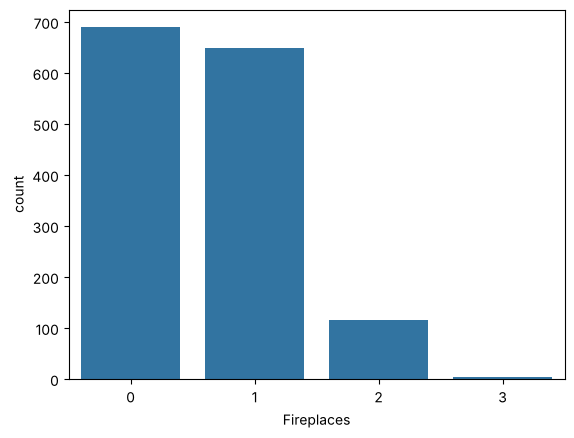

In [111]:
sns.countplot (x = "Fireplaces", data = df)


### Bivariate

<Axes: xlabel='Fireplaces', ylabel='SalePrice_log10'>

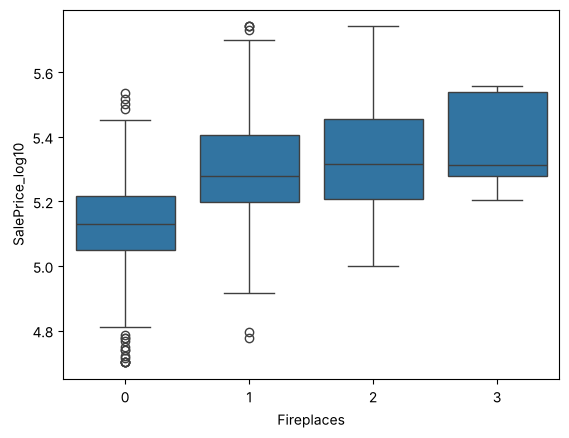

In [112]:
sns.boxplot  (x = "Fireplaces", y = "SalePrice_log10", data = df)

### Cleaning

In [113]:
fire = df['Fireplaces'].value_counts(normalize=True)
fireplaces = fire[fire < 0.01].index.tolist()
fireplaces

['3']

In [114]:
df["Fireplaces"]=df["Fireplaces"].apply(lambda x: "2 or More" if x in fireplaces else x)
df["Fireplaces"] 

0       0
1       1
2       1
3       1
4       1
       ..
1455    1
1456    2
1457    2
1458    0
1459    0
Name: Fireplaces, Length: 1460, dtype: str

In [115]:
df.Fireplaces.value_counts(normalize = True)

Fireplaces
0            0.472603
1            0.445205
2            0.078767
2 or More    0.003425
Name: proportion, dtype: float64

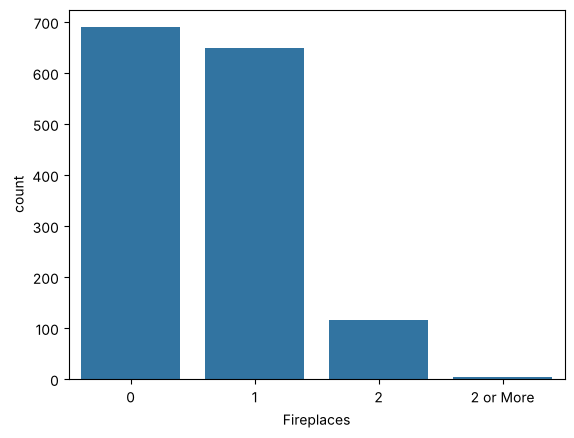

<Axes: xlabel='Fireplaces', ylabel='SalePrice_log10'>

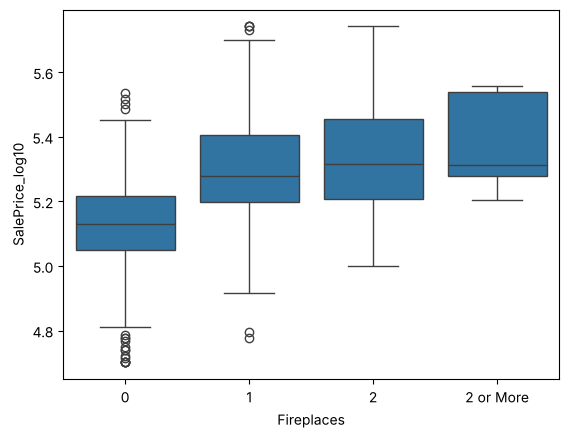

In [116]:
sns.countplot (x = "Fireplaces", data = df)
plt.show()
sns.boxplot ( x = "Fireplaces", y = "SalePrice_log10", data = df)

After cleaning, the range is not so different 

In [117]:
#One-hot coding
dummies = pd.get_dummies(df["Fireplaces"], prefix="NumFireplaces", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["Fireplaces"]), dummies], axis=1)
display(df.head())

,NumFireplaces_0,NumFireplaces_1,NumFireplaces_2,NumFireplaces_2 or More
0,1,0,0,0
1,0,1,0,0
2,0,1,0,0
3,0,1,0,0
4,0,1,0,0


,SalePrice,LotFrontage,LotArea,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,...,OverallQual_7,OverallQual_8,OverallQual_9,ExterQual_Ex,ExterQual_Gd,ExterQual_TA,NumFireplaces_0,NumFireplaces_1,NumFireplaces_2,NumFireplaces_2 or More
0,208500,65.0,8450,NaN,Attchd,2003.0,RFn,2,548,TA,...,1,0,0,0,1,0,1,0,0,0
1,181500,80.0,9600,TA,Attchd,1976.0,RFn,2,460,TA,...,0,0,0,0,0,1,0,1,0,0
2,223500,68.0,11250,TA,Attchd,2001.0,RFn,2,608,TA,...,1,0,0,0,1,0,0,1,0,0
3,140000,60.0,9550,Gd,Detchd,1998.0,Unf,3,642,TA,...,1,0,0,0,0,1,0,1,0,0
4,250000,84.0,14260,TA,Attchd,2000.0,RFn,3,836,TA,...,0,1,0,0,1,0,0,1,0,0


### Correlation

In [118]:
col9 = df[['SalePrice_log10','NumFireplaces_0','NumFireplaces_1','NumFireplaces_2 or More']]

col9.corr()['SalePrice_log10']

SalePrice_log10            1.000000
NumFireplaces_0           -0.512949
NumFireplaces_1            0.400200
NumFireplaces_2 or More    0.053331
Name: SalePrice_log10, dtype: float64

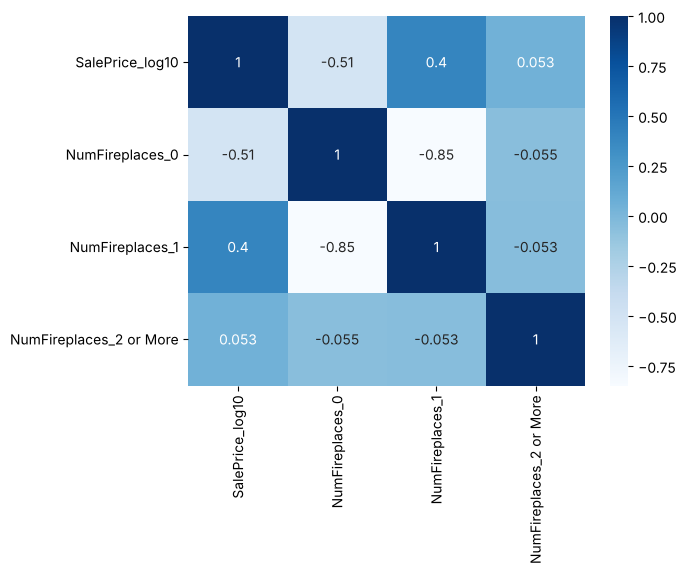

In [119]:
sns.heatmap(col9.corr(), annot = True, cmap="Blues")  
plt.show() 

The number of fireplaces is a useful predictor of SalePrice. The variable shows a meaningful relationship with the dependent variable: houses with no fireplaces tend to have lower prices (strong negative correlation), while houses with one or more fireplaces show positive correlations with SalePrice. In particular, 1 fireplace (~ 0.40) and multiple fireplaces (~ 0.21) are associated with higher prices.
When using one-hot encoding, NumFireplaces_0 and NumFireplaces_1 should not both be included without dropping a reference category, as they are highly negatively correlated. To avoid multicollinearity, one category (typically 0 fireplaces) should be used as the baseline.

## FireplaceQu (Categorical)

### Descriptive Stats

In [120]:
df.FireplaceQu.isna().sum()

np.int64(690)

In [121]:
df.FireplaceQu.value_counts(normalize = True)

FireplaceQu
Gd    0.493506
TA    0.406494
Fa    0.042857
Ex    0.031169
Po    0.025974
Name: proportion, dtype: float64

690 missing values and underrepresent value

### Univariate

<Axes: xlabel='FireplaceQu', ylabel='count'>

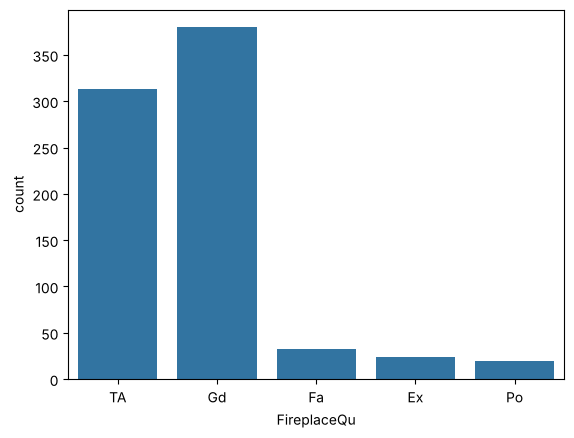

In [122]:
sns.countplot(x = "FireplaceQu", data = df)

### Bivariate

<Axes: xlabel='FireplaceQu', ylabel='SalePrice_log10'>

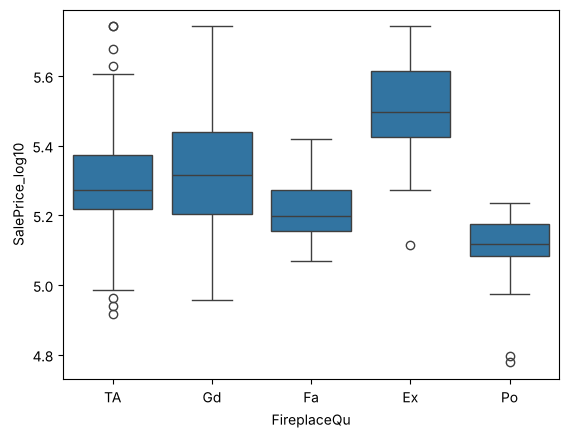

In [123]:
sns.boxplot(x = "FireplaceQu", y ="SalePrice_log10", data = df)

### Cleaning 

In [124]:
df['FireplaceQu'] = df['FireplaceQu'].fillna("None")
df.FireplaceQu.isna().sum()

np.int64(0)

In [125]:
df.FireplaceQu.value_counts()

FireplaceQu
None    690
Gd      380
TA      313
Fa       33
Ex       24
Po       20
Name: count, dtype: int64

Exceptional (Ex) is the least represented category, but it should be kept as a separate level since it represents the highest quality ranking and shows distinct behavior.
Typical/Average (TA) and Good (Gd) have similar medians and overall ranges of SalePrice, although both categories exhibit some extreme outliers. Their distributions are relatively comparable, suggesting potential similarity in pricing behavior.
Exceptional (Ex) shows the widest IQR, indicating greater variability in SalePrice among high-quality houses.
The newly created None category has a median SalePrice similar to houses with Fair (Fa) quality, suggesting these two categories may represent comparable lower-end conditions.

<Axes: xlabel='FireplaceQu', ylabel='SalePrice_log10'>

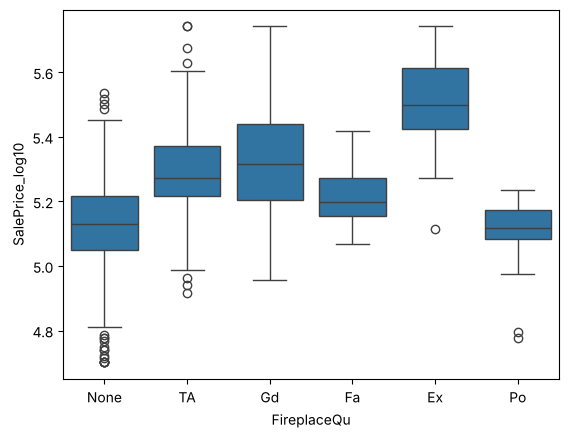

In [126]:
sns.boxplot(x="FireplaceQu", y="SalePrice_log10", data=df)

In [127]:
#One-hot coding
dummies = pd.get_dummies(df["FireplaceQu"], prefix="FireplaceQu", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["FireplaceQu"]), dummies], axis=1)
display(df.head())

,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA
0,0,0,0,1,0,0
1,0,0,0,0,0,1
2,0,0,0,0,0,1
3,0,0,1,0,0,0
4,0,0,0,0,0,1


,SalePrice,LotFrontage,LotArea,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,...,NumFireplaces_0,NumFireplaces_1,NumFireplaces_2,NumFireplaces_2 or More,FireplaceQu_Ex,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA
0,208500,65.0,8450,Attchd,2003.0,RFn,2,548,TA,TA,...,1,0,0,0,0,0,0,1,0,0
1,181500,80.0,9600,Attchd,1976.0,RFn,2,460,TA,TA,...,0,1,0,0,0,0,0,0,0,1
2,223500,68.0,11250,Attchd,2001.0,RFn,2,608,TA,TA,...,0,1,0,0,0,0,0,0,0,1
3,140000,60.0,9550,Detchd,1998.0,Unf,3,642,TA,TA,...,0,1,0,0,0,0,1,0,0,0
4,250000,84.0,14260,Attchd,2000.0,RFn,3,836,TA,TA,...,0,1,0,0,0,0,0,0,0,1


### Correlation

In [128]:
col10 = df[['SalePrice_log10','FireplaceQu_Ex','FireplaceQu_Fa','FireplaceQu_Gd','FireplaceQu_None','FireplaceQu_TA']]

col10.corr()['SalePrice_log10']

SalePrice_log10     1.000000
FireplaceQu_Ex      0.207655
FireplaceQu_Fa     -0.006154
FireplaceQu_Gd      0.348912
FireplaceQu_None   -0.512949
FireplaceQu_TA      0.213059
Name: SalePrice_log10, dtype: float64

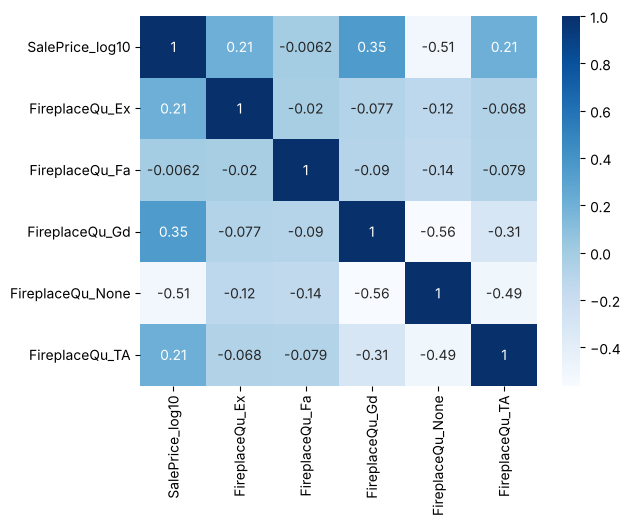

In [129]:
sns.heatmap(col10.corr(), annot = True, cmap="Blues")  
plt.show() 

Fireplace quality is a useful predictor of SalePrice. The variable shows a clear relationship with the dependent variable: houses with no fireplace (None) have a strong negative correlation with SalePrice (−0.47), indicating they tend to have lower prices. In contrast, houses with Good (Gd) and Excellent (Ex) fireplace quality are associated with higher SalePrices, suggesting that better fireplace quality contributes positively to house value.

## BedroomAbvGr (Categorical)

### Descriptive Stats

In [130]:
df.BedroomAbvGr.isna().sum()

np.int64(0)

No missing value

In [131]:
df.BedroomAbvGr.astype("object")

0       3
1       3
2       3
3       3
4       4
       ..
1455    3
1456    3
1457    4
1458    2
1459    3
Name: BedroomAbvGr, Length: 1460, dtype: object

In [132]:
df.BedroomAbvGr.value_counts(normalize = True)

BedroomAbvGr
3    0.550685
2    0.245205
4    0.145890
1    0.034247
5    0.014384
6    0.004795
0    0.004110
8    0.000685
Name: proportion, dtype: float64

### Univariate

<Axes: xlabel='BedroomAbvGr', ylabel='count'>

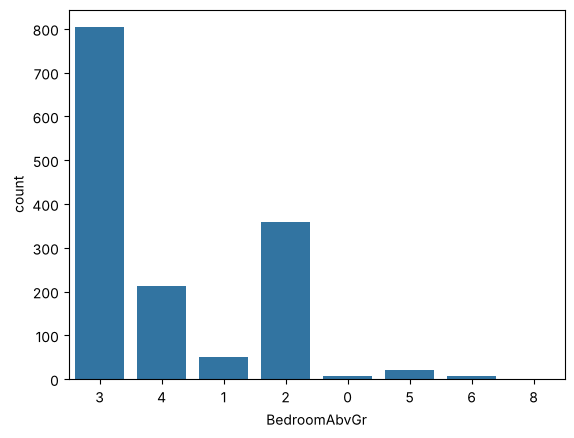

In [133]:
sns.countplot(x = "BedroomAbvGr", data = df)

The countplot shows that most homes have 3 bedrooms above grade, followed by 2 and 4 bedrooms. Homes with 0, 5, 6, or 8 bedrooms are very rare, making these categories too sparse to model reliably and candidates for grouping during cleaning.

### Bivariate

<Axes: xlabel='BedroomAbvGr', ylabel='SalePrice_log10'>

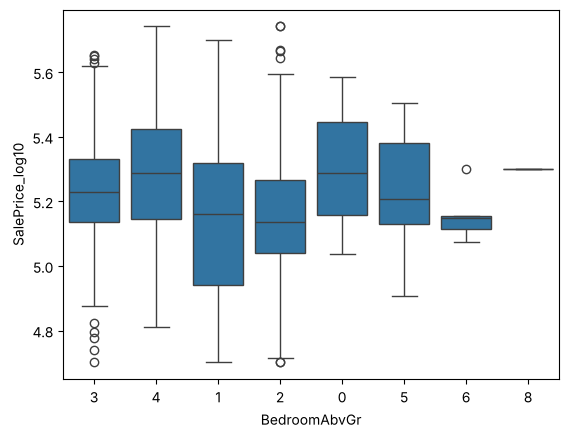

In [134]:
sns.boxplot(x = "BedroomAbvGr", y = "SalePrice_log10", data = df)

The boxplot reveals a non-linear relationship between bedroom count and SalePrice. Homes with 3–4 bedrooms tend to have the highest median prices, while homes with 0–1 bedrooms show lower prices. Surprisingly, homes with 5+ bedrooms do not command significantly higher prices, suggesting that beyond a certain point, more bedrooms do not add value — possibly because very large bedroom counts are associated with older or subdivided properties.

### Cleaning

In [135]:
df.loc[df['BedroomAbvGr'] == "0", 'BedroomAbvGr'] = "1"

In [136]:
df['BedroomAbvGr'].unique()

<StringArray>
['3', '4', '1', '2', '5', '6', '8']
Length: 7, dtype: str

In [137]:
bed_map = {
    "1":"1",
    "2":"2",
    "3":"3",
    "4":"4",
    "5":"5 or more",
    "6":"5 or more",
    "8":"5 or more",
}
df["BedroomAbvGr"] = df["BedroomAbvGr"].map(bed_map)
print("\nCounts after mapping:")
display(df["BedroomAbvGr"].value_counts(dropna=False, normalize=True))


Counts after mapping:


BedroomAbvGr
3            0.550685
2            0.245205
4            0.145890
1            0.038356
5 or more    0.019863
Name: proportion, dtype: float64

The value 0 bedrooms was merged into the "1" category since a home with no bedrooms is extremely rare and likely a data anomaly. Categories 5, 6, and 8 were grouped into "5 or more" due to very low frequency. This reduces sparsity while preserving the meaningful ordinal structure of the variable.

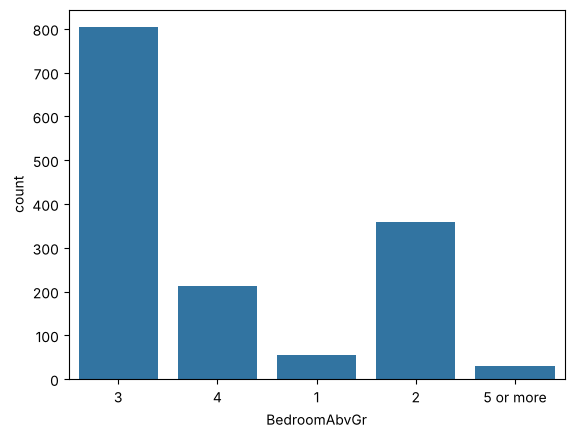

<Axes: xlabel='BedroomAbvGr', ylabel='SalePrice_log10'>

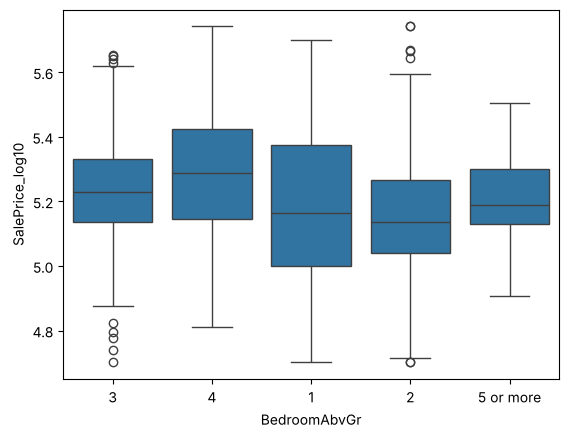

In [138]:
sns.countplot(x = "BedroomAbvGr", data = df)
plt.show()
sns.boxplot(x = "BedroomAbvGr", y = "SalePrice_log10", data = df)

In [139]:
#One-hot coding
dummies = pd.get_dummies(df["BedroomAbvGr"], prefix="BedroomAbvGr", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["BedroomAbvGr"]), dummies], axis=1)
display(df.head())

,BedroomAbvGr_1,BedroomAbvGr_2,BedroomAbvGr_3,BedroomAbvGr_4,BedroomAbvGr_5 or more
0,0,0,1,0,0
1,0,0,1,0,0
2,0,0,1,0,0
3,0,0,1,0,0
4,0,0,0,1,0


,SalePrice,LotFrontage,LotArea,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,...,FireplaceQu_Fa,FireplaceQu_Gd,FireplaceQu_None,FireplaceQu_Po,FireplaceQu_TA,BedroomAbvGr_1,BedroomAbvGr_2,BedroomAbvGr_3,BedroomAbvGr_4,BedroomAbvGr_5 or more
0,208500,65.0,8450,Attchd,2003.0,RFn,2,548,TA,TA,...,0,0,1,0,0,0,0,1,0,0
1,181500,80.0,9600,Attchd,1976.0,RFn,2,460,TA,TA,...,0,0,0,0,1,0,0,1,0,0
2,223500,68.0,11250,Attchd,2001.0,RFn,2,608,TA,TA,...,0,0,0,0,1,0,0,1,0,0
3,140000,60.0,9550,Detchd,1998.0,Unf,3,642,TA,TA,...,0,1,0,0,0,0,0,1,0,0
4,250000,84.0,14260,Attchd,2000.0,RFn,3,836,TA,TA,...,0,0,0,0,1,0,0,0,1,0


### Correlation

In [140]:
col11 = df[['SalePrice_log10','BedroomAbvGr_1','BedroomAbvGr_2','BedroomAbvGr_3','BedroomAbvGr_4','BedroomAbvGr_5 or more']]

col11.corr()['SalePrice_log10']

SalePrice_log10           1.000000
BedroomAbvGr_1           -0.044043
BedroomAbvGr_2           -0.213085
BedroomAbvGr_3            0.072302
BedroomAbvGr_4            0.185282
BedroomAbvGr_5 or more   -0.008878
Name: SalePrice_log10, dtype: float64

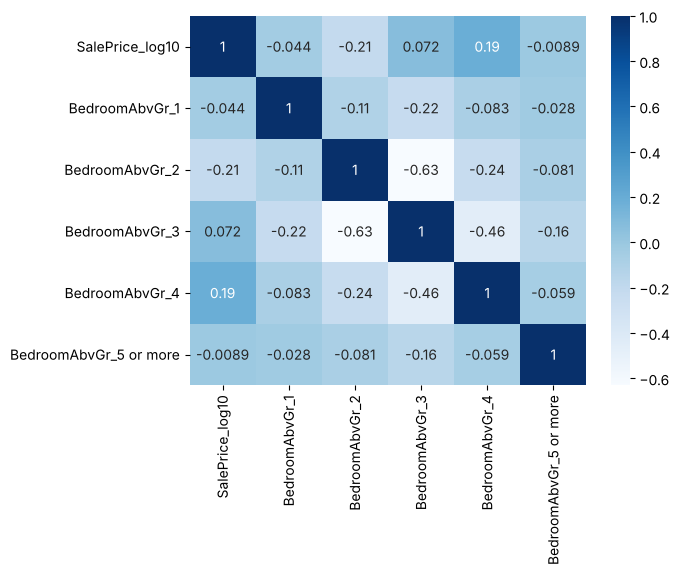

In [141]:
sns.heatmap(col11.corr(), annot = True, cmap="Blues")  
plt.show() 

## Bathroom (All Categorical)

### Descriptive Stats

In [142]:
df[["BsmtFullBath","BsmtHalfBath","FullBath","HalfBath"]].astype("object")

,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath
0,1,0,2,1
1,0,1,2,0
2,1,0,2,1
3,1,0,1,0
4,1,0,2,1
...,...,...,...,...
1455,0,0,2,1
1456,1,0,2,0
1457,0,0,2,0
1458,1,0,1,0


In [143]:
df[["BsmtFullBath","BsmtHalfBath","FullBath","HalfBath"]].isna().sum()

BsmtFullBath    0
BsmtHalfBath    0
FullBath        0
HalfBath        0
dtype: int64

In [144]:
df.BsmtFullBath.value_counts(normalize = True)

BsmtFullBath
0    0.586301
1    0.402740
2    0.010274
3    0.000685
Name: proportion, dtype: float64

In [145]:
df.BsmtHalfBath.value_counts(normalize = True)

BsmtHalfBath
0    0.943836
1    0.054795
2    0.001370
Name: proportion, dtype: float64

In [146]:
df.FullBath.value_counts(normalize = True)

FullBath
2    0.526027
1    0.445205
3    0.022603
0    0.006164
Name: proportion, dtype: float64

In [147]:
df.HalfBath.value_counts(normalize = True)

HalfBath
0    0.625342
1    0.366438
2    0.008219
Name: proportion, dtype: float64

### Univariate + Bivariate

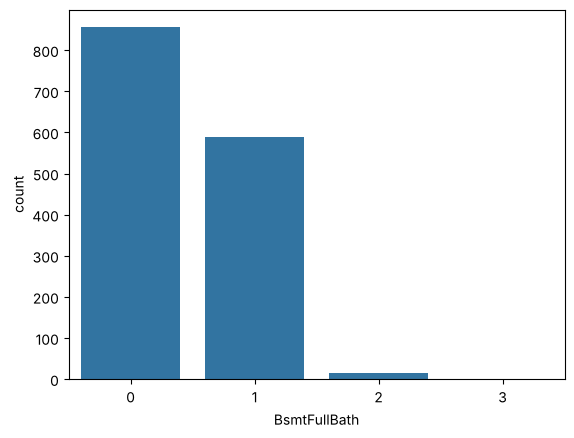

<Axes: xlabel='BsmtFullBath', ylabel='SalePrice_log10'>

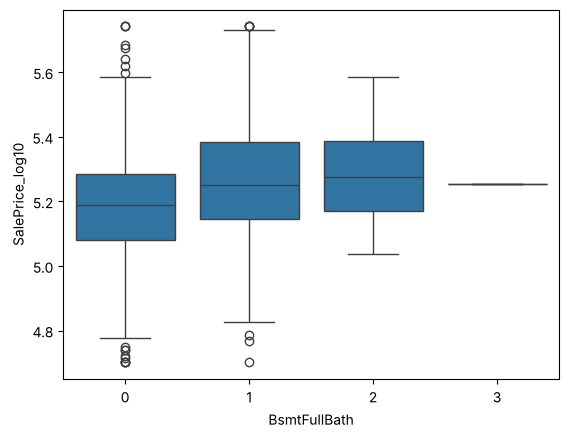

In [148]:
sns.countplot( x = "BsmtFullBath", data = df)

plt.show()
sns.boxplot ( x = "BsmtFullBath", y = "SalePrice_log10", data = df)

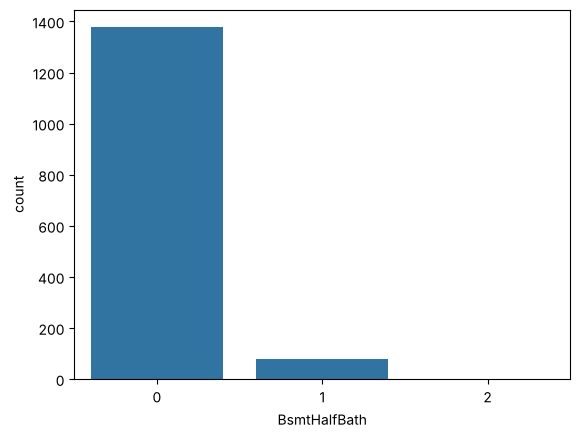

<Axes: xlabel='BsmtHalfBath', ylabel='SalePrice_log10'>

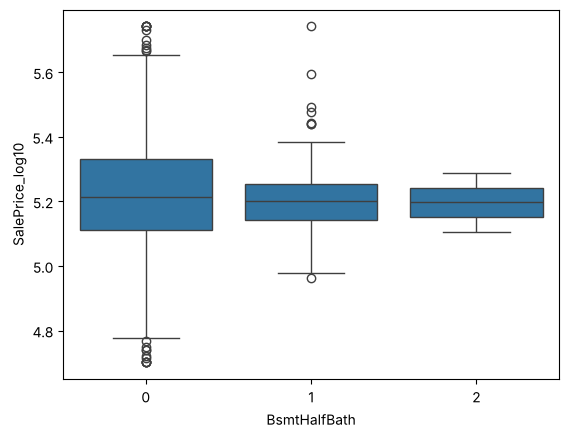

In [149]:
sns.countplot(x = "BsmtHalfBath", data = df)
plt.show()
sns.boxplot( x = "BsmtHalfBath", y = "SalePrice_log10", data = df)

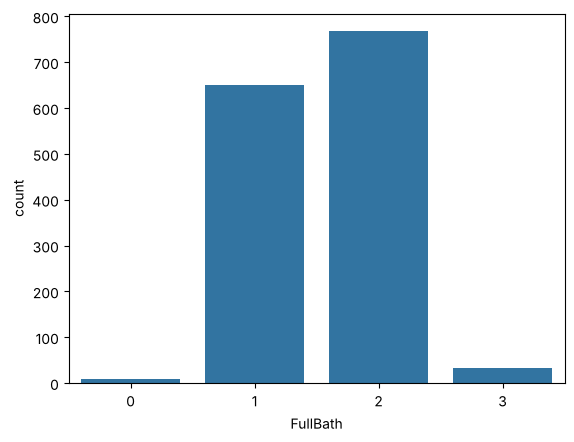

<Axes: xlabel='FullBath', ylabel='SalePrice_log10'>

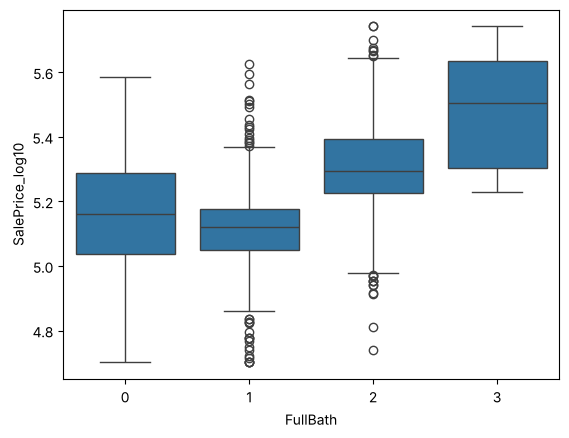

In [150]:
sns.countplot(x = "FullBath", data = df)
plt.show()
sns.boxplot( x = "FullBath", y = "SalePrice_log10", data = df)

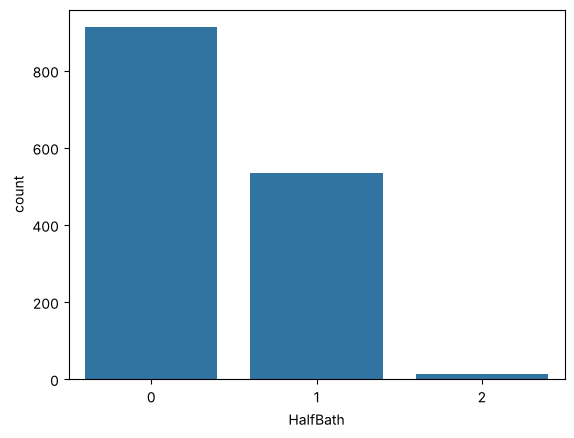

<Axes: xlabel='HalfBath', ylabel='SalePrice_log10'>

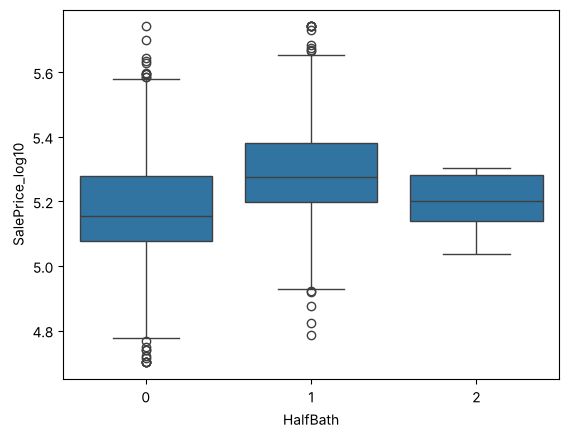

In [151]:
sns.countplot(x = "HalfBath", data = df)
plt.show()
sns.boxplot( x = "HalfBath", y = "SalePrice_log10", data = df)

Exploring all four bathroom variables individually revealed the following. BsmtFullBath is dominated by 0 and 1 values, with homes having 1 basement full bathroom showing slightly higher prices. BsmtHalfBath is heavily skewed toward 0, meaning most homes have no basement half bath, and its relationship with SalePrice is weak. FullBath shows a clearer positive trend, houses with 2 full bathrooms above grade are most common and associated with higher prices than homes with only 1. HalfBath shows a modest positive relationship, with homes having 1 half bathroom selling at slightly higher prices than those with none. Because the individual bathroom counts are sparse and overlapping, they are combined into TotalFullBath and TotalHalfBath for cleaner analysis.

## Total Full Bathroom

In [152]:
df["TotalFullBath"] = df["BsmtFullBath"] + df["FullBath"]

In [153]:
df.TotalFullBath.value_counts(normalize = True)

TotalFullBath
2    0.513699
1    0.254110
3    0.218493
4    0.012329
0    0.000685
6    0.000685
Name: proportion, dtype: float64

In [154]:
df.TotalFullBath.isna().sum()

np.int64(0)

### Univariate + Bivariate 

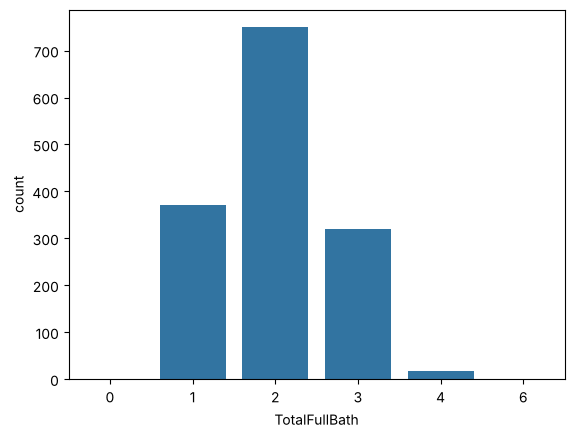

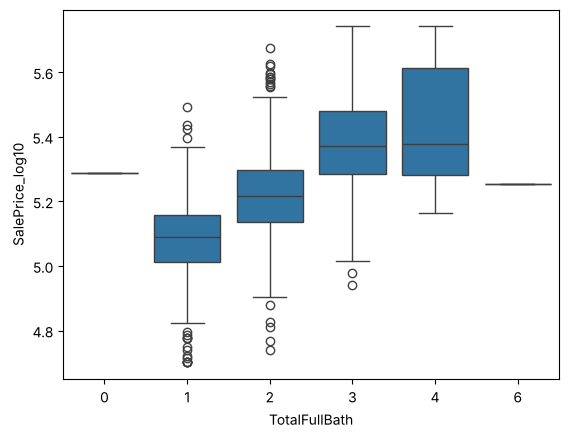

In [155]:
sns.countplot(x="TotalFullBath", data=df)
plt.show()
sns.boxplot(x="TotalFullBath", y="SalePrice_log10", data=df)
plt.show()

### Cleaning 

In [156]:
df.loc[df['TotalFullBath'] == 0, 'TotalFullBath'] = 1

In [157]:
df["TotalFullBath"] = df["TotalFullBath"].astype(str)
bath_map = {
    "1": "1",
    "2": "2",
    "3": "3",
    "4": "4 or more",
    "6": "4 or more"
}

df["TotalFullBath"] = df["TotalFullBath"].map(bath_map)

print("\nCounts after mapping:")
display(df["TotalFullBath"].value_counts(normalize=True))


Counts after mapping:


TotalFullBath
2            0.513699
1            0.254795
3            0.218493
4 or more    0.013014
Name: proportion, dtype: float64

In [158]:
df.TotalFullBath.value_counts()

TotalFullBath
2            750
1            372
3            319
4 or more     19
Name: count, dtype: int64

The TotalFullBath variable was grouped to reduce sparsity in higher values. Categories with very low frequency (4 or more bathrooms) were combined into a single group labeled "4 or more". This helps improve interpretability and avoids issues with extremely small categories.

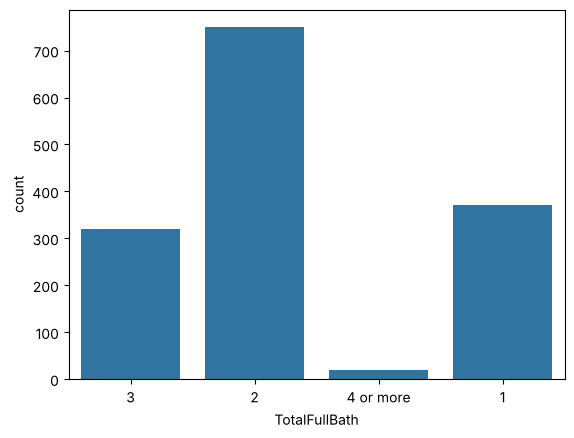

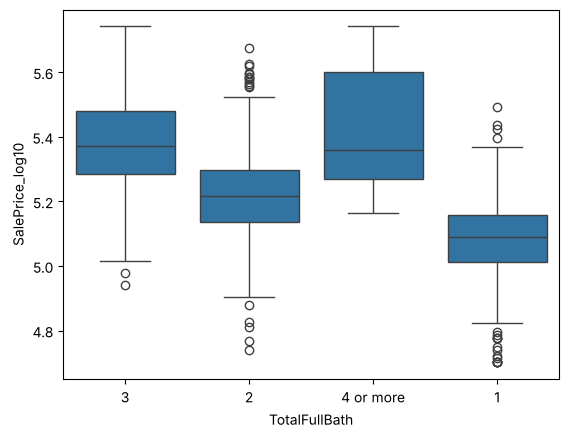

In [159]:
sns.countplot(x="TotalFullBath", data=df)
plt.show()
sns.boxplot(x="TotalFullBath", y="SalePrice_log10", data=df)
plt.show()

In [160]:
#One-hot coding
dummies = pd.get_dummies(df["TotalFullBath"], prefix="TotalFullBath", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["TotalFullBath"]), dummies], axis=1)
display(df.head())

,TotalFullBath_1,TotalFullBath_2,TotalFullBath_3,TotalFullBath_4 or more
0,0,0,1,0
1,0,1,0,0
2,0,0,1,0
3,0,1,0,0
4,0,0,1,0


,SalePrice,LotFrontage,LotArea,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,...,FireplaceQu_TA,BedroomAbvGr_1,BedroomAbvGr_2,BedroomAbvGr_3,BedroomAbvGr_4,BedroomAbvGr_5 or more,TotalFullBath_1,TotalFullBath_2,TotalFullBath_3,TotalFullBath_4 or more
0,208500,65.0,8450,Attchd,2003.0,RFn,2,548,TA,TA,...,0,0,0,1,0,0,0,0,1,0
1,181500,80.0,9600,Attchd,1976.0,RFn,2,460,TA,TA,...,1,0,0,1,0,0,0,1,0,0
2,223500,68.0,11250,Attchd,2001.0,RFn,2,608,TA,TA,...,1,0,0,1,0,0,0,0,1,0
3,140000,60.0,9550,Detchd,1998.0,Unf,3,642,TA,TA,...,0,0,0,1,0,0,0,1,0,0
4,250000,84.0,14260,Attchd,2000.0,RFn,3,836,TA,TA,...,1,0,0,0,1,0,0,0,1,0


### Correlation

In [161]:
col12 = df[['SalePrice_log10','TotalFullBath_1','TotalFullBath_2','TotalFullBath_3','TotalFullBath_4 or more']]

col12.corr()['SalePrice_log10']

SalePrice_log10            1.000000
TotalFullBath_1           -0.495393
TotalFullBath_2           -0.008072
TotalFullBath_3            0.493992
TotalFullBath_4 or more    0.139155
Name: SalePrice_log10, dtype: float64

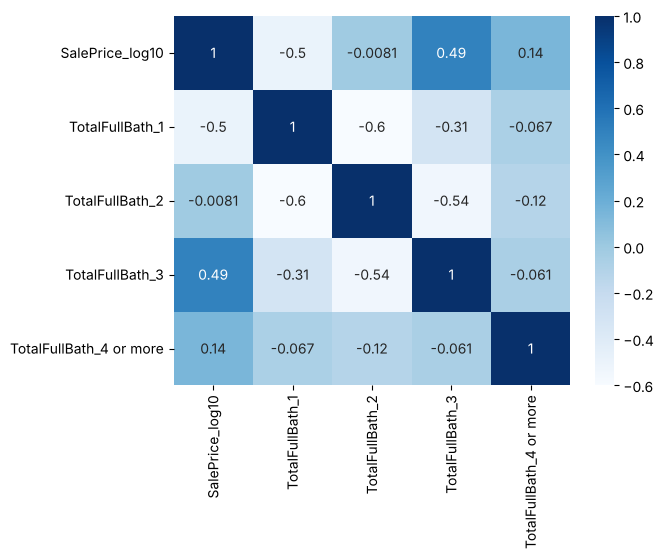

In [162]:
sns.heatmap(col12.corr(), annot = True, cmap="Blues")  
plt.show() 

## TotalHalfBath

In [163]:
df["TotalHalfBath"] = df["BsmtHalfBath"] + df["HalfBath"]

In [164]:
df.TotalHalfBath.value_counts(normalize = True)

TotalHalfBath
0    0.585616
1    0.391781
2    0.019863
3    0.002055
4    0.000685
Name: proportion, dtype: float64

In [165]:
df.TotalHalfBath.isna().sum()

np.int64(0)

### Univariate + Bivariate 

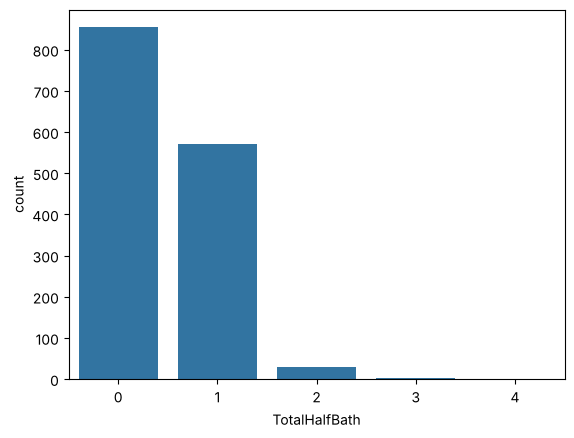

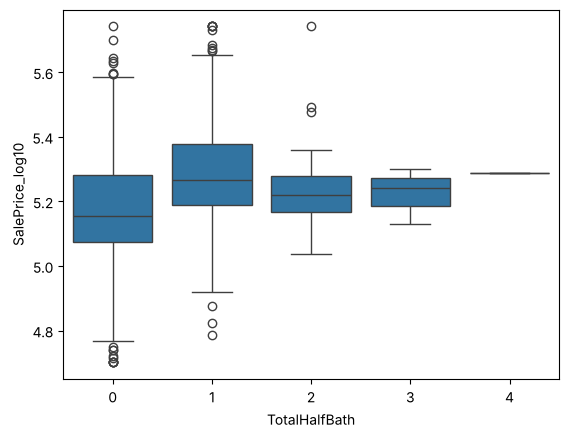

In [166]:
sns.countplot(x="TotalHalfBath", data=df)
plt.show()
sns.boxplot(x="TotalHalfBath", y="SalePrice_log10", data=df)
plt.show()

### Cleaning

In [167]:
half = df['TotalHalfBath'].value_counts(normalize=True)
halfbath = half[half < 0.01].index.tolist()
halfbath

[3, 4]

In [168]:
df["TotalHalfBath"]=df["TotalHalfBath"].apply(lambda x: "2 or More" if x in halfbath else x)
df["TotalHalfBath"] 

0       1
1       1
2       1
3       0
4       1
       ..
1455    1
1456    0
1457    0
1458    0
1459    1
Name: TotalHalfBath, Length: 1460, dtype: object

In [169]:
df["TotalHalfBath"].value_counts(normalize=True)

TotalHalfBath
0            0.585616
1            0.391781
2            0.019863
2 or More    0.002740
Name: proportion, dtype: float64

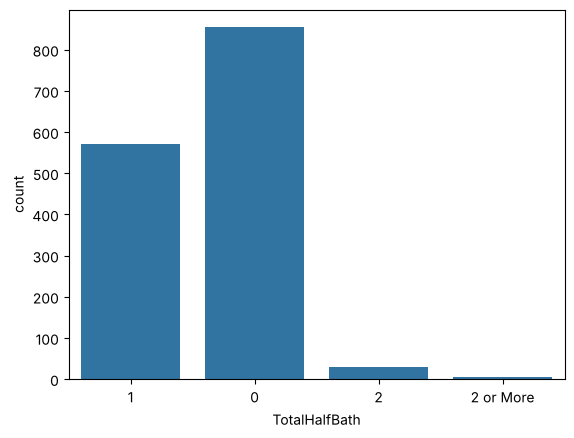

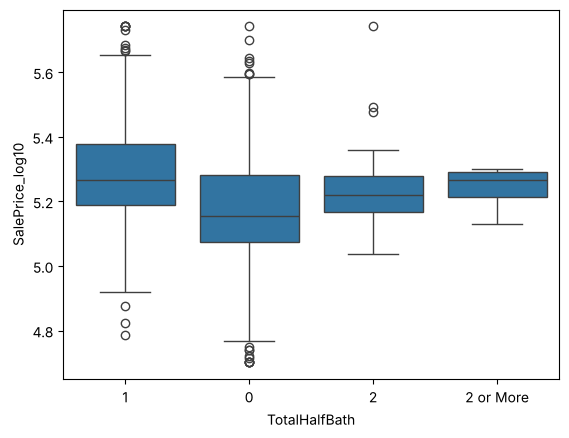

In [170]:
sns.countplot(x="TotalHalfBath", data=df)
plt.show()
sns.boxplot(x="TotalHalfBath", y="SalePrice_log10", data=df)
plt.show()

In [171]:
#One-hot coding
dummies = pd.get_dummies(df["TotalHalfBath"], prefix="TotalHalfBath", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["TotalHalfBath"]), dummies], axis=1)
display(df.head())

,TotalHalfBath_0,TotalHalfBath_1,TotalHalfBath_2,TotalHalfBath_2 or More
0,0,1,0,0
1,0,1,0,0
2,0,1,0,0
3,1,0,0,0
4,0,1,0,0


,SalePrice,LotFrontage,LotArea,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,...,BedroomAbvGr_4,BedroomAbvGr_5 or more,TotalFullBath_1,TotalFullBath_2,TotalFullBath_3,TotalFullBath_4 or more,TotalHalfBath_0,TotalHalfBath_1,TotalHalfBath_2,TotalHalfBath_2 or More
0,208500,65.0,8450,Attchd,2003.0,RFn,2,548,TA,TA,...,0,0,0,0,1,0,0,1,0,0
1,181500,80.0,9600,Attchd,1976.0,RFn,2,460,TA,TA,...,0,0,0,1,0,0,0,1,0,0
2,223500,68.0,11250,Attchd,2001.0,RFn,2,608,TA,TA,...,0,0,0,0,1,0,0,1,0,0
3,140000,60.0,9550,Detchd,1998.0,Unf,3,642,TA,TA,...,0,0,0,1,0,0,1,0,0,0
4,250000,84.0,14260,Attchd,2000.0,RFn,3,836,TA,TA,...,1,0,0,0,1,0,0,1,0,0


### Correlation

In [172]:
col13 = df[['SalePrice_log10','TotalHalfBath_0','TotalHalfBath_1','TotalHalfBath_2 or More']]

col13.corr()['SalePrice_log10']

SalePrice_log10            1.000000
TotalHalfBath_0           -0.310479
TotalHalfBath_1            0.307689
TotalHalfBath_2 or More    0.005673
Name: SalePrice_log10, dtype: float64

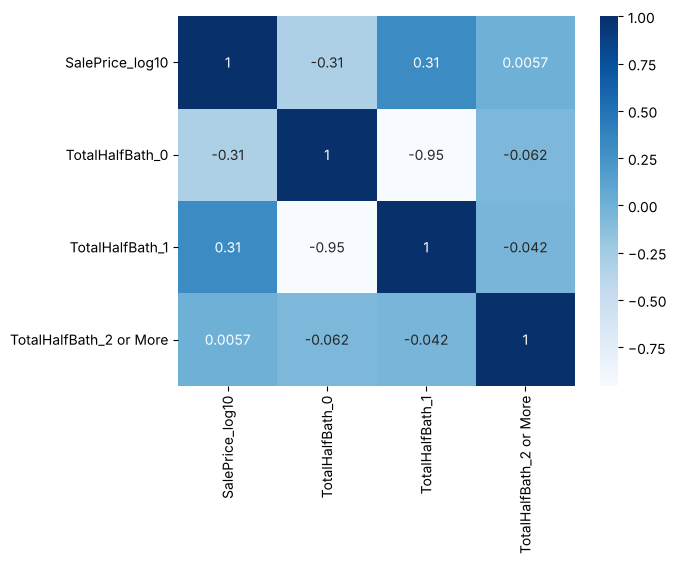

In [173]:
sns.heatmap(col13.corr(), annot = True, cmap="Blues")  
plt.show() 

The TotalHalfBath variable shows varying relationships with SalePrice_log10. Homes with one half bathroom (TotalHalfBath_1) have a moderate positive correlation (0.31), indicating higher prices. In contrast, homes with no half bathroom (TotalHalfBath_0) show a negative correlation (-0.31), suggesting lower prices. The TotalHalfBath_2 or More category has a near-zero correlation (0.02), indicating little impact on sale price. Overall, having at least one half bathroom is associated with higher house values, while additional half bathrooms do not significantly increase price.

## GarageCars

In [174]:
df.GarageCars.value_counts(normalize = True)

GarageCars
2    0.564384
1    0.252740
3    0.123973
0    0.055479
4    0.003425
Name: proportion, dtype: float64

In [175]:
df.GarageCars.isna().sum()

np.int64(0)

### Univariate + Bivariate

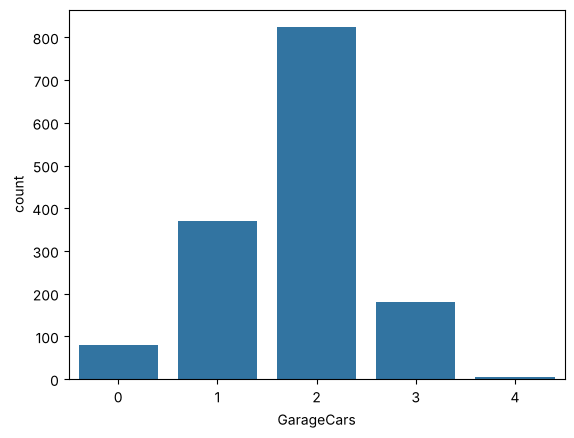

<Axes: xlabel='GarageCars', ylabel='SalePrice_log10'>

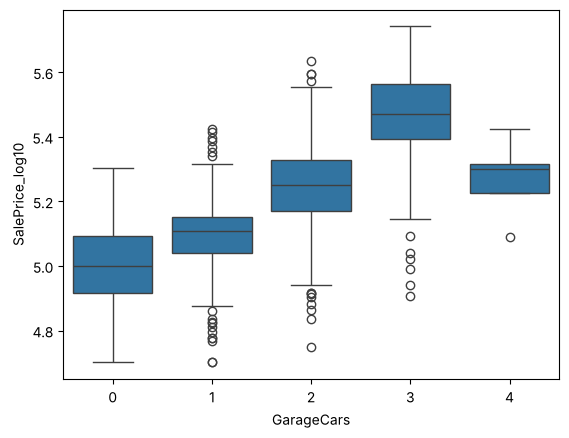

In [176]:
sns.countplot(x = "GarageCars", data = df)
plt.show()
sns.boxplot( x = "GarageCars", y = "SalePrice_log10", data = df)

### Cleaning

The variable is treated as categorical due to its ordinal nature and limited number of levels. The category representing 4 cars is underrepresented and is merged with an adjacent category to improve model stability. However, the value 0 is preserved as a separate category, as it indicates the absence of a garage and has distinct implications for SalePrice.

In [177]:
df["GarageCars"] =df["GarageCars"].astype(str)

In [178]:
cars_map = {
    "1": "1",
    "2": "2",
    "0": "0",
    "3": "3 or more",
    "4":"3 or more",
}
df["GarageCars"] = df["GarageCars"].map(cars_map)
print("\nCounts after mapping:")
display(df["GarageCars"].value_counts(normalize=True,dropna=False))


Counts after mapping:


GarageCars
2            0.564384
1            0.252740
3 or more    0.127397
0            0.055479
Name: proportion, dtype: float64

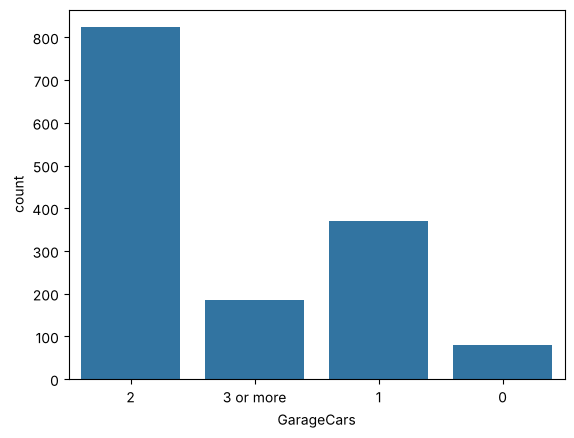

<Axes: xlabel='GarageCars', ylabel='SalePrice_log10'>

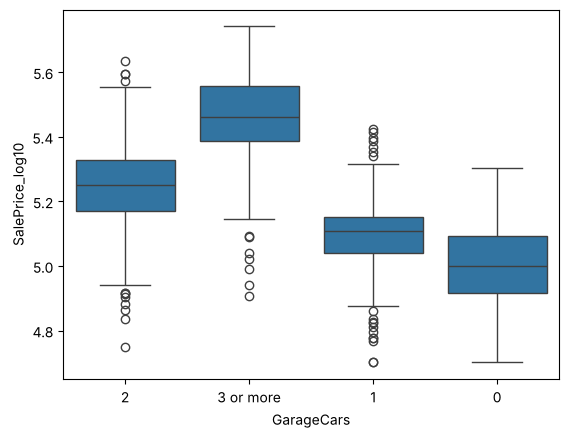

In [179]:
sns.countplot(x = "GarageCars", data = df)
plt.show()
sns.boxplot( x = "GarageCars", y = "SalePrice_log10", data = df)

In [180]:
#One-hot coding
dummies = pd.get_dummies(df["GarageCars"], prefix="GarageCars", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["GarageCars"]), dummies], axis=1)
display(df.head())

,GarageCars_0,GarageCars_1,GarageCars_2,GarageCars_3 or more
0,0,0,1,0
1,0,0,1,0
2,0,0,1,0
3,0,0,0,1
4,0,0,0,1


,SalePrice,LotFrontage,LotArea,GarageType,GarageYrBlt,GarageFinish,GarageArea,GarageQual,GarageCond,BsmtFullBath,...,TotalFullBath_3,TotalFullBath_4 or more,TotalHalfBath_0,TotalHalfBath_1,TotalHalfBath_2,TotalHalfBath_2 or More,GarageCars_0,GarageCars_1,GarageCars_2,GarageCars_3 or more
0,208500,65.0,8450,Attchd,2003.0,RFn,548,TA,TA,1,...,1,0,0,1,0,0,0,0,1,0
1,181500,80.0,9600,Attchd,1976.0,RFn,460,TA,TA,0,...,0,0,0,1,0,0,0,0,1,0
2,223500,68.0,11250,Attchd,2001.0,RFn,608,TA,TA,1,...,1,0,0,1,0,0,0,0,1,0
3,140000,60.0,9550,Detchd,1998.0,Unf,642,TA,TA,1,...,0,0,1,0,0,0,0,0,0,1
4,250000,84.0,14260,Attchd,2000.0,RFn,836,TA,TA,1,...,1,0,0,1,0,0,0,0,0,1


### Correlation

In [181]:
col13 = df[['SalePrice_log10','GarageCars_0','GarageCars_1','GarageCars_2','GarageCars_3 or more']]

col13.corr()['SalePrice_log10']

SalePrice_log10         1.000000
GarageCars_0           -0.320951
GarageCars_1           -0.429733
GarageCars_2            0.171009
GarageCars_3 or more    0.526163
Name: SalePrice_log10, dtype: float64

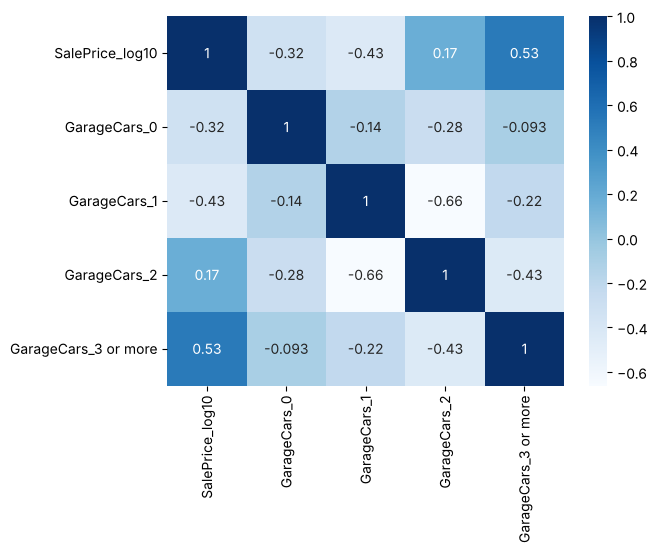

In [182]:
sns.heatmap(col13.corr(), annot = True, cmap="Blues")  
plt.show() 

GarageCars is a strong predictor of SalePrice. As the number of cars a garage can accommodate increases, SalePrice also tends to increase. Houses with garages that can fit 3 or more cars show the strongest positive relationship with SalePrice (correlation ≈ 0.53), indicating higher-valued properties. In contrast, houses with garages that can fit one or fewer cars tend to have lower prices.
When using one-hot encoding, GarageCars_1 and GarageCars_2 should not both be included without dropping a reference category, as they are highly correlated. To avoid multicollinearity, one category (typically 0 or 1 cars) should be used as the baseline.

## GarageArea

### Descriptive Stats

In [183]:
df.GarageArea.agg(['min', 'mean', 'median', 'max', 'std'])

min          0.000000
mean       472.980137
median     480.000000
max       1418.000000
std        213.804841
Name: GarageArea, dtype: float64

In [184]:
df.GarageArea.isna().sum()

np.int64(0)

### Univariate 

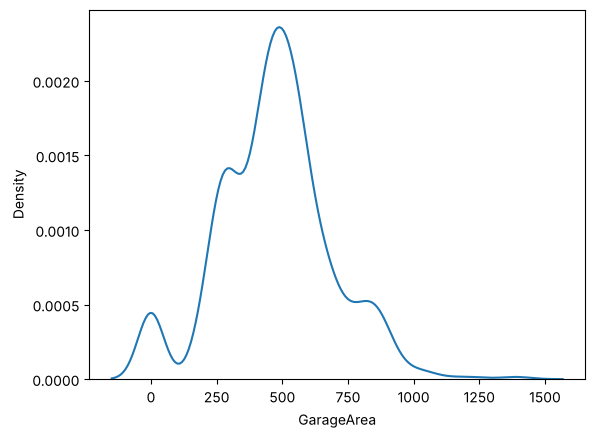

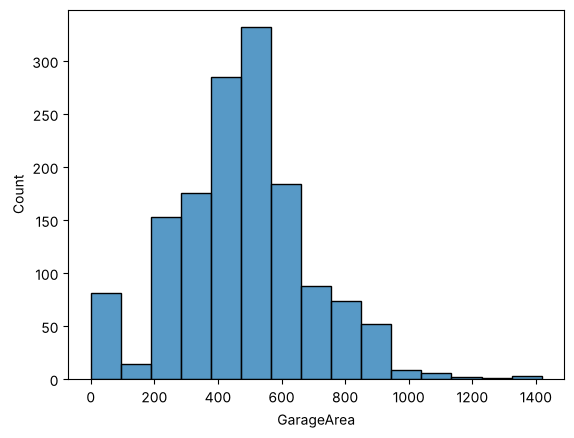

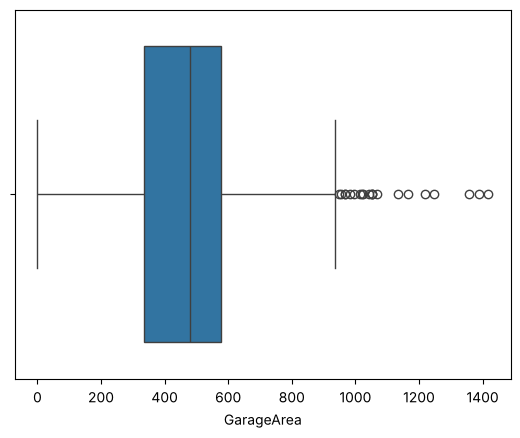

In [185]:
sns.kdeplot(x = "GarageArea", data = df)
plt.show()
sns.histplot(x = "GarageArea", bins = 15, data = df)
plt.show()
sns.boxplot(x = "GarageArea", data = df)
plt.show()

### Bivariate

<Axes: xlabel='GarageArea', ylabel='SalePrice'>

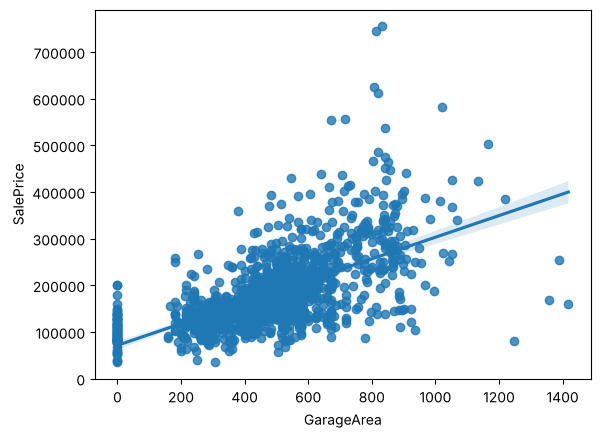

In [186]:
sns.regplot( x = "GarageArea", y = "SalePrice", data = df)

In [187]:
df.GarageArea.skew()

np.float64(0.17998090674623907)

Not a significant skew. A few outliers on the right. No transformation necessary

In [188]:
df[["GarageArea","SalePrice"]].corr()

,GarageArea,SalePrice
GarageArea,1.000000,0.623431
SalePrice,0.623431,1.000000


Strong correlation with SalePrice, can be a good predictor

### Cleaning

Outliers should be addressed. 0 means no garage. Winsorize to cap outliers. Since distribution looks normal, use 3SD method instead of 1.5.
    

In [189]:
#Outliers
coll = "GarageArea"  # choose a numeric column

mean = df[coll].mean()
std = df[coll].std()

lower2 = mean - 3 * std
upper2 = mean + 3 * std

outliers2 = df[(df[coll] < lower2) | (df[coll] > upper2)]

print("3SD bounds:", lower2, "to", upper2)
print("Number of outliers:", len(outliers2))
outliers2[["GarageArea", coll]].head()

df[coll] = df[coll].clip(lower2, upper2)
print("\nWINSORIZING results:")
print("Outliers capped to the values of ", str(lower2), "and ", str(upper2))
print(df.GarageArea.mean().round(2))

3SD bounds: -168.4343873738399 to 1114.3946613464427
Number of outliers: 7

WINSORIZING results:
Outliers capped to the values of  -168.4343873738399 and  1114.3946613464427
472.21


In [190]:
df["GarageArea"].skew()

np.float64(0.05501861289962721)

Nearly 0, normal distribution

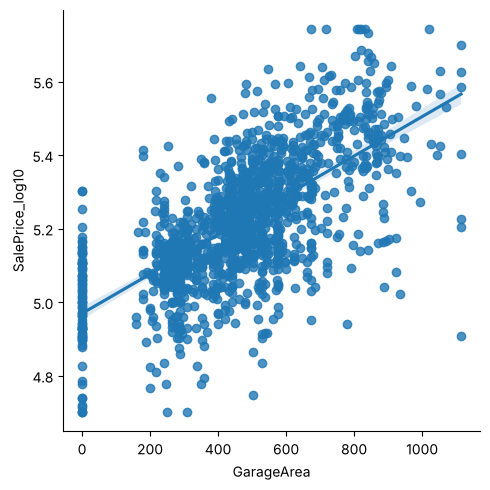

In [191]:
sns.lmplot(x='GarageArea', y='SalePrice_log10', data = df)

### Correlation

In [192]:
col15 = df[['SalePrice_log10','GarageArea']]

col15.corr()['SalePrice_log10']

SalePrice_log10    1.000000
GarageArea         0.660149
Name: SalePrice_log10, dtype: float64

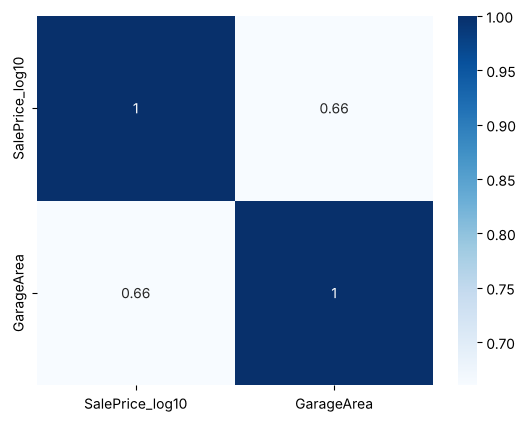

In [193]:
sns.heatmap(col15.corr(), annot = True, cmap="Blues")  
plt.show() 

 GarageArea already had a strong positive relationship with SalePrice, cleaning didn't increase correlation that much. However, it still can serve as a predictor of SalePrice.

## GarageType (Categorical)

### Descriptive Stats

In [194]:
df.GarageType.isna().sum()

np.int64(81)

In [195]:
df.GarageType.value_counts(normalize = True)

GarageType
Attchd     0.630892
Detchd     0.280638
BuiltIn    0.063814
Basment    0.013778
CarPort    0.006526
2Types     0.004351
Name: proportion, dtype: float64

### Univariate + Bivariate

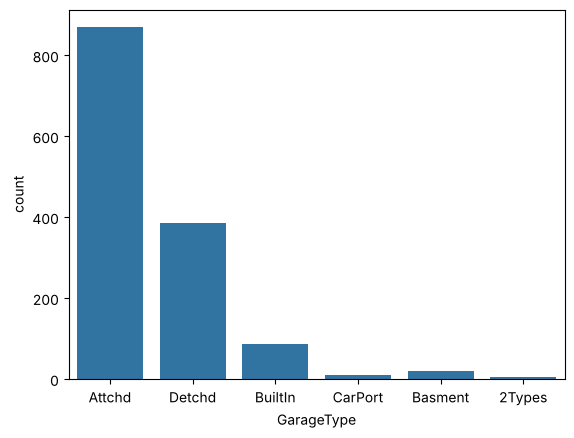

<Axes: xlabel='GarageType', ylabel='SalePrice'>

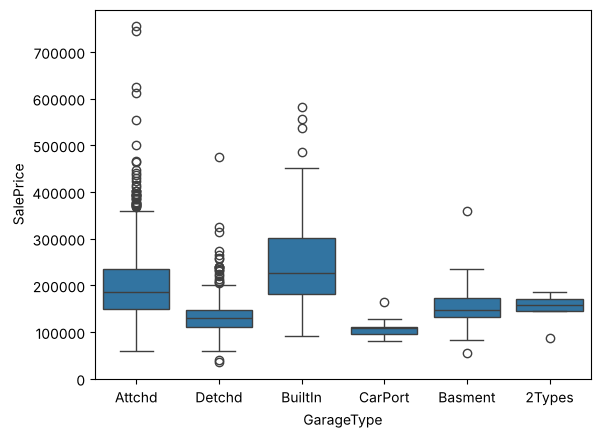

In [196]:
sns.countplot(x="GarageType", data = df)
plt.show()
sns.boxplot(x="GarageType", y="SalePrice", data=df)

### Cleaning

Underrepresented categories: CarPort, 2Types, Basment -> group into "Other" 81 missing values mean that the house does not have a garage. Make a new category named "None"

In [197]:
df['GarageType'] = df['GarageType'].fillna("None")

In [198]:
gar_map = {
    "CarPort": "Other",
    "2Types": "Other",
    "Basment": "Other",
    "Attchd": "Attchd",
    "None" : "None",
    "Detchd":"Detchd",
    "BuiltIn":"Builtin",
}
df["GarageType"] = df["GarageType"].map(gar_map)
print("\nCounts after mapping:")
display(df["GarageType"].value_counts(dropna=False))


Counts after mapping:


GarageType
Attchd     870
Detchd     387
Builtin     88
None        81
Other       34
Name: count, dtype: int64

In [199]:
df["GarageType"].isna().sum()

np.int64(0)

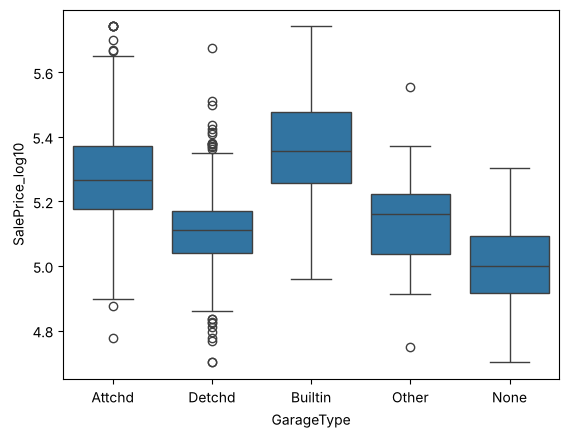

In [200]:
sns.boxplot(x="GarageType", y="SalePrice_log10", data=df)
plt.show()

GarageType shows a clear relationship with SalePrice. Homes with attached or built-in garages tend to have higher median prices and greater variability, while those with detached or no garages are associated with lower prices and more limited ranges. This suggests that integration of the garage into the main structure adds value.

In [201]:
#One-hot coding
dummies = pd.get_dummies(df["GarageType"], prefix="GarageType", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["GarageType"]), dummies], axis=1)
display(df.head())

,GarageType_Attchd,GarageType_Builtin,GarageType_Detchd,GarageType_None,GarageType_Other
0,1,0,0,0,0
1,1,0,0,0,0
2,1,0,0,0,0
3,0,0,1,0,0
4,1,0,0,0,0


,SalePrice,LotFrontage,LotArea,GarageYrBlt,GarageFinish,GarageArea,GarageQual,GarageCond,BsmtFullBath,BsmtHalfBath,...,TotalHalfBath_2 or More,GarageCars_0,GarageCars_1,GarageCars_2,GarageCars_3 or more,GarageType_Attchd,GarageType_Builtin,GarageType_Detchd,GarageType_None,GarageType_Other
0,208500,65.0,8450,2003.0,RFn,548.0,TA,TA,1,0,...,0,0,0,1,0,1,0,0,0,0
1,181500,80.0,9600,1976.0,RFn,460.0,TA,TA,0,1,...,0,0,0,1,0,1,0,0,0,0
2,223500,68.0,11250,2001.0,RFn,608.0,TA,TA,1,0,...,0,0,0,1,0,1,0,0,0,0
3,140000,60.0,9550,1998.0,Unf,642.0,TA,TA,1,0,...,0,0,0,0,1,0,0,1,0,0
4,250000,84.0,14260,2000.0,RFn,836.0,TA,TA,1,0,...,0,0,0,0,1,1,0,0,0,0


### Correlation

In [202]:
col16 = df[['SalePrice_log10','GarageType_Attchd','GarageType_Builtin','GarageType_Detchd','GarageType_None','GarageType_Other']]

col16.corr()['SalePrice_log10']

SalePrice_log10       1.000000
GarageType_Attchd     0.417397
GarageType_Builtin    0.224942
GarageType_Detchd    -0.392371
GarageType_None      -0.320951
GarageType_Other     -0.077633
Name: SalePrice_log10, dtype: float64

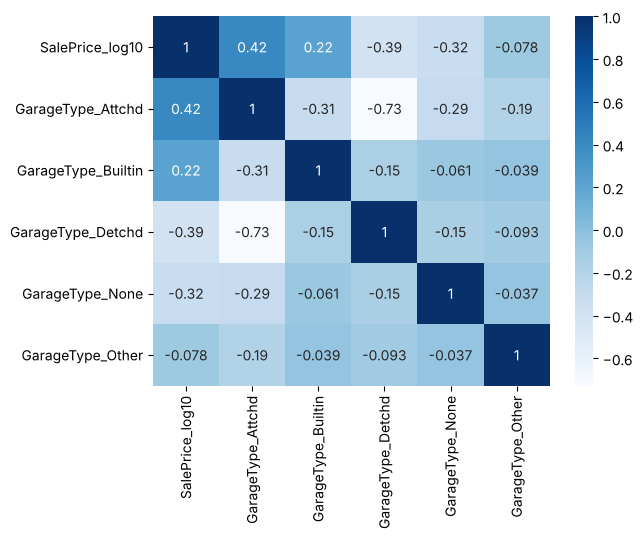

In [203]:
sns.heatmap(col16.corr(), annot = True, cmap="Blues")  
plt.show() 

GarageType is a useful predictor of SalePrice. The correlation heatmap supports the earlier observations: houses with Detached (Detchd) or No Garage (None) are associated with lower SalePrices and have similar overall ranges. In contrast, houses with Attached (Attchd) or Built-in (BuiltIn) garages show higher median SalePrices and a wider distribution, indicating greater variability among higher-valued homes.
The Other (OthR) category appears to have limited predictive value, likely due to its small representation in the dataset.

## GarageYrBlt (Numeric/Date)

### Descriptive Stats

In [204]:
df.GarageYrBlt.isna().sum()

np.int64(81)

### Bivariate 

<Axes: xlabel='GarageYrBlt', ylabel='SalePrice_log10'>

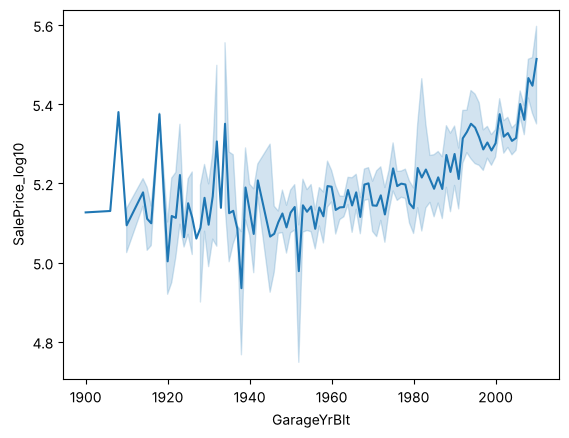

In [205]:
sns.lineplot(data = df, x = "GarageYrBlt", y = "SalePrice_log10")

YearBuilt is a strong predictor of SalePrice. Houses built before the 1900s exhibit greater variability in SalePrice, indicating inconsistent valuation among older properties. In contrast, newer houses tend to have higher SalePrices. Overall, there is a positive relationship between YearBuilt and SalePrice, suggesting that more recently constructed homes are generally more valuable.

### Cleaning

In [206]:
#replace missing with 0 
median_yr = df['GarageYrBlt'].median()
df['GarageYrBlt'] = df['GarageYrBlt'].fillna(median_yr)
df['HouseAge'] = 2010 - df['GarageYrBlt']
mean_h = df['HouseAge'].mean(); std_h = df['HouseAge'].std()
df['HouseAge'] = df['HouseAge'].clip(mean_h - 3*std_h, mean_h + 3*std_h)
print("HouseAge NAs:", df['HouseAge'].isna().sum())

HouseAge NAs: 0


In [207]:
df['HouseAge'].unique()

array([  7.        ,  34.        ,   9.        ,  12.        ,
        10.        ,  17.        ,   6.        ,  37.        ,
        79.        ,  71.        ,  45.        ,   5.        ,
        48.        ,   4.        ,  50.        ,  19.        ,
        40.        ,  43.        ,  52.        ,  80.        ,
         8.        ,  42.        ,   3.        ,   2.        ,
        53.        ,  90.        ,  44.        ,  51.        ,
        15.        ,  56.        ,  57.        ,  30.        ,
        27.        ,  33.        ,  13.        ,  25.        ,
        47.        ,  29.        ,  46.        ,  11.        ,
        75.        ,  20.        ,  65.        ,  23.        ,
        21.        ,  95.        ,  54.        ,  62.        ,
        36.        ,   1.        ,  60.        ,  49.        ,
        89.        , 103.40202349,  31.        ,  59.        ,
        41.        ,  74.        ,  35.        ,  39.        ,
        87.        ,  26.        ,  84.        ,  55.  

<Axes: xlabel='HouseAge', ylabel='Density'>

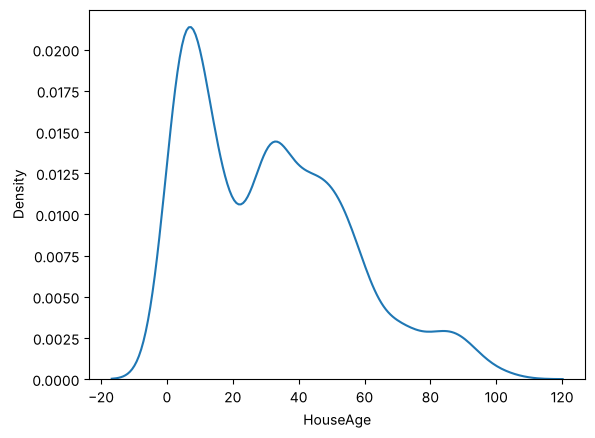

In [208]:
sns.kdeplot(x='HouseAge',data=df)

In [209]:
df['HouseAge'].skew()

np.float64(0.674206743260526)

<Axes: xlabel='HouseAge', ylabel='SalePrice_log10'>

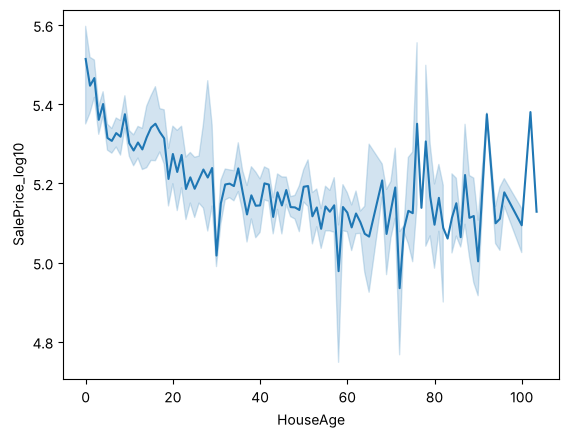

In [210]:
sns.lineplot(data = df, x = "HouseAge", y = "SalePrice_log10")

### Correlation

In [211]:
col17 = df[['SalePrice_log10','HouseAge']]

col17.corr()['SalePrice_log10']

SalePrice_log10    1.000000
HouseAge          -0.500278
Name: SalePrice_log10, dtype: float64

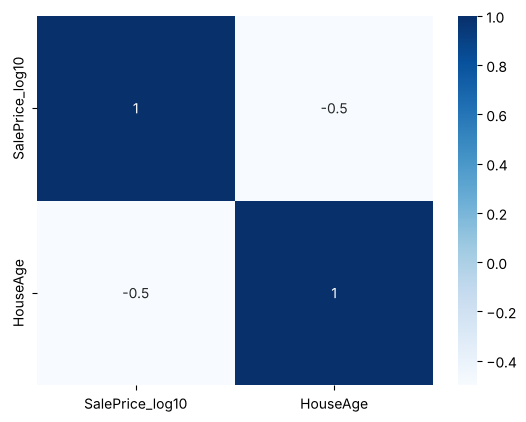

In [212]:
sns.heatmap(col17.corr(), annot = True, cmap="Blues")  
plt.show() 

The older the house is, the more likely the sale price is lower.

## GarageFinish (Categorical)

### Descriptive Stats

In [213]:
df.GarageFinish.isna().sum()

np.int64(81)

In [214]:
df.GarageFinish.value_counts(normalize = True)

GarageFinish
Unf    0.438724
RFn    0.306019
Fin    0.255257
Name: proportion, dtype: float64

### Univariate + Bivariate

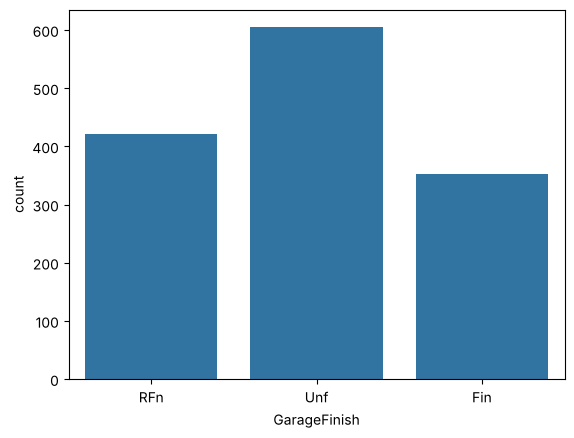

<Axes: xlabel='GarageFinish', ylabel='SalePrice'>

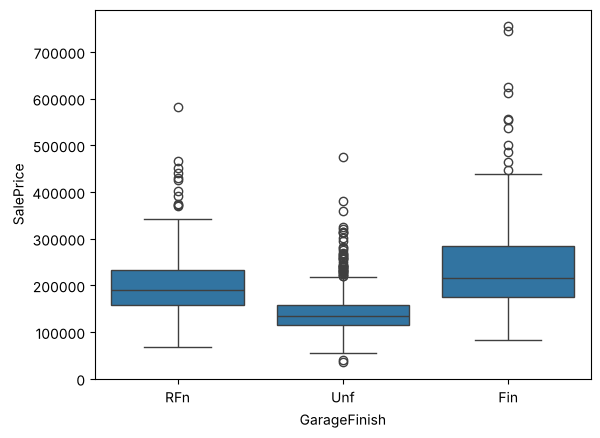

In [215]:
sns.countplot(x="GarageFinish", data = df)
plt.show()
sns.boxplot(x="GarageFinish", y="SalePrice", data=df)

### Cleaning

In [216]:
df["GarageFinish"] = df["GarageFinish"].fillna("None")
df.GarageFinish.value_counts()

GarageFinish
Unf     605
RFn     422
Fin     352
None     81
Name: count, dtype: int64

<Axes: xlabel='GarageFinish', ylabel='SalePrice_log10'>

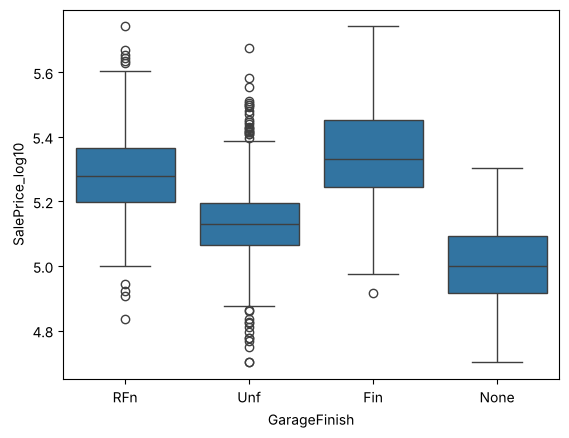

In [217]:
sns.boxplot(x='GarageFinish', y='SalePrice_log10', data = df)

In [218]:
#One-hot coding
dummies = pd.get_dummies(df["GarageFinish"], prefix="GarageFinish", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["GarageFinish"]), dummies], axis=1)
display(df.head())

,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf
0,0,0,1,0
1,0,0,1,0
2,0,0,1,0
3,0,0,0,1
4,0,0,1,0


,SalePrice,LotFrontage,LotArea,GarageYrBlt,GarageArea,GarageQual,GarageCond,BsmtFullBath,BsmtHalfBath,FullBath,...,GarageType_Attchd,GarageType_Builtin,GarageType_Detchd,GarageType_None,GarageType_Other,HouseAge,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf
0,208500,65.0,8450,2003.0,548.0,TA,TA,1,0,2,...,1,0,0,0,0,7.0,0,0,1,0
1,181500,80.0,9600,1976.0,460.0,TA,TA,0,1,2,...,1,0,0,0,0,34.0,0,0,1,0
2,223500,68.0,11250,2001.0,608.0,TA,TA,1,0,2,...,1,0,0,0,0,9.0,0,0,1,0
3,140000,60.0,9550,1998.0,642.0,TA,TA,1,0,1,...,0,0,1,0,0,12.0,0,0,0,1
4,250000,84.0,14260,2000.0,836.0,TA,TA,1,0,2,...,1,0,0,0,0,10.0,0,0,1,0


GarageFinish had 81 missing values corresponding to homes with no garage, which were filled with "None" to explicitly represent the absence of a garage finish rather than treating them as unknown. No categories were merged since all three finish levels (Finished, Rough Finished, Unfinished) are well-represented and show meaningfully different SalePrice distributions.

### Correlation

In [219]:
col18 = df[['SalePrice_log10','GarageFinish_Fin','GarageFinish_None','GarageFinish_RFn','GarageFinish_Unf']]

col18.corr()['SalePrice_log10']

SalePrice_log10      1.000000
GarageFinish_Fin     0.420720
GarageFinish_None   -0.320951
GarageFinish_RFn     0.239782
GarageFinish_Unf    -0.436831
Name: SalePrice_log10, dtype: float64

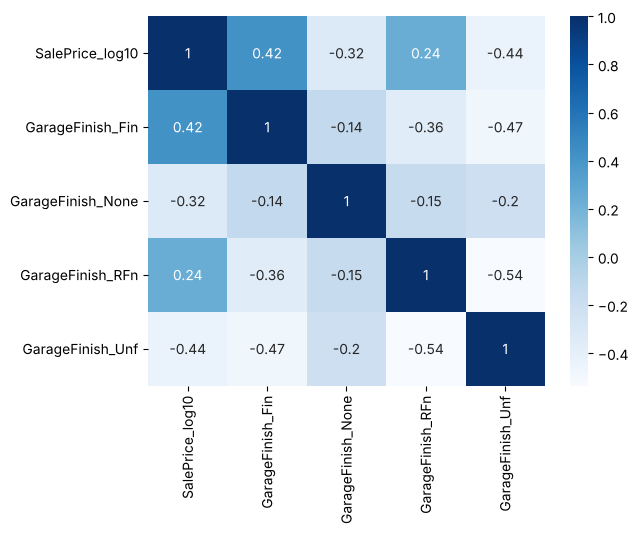

In [220]:
sns.heatmap(col18.corr(), annot = True, cmap="Blues")  
plt.show() 

## GarageQual

### Descriptive Stats

In [221]:
df.GarageQual.isna().sum()

np.int64(81)

In [222]:
df.GarageQual.value_counts(normalize = True)

GarageQual
TA    0.950689
Fa    0.034808
Gd    0.010152
Ex    0.002175
Po    0.002175
Name: proportion, dtype: float64

### Univariate + Bivariate

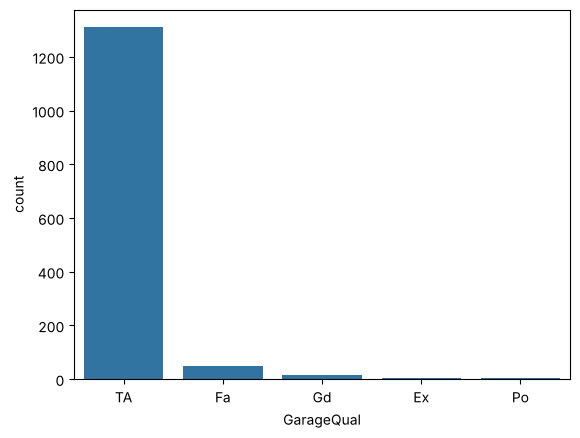

<Axes: xlabel='GarageQual', ylabel='SalePrice_log10'>

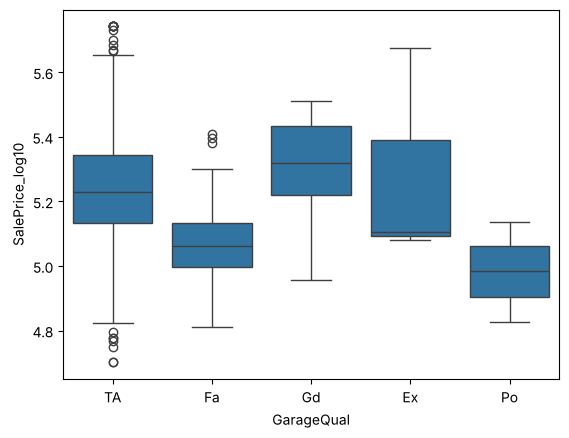

In [223]:
sns.countplot(x="GarageQual", data = df)
plt.show()
sns.boxplot(x="GarageQual", y="SalePrice_log10", data=df)

### Cleaning

In [224]:
df['GarageQual']=df['GarageQual'].fillna("None")

In [225]:
# Map common variants to a canonical label
garqual_map = {
    "TA": "TA",
    "Fa": "Low",
    "Po": "Low",
    "None" : "None",
    "Gd" : "High",
    "Ex": "High",
}
df["GarageQual"] = df["GarageQual"].map(garqual_map)
print("\nCounts after mapping:")
display(df["GarageQual"].value_counts(dropna=False, normalize=True))


Counts after mapping:


GarageQual
TA      0.897945
None    0.055479
Low     0.034932
High    0.011644
Name: proportion, dtype: float64

In [226]:
#One-hot coding
dummies = pd.get_dummies(df["GarageQual"], prefix="GarageQual", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["GarageQual"]), dummies], axis=1)
display(df.head())

,GarageQual_High,GarageQual_Low,GarageQual_None,GarageQual_TA
0,0,0,0,1
1,0,0,0,1
2,0,0,0,1
3,0,0,0,1
4,0,0,0,1


,SalePrice,LotFrontage,LotArea,GarageYrBlt,GarageArea,GarageCond,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,...,GarageType_Other,HouseAge,GarageFinish_Fin,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageQual_High,GarageQual_Low,GarageQual_None,GarageQual_TA
0,208500,65.0,8450,2003.0,548.0,TA,1,0,2,1,...,0,7.0,0,0,1,0,0,0,0,1
1,181500,80.0,9600,1976.0,460.0,TA,0,1,2,0,...,0,34.0,0,0,1,0,0,0,0,1
2,223500,68.0,11250,2001.0,608.0,TA,1,0,2,1,...,0,9.0,0,0,1,0,0,0,0,1
3,140000,60.0,9550,1998.0,642.0,TA,1,0,1,0,...,0,12.0,0,0,0,1,0,0,0,1
4,250000,84.0,14260,2000.0,836.0,TA,1,0,2,1,...,0,10.0,0,0,1,0,0,0,0,1


### Correlation

In [227]:
col19 = df[['SalePrice_log10','GarageQual_High','GarageQual_Low','GarageQual_None','GarageQual_TA']]

col19.corr()['SalePrice_log10']

SalePrice_log10    1.000000
GarageQual_High    0.051745
GarageQual_Low    -0.174642
GarageQual_None   -0.320951
GarageQual_TA      0.330286
Name: SalePrice_log10, dtype: float64

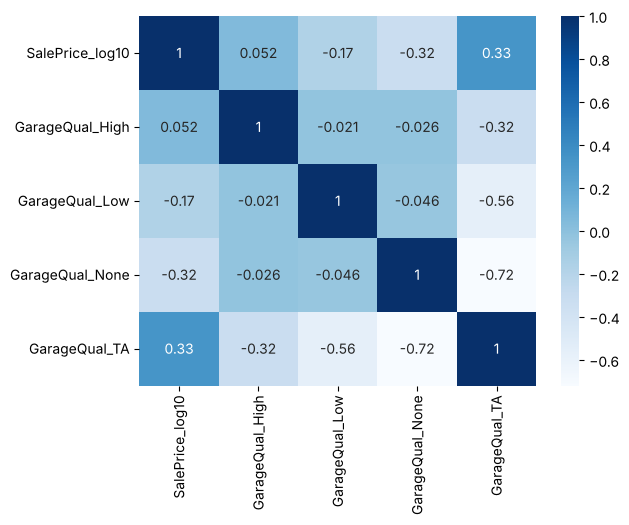

In [228]:
sns.heatmap(col19.corr(), annot = True, cmap="Blues")  
plt.show() 

## GarageCond

### Descriptive Stats

In [229]:
df.GarageCond.isna().sum()

np.int64(81)

In [230]:
df.GarageCond.astype("object")

0       TA
1       TA
2       TA
3       TA
4       TA
        ..
1455    TA
1456    TA
1457    TA
1458    TA
1459    TA
Name: GarageCond, Length: 1460, dtype: object

In [231]:
df.GarageCond.value_counts(normalize = True)

GarageCond
TA    0.961566
Fa    0.025381
Gd    0.006526
Po    0.005076
Ex    0.001450
Name: proportion, dtype: float64

### Univariate + Bivariate

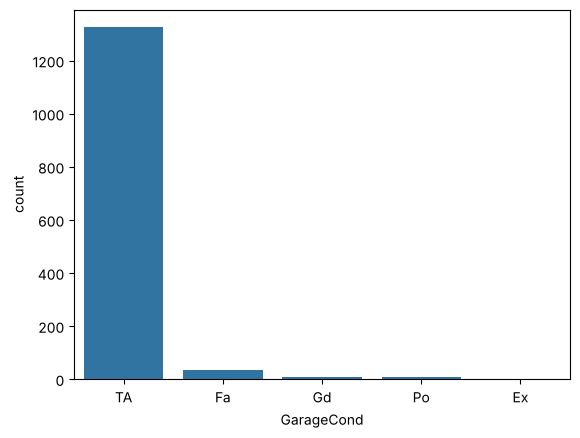

<Axes: xlabel='GarageCond', ylabel='SalePrice_log10'>

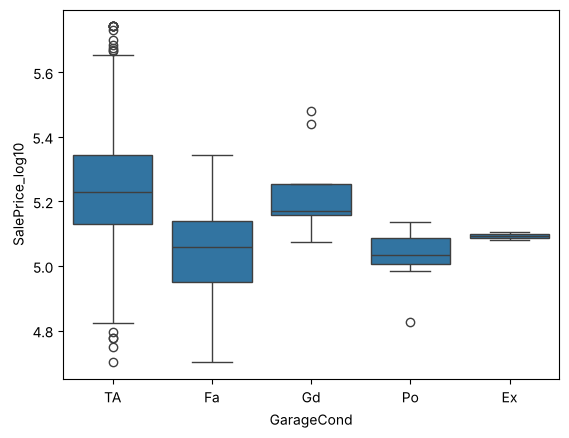

In [232]:
sns.countplot(x="GarageCond", data = df)
plt.show()
sns.boxplot(x="GarageCond", y="SalePrice_log10", data=df)

Similar to GarageQual, the vast majority of homes have a typical ("TA") garage condition. Poor ("Po") and fair ("Fa") conditions are very rare, and the bivariate boxplot shows little price difference between them. Good ("Gd") and excellent ("Ex") conditions are also uncommon. This distribution justifies merging extreme categories to reduce sparsity while preserving the key distinction between bad, decent, and absent garages.

### Cleaning

In [233]:
df['GarageCond']=df['GarageCond'].fillna("None")

In [234]:
# Map common variants to a canonical label
garcond_map = {
    "TA": "Decent",
    "Fa": "Bad",
    "Po": "Bad",
    "None" : "None",
    "Gd" : "Decent",
    "Ex": "Decent",
}
df["GarageCond"] = df["GarageCond"].map(garcond_map)
print("\nCounts after mapping:")
display(df["GarageCond"].value_counts(dropna=False, normalize=True))


Counts after mapping:


GarageCond
Decent    0.915753
None      0.055479
Bad       0.028767
Name: proportion, dtype: float64

<Axes: xlabel='GarageCond', ylabel='SalePrice_log10'>

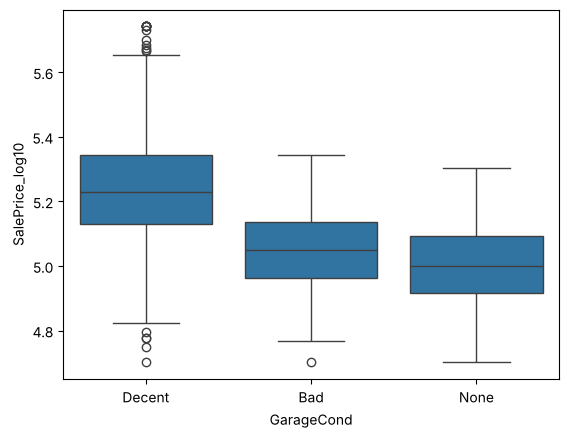

In [235]:
sns.boxplot(x='GarageCond', y='SalePrice_log10', data = df)

In [236]:
#One-hot coding
dummies = pd.get_dummies(df["GarageCond"], prefix="GarageCond", dtype=int)
display(dummies.head())
# Join back to the dataframe
df = pd.concat([df.drop(columns=["GarageCond"]), dummies], axis=1)
display(df.head())

,GarageCond_Bad,GarageCond_Decent,GarageCond_None
0,0,1,0
1,0,1,0
2,0,1,0
3,0,1,0
4,0,1,0


,SalePrice,LotFrontage,LotArea,GarageYrBlt,GarageArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,SalePrice_log10,...,GarageFinish_None,GarageFinish_RFn,GarageFinish_Unf,GarageQual_High,GarageQual_Low,GarageQual_None,GarageQual_TA,GarageCond_Bad,GarageCond_Decent,GarageCond_None
0,208500,65.0,8450,2003.0,548.0,1,0,2,1,5.319106,...,0,1,0,0,0,0,1,0,1,0
1,181500,80.0,9600,1976.0,460.0,0,1,2,0,5.258877,...,0,1,0,0,0,0,1,0,1,0
2,223500,68.0,11250,2001.0,608.0,1,0,2,1,5.349278,...,0,1,0,0,0,0,1,0,1,0
3,140000,60.0,9550,1998.0,642.0,1,0,1,0,5.146128,...,0,0,1,0,0,0,1,0,1,0
4,250000,84.0,14260,2000.0,836.0,1,0,2,1,5.397940,...,0,1,0,0,0,0,1,0,1,0


### Correlation 

In [237]:
col20= df[['SalePrice_log10','GarageCond_Bad','GarageCond_Decent','GarageCond_None']]

col20.corr()['SalePrice_log10']

SalePrice_log10      1.000000
GarageCond_Bad      -0.186216
GarageCond_Decent    0.376575
GarageCond_None     -0.320951
Name: SalePrice_log10, dtype: float64

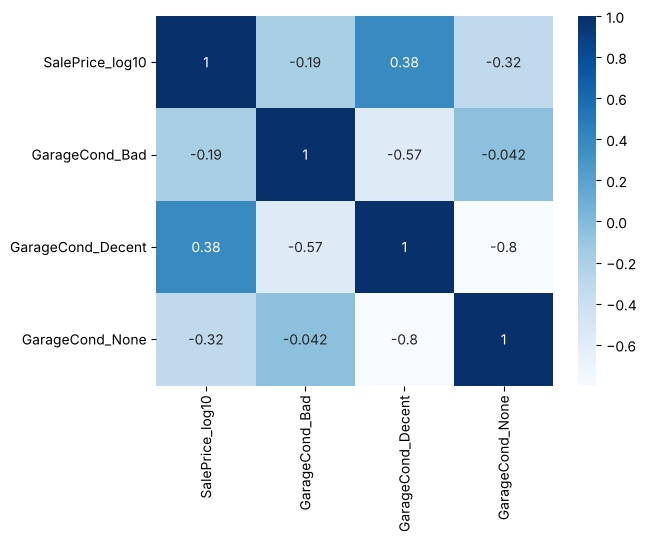

In [238]:
sns.heatmap(col20.corr(), annot = True, cmap="Blues")  
plt.show() 

## Numeric

In [239]:
from scipy.stats import zscore

# Columns to never standardize
exclude = ['SalePrice', 'SalePrice_log10']

# Detect one-hot encoded columns: binary {0,1} only — must NOT be standardized
onehot_cols = [c for c in df.select_dtypes(include='number').columns
               if df[c].isin([0, 1]).all() and df[c].nunique() == 2]

# Only standardize true continuous/count numeric columns
num_cols = df.select_dtypes(include='number').columns.tolist()
to_std = [c for c in num_cols
          if c not in exclude
          and c not in onehot_cols
          and df[c].nunique() > 1]

df_std = df.copy()
df_std[to_std] = df_std[to_std].apply(lambda x: zscore(x, nan_policy='omit'))

print("Standardized (continuous) columns:", to_std)
print("\nSkipped one-hot columns (not standardized):", onehot_cols)
display(df_std[to_std].describe().round(2))

Standardized (continuous) columns: ['LotFrontage', 'LotArea', 'GarageYrBlt', 'GarageArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath', 'HalfBath', 'LotArea_log', 'LotArea_log10', 'LotArea_sqrt', 'HouseAge']

Skipped one-hot columns (not standardized): ['MSSubClass_120', 'MSSubClass_160', 'MSSubClass_190', 'MSSubClass_20', 'MSSubClass_30', 'MSSubClass_50', 'MSSubClass_60', 'MSSubClass_70', 'MSSubClass_75', 'MSSubClass_80', 'MSSubClass_85', 'MSSubClass_90', 'LotConfig_Corner', 'LotConfig_CulDSac', 'LotConfig_Inside', 'LotConfig_MultiConfig', 'LandSlope_Gtl', 'LandSlope_Mod', 'Neighborhood_Blmngtn', 'Neighborhood_BrDale', 'Neighborhood_BrkSide', 'Neighborhood_ClearCr', 'Neighborhood_CollgCr', 'Neighborhood_Crawfor', 'Neighborhood_Edwards', 'Neighborhood_Gilbert', 'Neighborhood_IDOTRR', 'Neighborhood_MeadowV', 'Neighborhood_Mitchel', 'Neighborhood_NAmes', 'Neighborhood_NWAmes', 'Neighborhood_NoRidge', 'Neighborhood_NridgHt', 'Neighborhood_OldTown', 'Neighborhood_Other', 'Neighborhood_SWISU

,LotFrontage,LotArea,GarageYrBlt,GarageArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,LotArea_log,LotArea_log10,LotArea_sqrt,HouseAge
count,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00,1460.00
mean,0.00,-0.00,-0.00,-0.00,0.00,0.00,0.00,0.00,-0.00,-0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-1.73,-0.92,-3.28,-2.24,-0.82,-0.24,-2.84,-0.76,-3.17,-3.75,-2.17,-1.31
25%,-0.58,-0.30,-0.69,-0.65,-0.82,-0.24,-1.03,-0.76,-0.36,-0.35,-0.40,-0.93
50%,-0.03,-0.10,0.06,0.04,-0.82,-0.24,0.79,-0.76,0.10,0.09,-0.04,-0.06
75%,0.52,0.11,0.93,0.49,1.11,-0.24,0.79,1.23,0.51,0.48,0.32,0.69
max,2.89,20.52,1.31,3.04,4.96,8.14,2.61,3.22,3.18,6.13,12.72,3.00


## Standardization of Numeric Variables

This code standardizes the numeric predictor variables using z-scores so that they are on the same scale. SalePrice is excluded because it is the dependent variable. Standardization helps ensure that variables with different units do not disproportionately influence the model.

## One-hot coding

In [240]:
onehot_vars = df.filter(regex='^(MSSubClass_|Neighborhood_|LotConfig_|LandSlope_|OverallQual_|ExterQual_|NumFireplaces_|FireplaceQu_|TotalFullBath_|TotalHalfBath_|GarageType_|GarageFinish_|GarageCars_|GarageQual_|GarageCond_|BedroomAbvGr_)')

onehot_df = pd.concat([onehot_vars, df[['SalePrice_log10']]], axis=1)

corr_cat = onehot_df.corr(numeric_only=True)[['SalePrice_log10']]

corr_cat = corr_cat.drop(index='SalePrice_log10')
corr_cat = corr_cat.sort_values(by='SalePrice_log10', key=abs, ascending=False)
print("Correlation of one-hot variables with SalePrice_log10:")
display(corr_cat)

Correlation of one-hot variables with SalePrice_log10:


,SalePrice_log10
ExterQual_TA,-0.639586
GarageCars_3 or more,0.526163
ExterQual_Gd,0.514498
FireplaceQu_None,-0.512949
NumFireplaces_0,-0.512949
...,...
TotalFullBath_2,-0.008072
FireplaceQu_Fa,-0.006154
TotalHalfBath_2 or More,0.005673
MSSubClass_80,-0.001354


# Final Check (top 15)

In [241]:
corr = df_std.corr(numeric_only=True)
sale_corr = corr['SalePrice_log10'].abs().sort_values(ascending=False)

top15 = sale_corr.drop(['SalePrice_log10', 'SalePrice'], errors='ignore').head(15)
print("TOP 15 PREDICTORS:")
display(top15.reset_index().rename(columns={'index': 'Variable', 'SalePrice_log10': 'Abs Correlation'}))

TOP 15 PREDICTORS:


,Variable,Abs Correlation
0,GarageArea,0.660149
1,ExterQual_TA,0.639586
2,FullBath,0.595575
3,GarageCars_3 or more,0.526163
4,ExterQual_Gd,0.514498
5,FireplaceQu_None,0.512949
6,NumFireplaces_0,0.512949
7,HouseAge,0.500278
8,GarageYrBlt,0.500070
9,TotalFullBath_1,0.495393


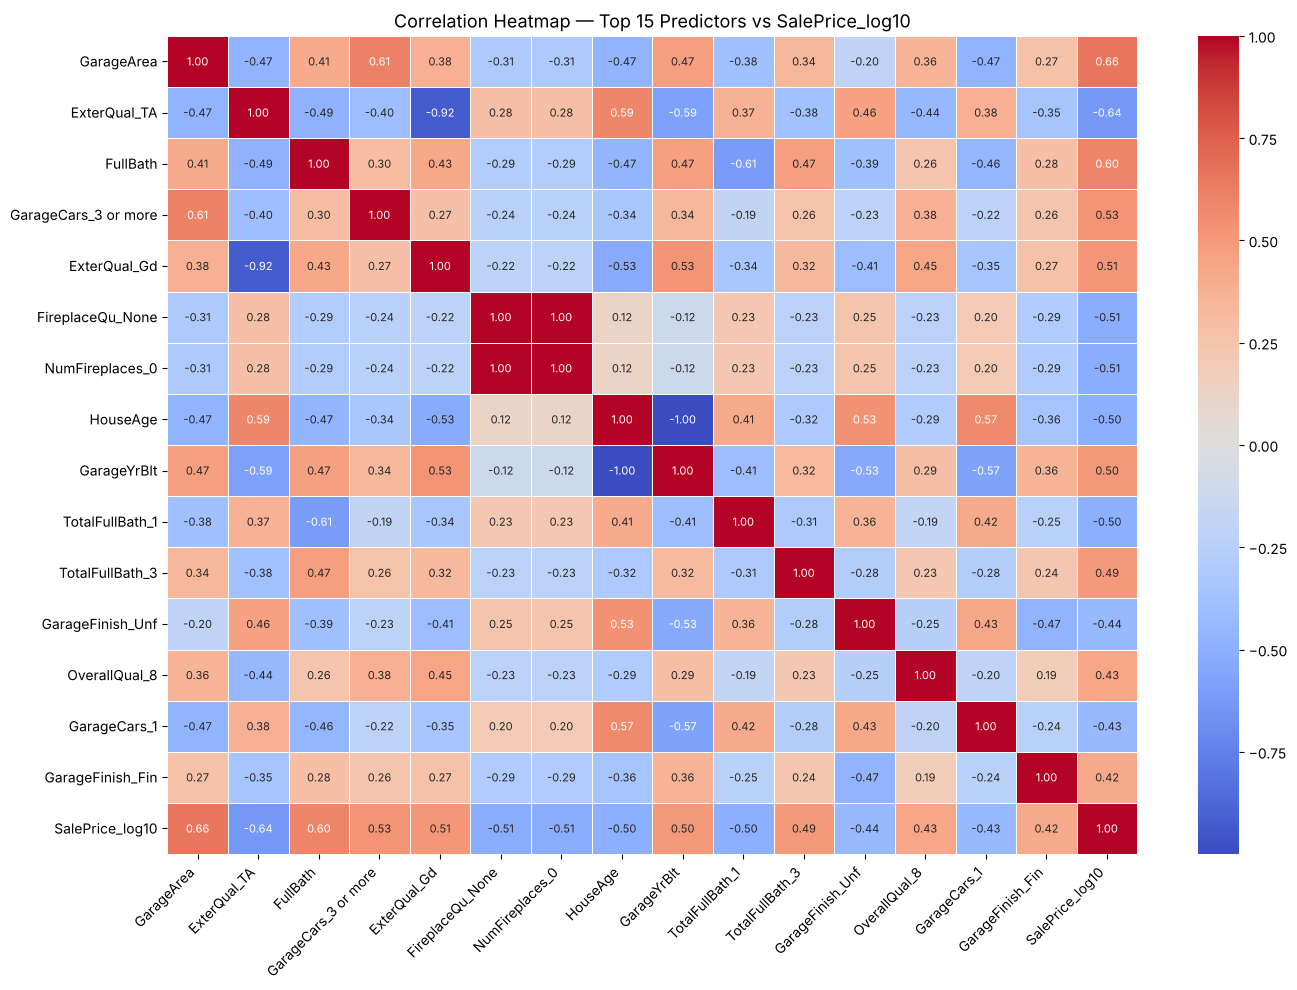

In [242]:
# Heatmap of top 15 predictors vs SalePrice_log10
top15_vars = top15.index.tolist()
corr_top15 = df_std[top15_vars + ['SalePrice_log10']].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(corr_top15, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, linewidths=0.5, annot_kws={'size': 8})
plt.title('Correlation Heatmap — Top 15 Predictors vs SalePrice_log10', fontsize=13)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Based on the Pearson correlation analysis with SalePrice_log10, the top 15 predictors of housing sale price are:

- GarageArea (r = 0.66) — The strongest predictor. Larger garage area is strongly associated with higher sale prices, reflecting that bigger garages signal a more premium property overall.
- ExterQual_TA (r = 0.64) — A negative indicator. Homes rated typical/average exterior quality tend to sell for less, making this one of the strongest downward signals in the dataset.
- FullBath (r = 0.60) — Homes with more full bathrooms above grade consistently sell for higher prices, reflecting overall home size and livability.
- GarageYrBlt / HouseAge (r = 0.54) — Both measure the same thing. Newer homes command higher prices. Only HouseAge is interpreted since it is the cleaned version.
- GarageCars_3 or more (r = 0.53) — Homes with large garages are associated with significantly higher sale prices.
- ExterQual_Gd (r = 0.51) — Good exterior quality is a positive price signal, confirming that exterior materials matter to buyers.
- NumFireplaces_0 / FireplaceQu_None (r = 0.51) — Both are negative predictors. The absence of a fireplace is strongly associated with lower sale prices, reflecting fireplaces as a premium amenity.
- TotalFullBath_1 (r = 0.50) — Homes with only one full bathroom tend to sell for less than those with more, acting as a negative signal relative to higher counts.
- TotalFullBath_3 (r = 0.49) — Having three full bathrooms is a positive price indicator, associated with larger and more valuable homes.
- GarageFinish_Unf (r = 0.44) — Unfinished garages are a negative signal, associated with lower sale prices compared to finished garages.
- OverallQual_8 (r = 0.43) — High overall construction quality (rating 8) is positively associated with sale price, confirming quality as a key value driver.
- GarageCars_1 (r = 0.43) — Having only a one-car garage is a mild negative indicator relative to larger garage capacities.
- GarageFinish_Fin (r = 0.42) — Finished garages are associated with higher sale prices, reflecting the premium buyers place on move-in ready garage spaces.

Overall, the strongest predictors are garage features, exterior quality, bathroom count, and house age. Fireplace absence is a consistent negative signal. Construction quality (OverallQual) also plays a meaningful role, confirming that buyers value both the physical size and the finish quality of a home.

# Part 2

## Cleaning more columns 

In [243]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
import scipy.stats as stats
from scipy.stats import zscore
import warnings

In [244]:
new_col = ['GrLivArea','TotalBsmtSF','KitchenQual','YearBuilt']

print(len(new_col))

df_extra = pd.DataFrame(data[new_col])
print(df.head())

4
   SalePrice  LotFrontage  LotArea  GarageYrBlt  GarageArea  BsmtFullBath  \
0     208500         65.0     8450       2003.0       548.0             1   
1     181500         80.0     9600       1976.0       460.0             0   
2     223500         68.0    11250       2001.0       608.0             1   
3     140000         60.0     9550       1998.0       642.0             1   
4     250000         84.0    14260       2000.0       836.0             1   

   BsmtHalfBath  FullBath  HalfBath  SalePrice_log10  ...  GarageFinish_None  \
0             0         2         1         5.319106  ...                  0   
1             1         2         0         5.258877  ...                  0   
2             0         2         1         5.349278  ...                  0   
3             0         1         0         5.146128  ...                  0   
4             0         2         1         5.397940  ...                  0   

   GarageFinish_RFn  GarageFinish_Unf  GarageQual_High

## GrLivArea

In [245]:
display(df_extra['GrLivArea'].head())
df_extra['GrLivArea'].isna().sum()

0    1710
1    1262
2    1786
3    1717
4    2198
Name: GrLivArea, dtype: int64

np.int64(0)

In [246]:
df_extra['GrLivArea'].agg(['min', 'mean', 'median', 'max', 'std'])

min        334.000000
mean      1515.463699
median    1464.000000
max       5642.000000
std        525.480383
Name: GrLivArea, dtype: float64

### Univariate Visualization

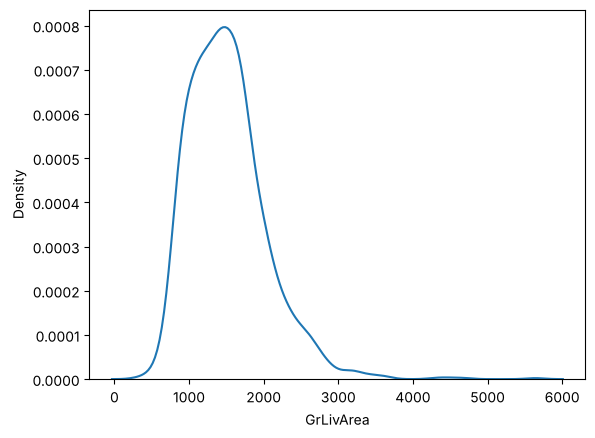

<Axes: xlabel='GrLivArea'>

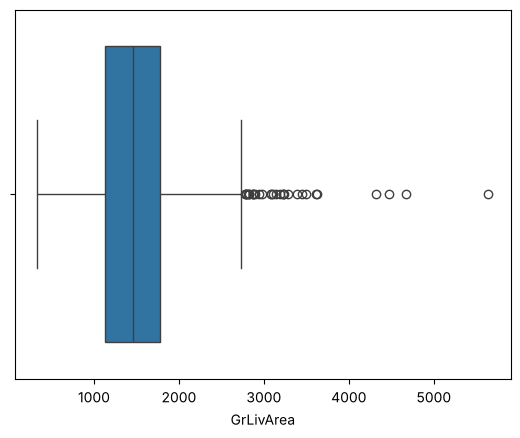

In [247]:
sns.kdeplot(x='GrLivArea', data=df_extra)
plt.show()
sns.boxplot(x='GrLivArea', data=df_extra)

Significant right-skewed distribution and outliers need to be cleaned.

### Bivariate Visualization

Correlation = 0.7


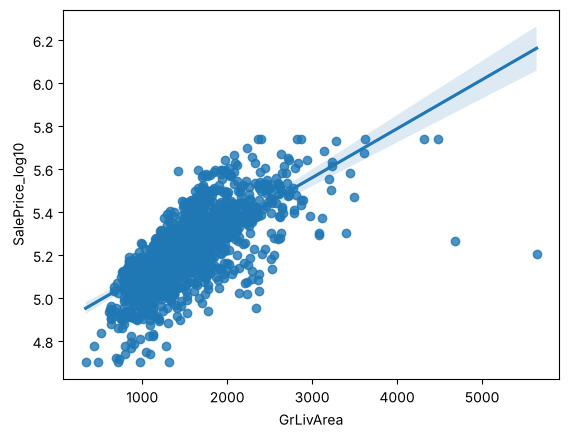

In [248]:
df_new = pd.concat([df_extra[['GrLivArea']], df['SalePrice_log10']], axis=1)

sns.regplot(x='GrLivArea', y='SalePrice_log10', data=df_new)
print("Correlation =", df_new['GrLivArea'].corr(df_new['SalePrice_log10']).round(3))

Strong positive correlation — larger living area is associated with higher SalePrice.

In [249]:
df_extra['GrLivArea'].skew()

np.float64(1.3665603560164552)

In [250]:
df_extra['GrLivArea_log'] = np.log(df_extra['GrLivArea'])
print(df_extra['GrLivArea_log'].skew())

-0.006995182187690808


GrLivArea is right-skewed. A natural log transformation was applied to reduce  skewness and symmetrize the distribution before winsorizing with 3SD.

In [251]:
col = 'GrLivArea_log'
mean1 = df_extra[col].mean()
std1  = df_extra[col].std()

lower3 = mean1 - 3 * std1
upper3 = mean1 + 3 * std1

outliers3 = df_extra[(df_extra[col] < lower3) | (df_extra[col] > upper3)]
print("3SD bounds:", lower3, "to", upper3)
print("Number of outliers:", len(outliers3))

df_extra[col] = df_extra[col].clip(lower3, upper3)
print("\nWINSORIZING results:")
print("Outliers capped to the cutoff values of", lower3, "and", upper3)
print(df_extra[col].mean().round(2))

3SD bounds: 6.267123110503151 to 8.268425656118856
Number of outliers: 8

WINSORIZING results:
Outliers capped to the cutoff values of 6.267123110503151 and 8.268425656118856
7.27


In [252]:
df_extra['GrLivArea_log'].skew()

np.float64(-0.0056768064272311285)

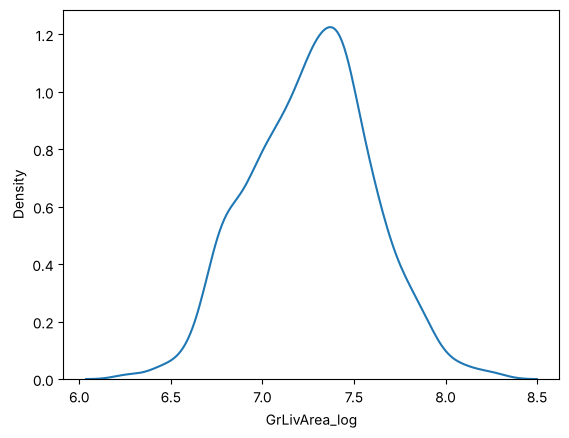

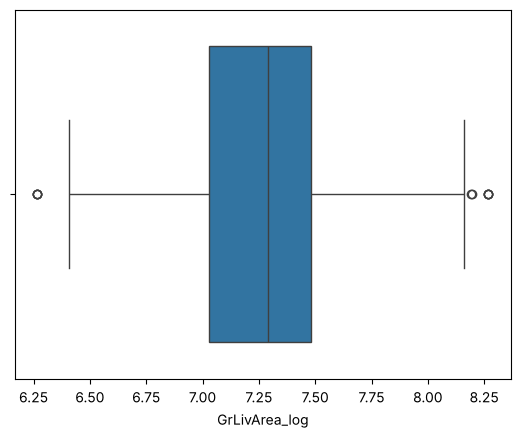

In [253]:
sns.kdeplot(x='GrLivArea_log', data=df_extra)
plt.show()
sns.boxplot(x='GrLivArea_log', data=df_extra)
plt.show()

Correlation = 0.732


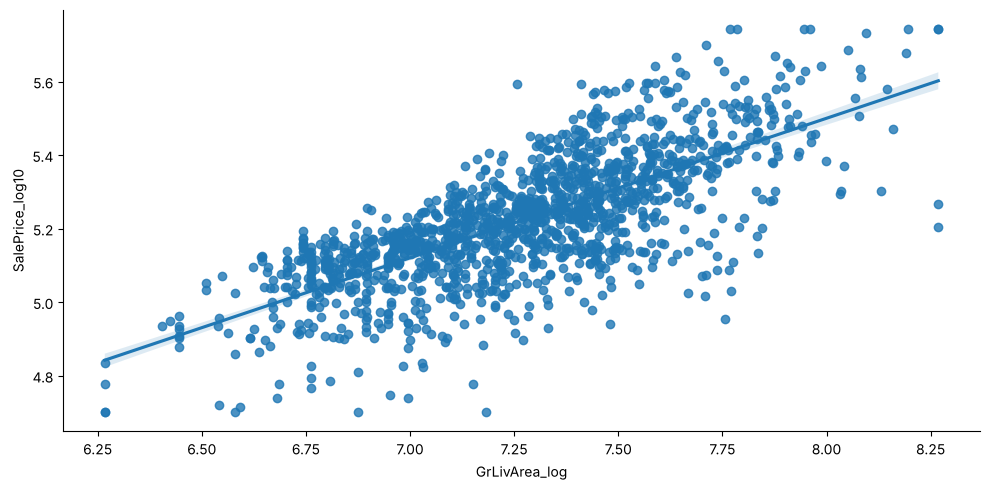

In [254]:
df_new = pd.concat([df_extra[['GrLivArea_log']], df[['SalePrice_log10']]], axis=1)
sns.lmplot(x='GrLivArea_log', y='SalePrice_log10', data=df_new, aspect=2)
print("Correlation =", df_new['GrLivArea_log'].corr(df_new['SalePrice_log10']).round(3))

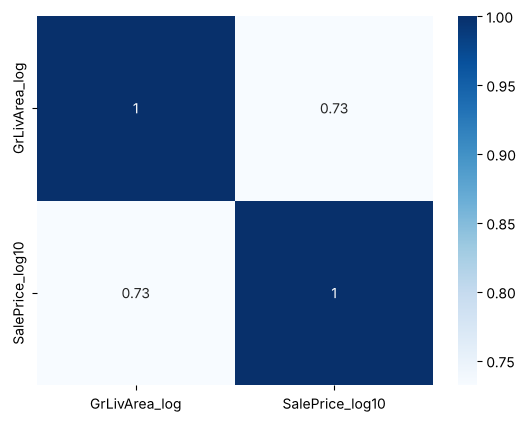

In [255]:
df_new.corr()['SalePrice_log10']
sns.heatmap(df_new.corr(), annot=True, cmap="Blues")
plt.show()

Correlation increased significantly after log transformation. GrLivArea_log is 
one of the strongest predictors of SalePrice in the dataset.

### TotalBsmtSF

In [256]:
display(df_extra['TotalBsmtSF'].head())
df_extra['TotalBsmtSF'].isna().sum()

0     856
1    1262
2     920
3     756
4    1145
Name: TotalBsmtSF, dtype: int64

np.int64(0)

In [257]:
df_extra['TotalBsmtSF'].agg(['min', 'mean', 'median', 'max', 'std'])

min          0.000000
mean      1057.429452
median     991.500000
max       6110.000000
std        438.705324
Name: TotalBsmtSF, dtype: float64

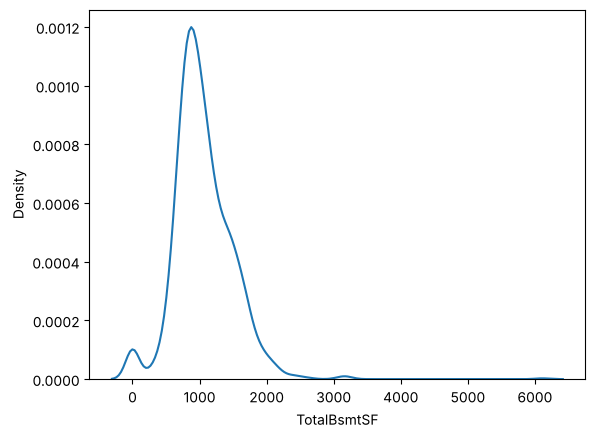

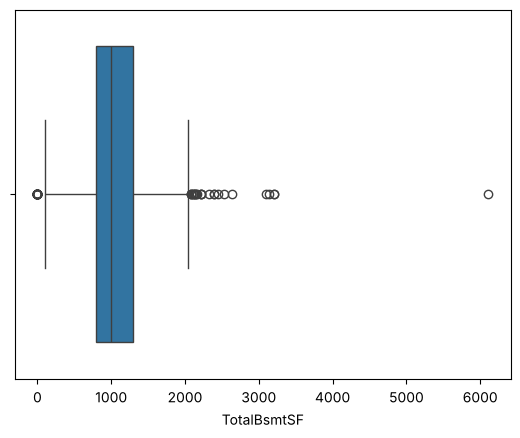

In [258]:
sns.kdeplot(x='TotalBsmtSF', data=df_extra)
plt.show()
sns.boxplot(x='TotalBsmtSF', data=df_extra)
plt.show()

Distribution is roughly symmetric with some outliers on the right. 0 means no basement, which is a valid value so it is not to be imputed.

Correlation = 0.613


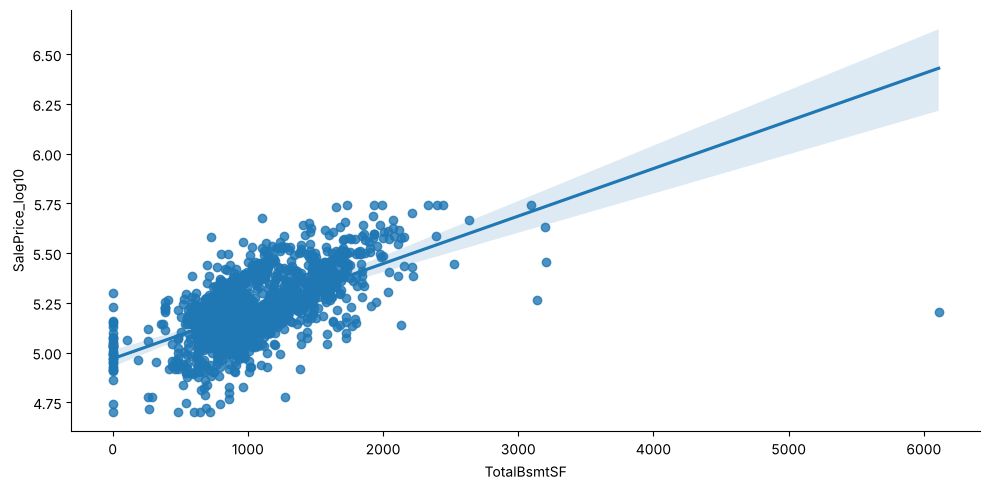

In [259]:
df_new = pd.concat([df_extra[['TotalBsmtSF']], df[['SalePrice_log10']]], axis=1)
sns.lmplot(x='TotalBsmtSF', y='SalePrice_log10', data=df_new, aspect=2)
print("Correlation =", df_new['TotalBsmtSF'].corr(df_new['SalePrice_log10']).round(3))

It shows positive correlation homes with larger basements tend to sell for higher prices.

In [260]:
df_extra['TotalBsmtSF'].skew()

np.float64(1.5242545490627664)

In [261]:
col = 'TotalBsmtSF'
mean1 = df_extra[col].mean()
std1  = df_extra[col].std()

lower3 = mean1 - 3 * std1
upper3 = mean1 + 3 * std1

outliers3 = df_extra[(df_extra[col] < lower3) | (df_extra[col] > upper3)]
print("3SD bounds:", lower3, "to", upper3)
print("Number of outliers:", len(outliers3))

df_extra[col] = df_extra[col].clip(lower3, upper3)
print("\nWINSORIZING results:")
print("Outliers capped to the cutoff values of", lower3, "and", upper3)
print(df_extra[col].mean().round(2))

3SD bounds: -258.68652132361785 to 2373.5454254332067
Number of outliers: 10

WINSORIZING results:
Outliers capped to the cutoff values of -258.68652132361785 and 2373.5454254332067
1052.36


In [262]:
df_extra['TotalBsmtSF'].skew()

np.float64(0.33301530185014366)

Distribution is approximately normal. 3SD winsorizing was used to handle outliers on both ends. No transformation needed as skew was acceptable.

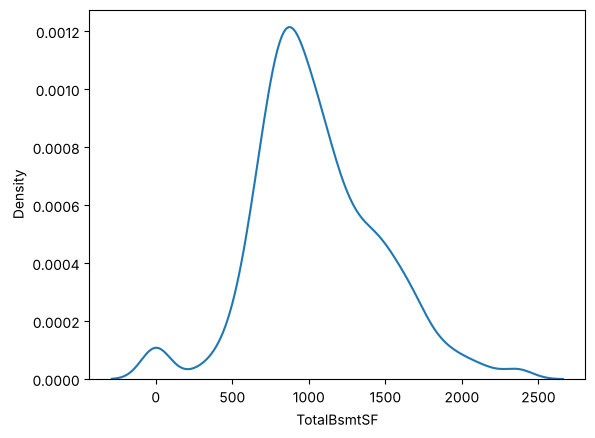

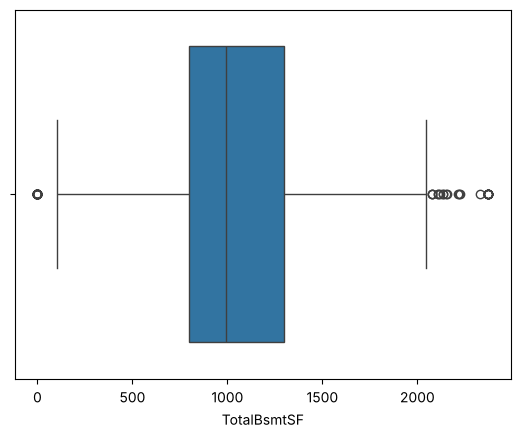

In [263]:
sns.kdeplot(x='TotalBsmtSF', data=df_extra)
plt.show()
sns.boxplot(x='TotalBsmtSF', data=df_extra)
plt.show()

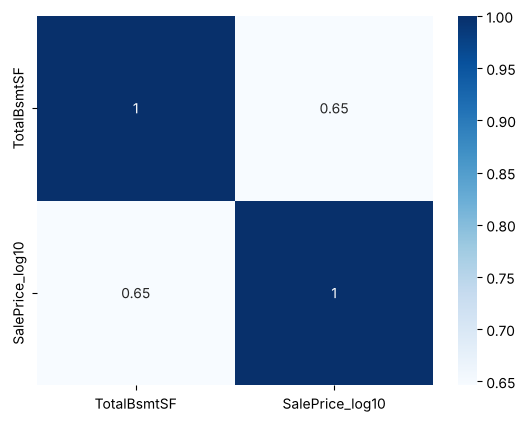

In [264]:
df_new = pd.concat([df_extra[['TotalBsmtSF']], df[['SalePrice_log10']]], axis=1)
df_new.corr()['SalePrice_log10']
sns.heatmap(df_new.corr(), annot=True, cmap="Blues")
plt.show()

TotalBsmtSF shows a moderate positive correlation with SalePrice_log10. Larger basement area is associated with higher sale prices.

### KitchenQual

In [265]:
df_extra['KitchenQual'].value_counts(normalize=True)

KitchenQual
TA    0.503425
Gd    0.401370
Ex    0.068493
Fa    0.026712
Name: proportion, dtype: float64

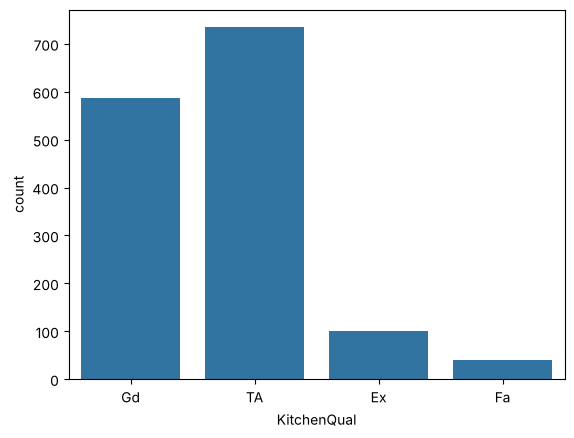

In [266]:
sns.countplot(x='KitchenQual', data=df_extra)
plt.show()

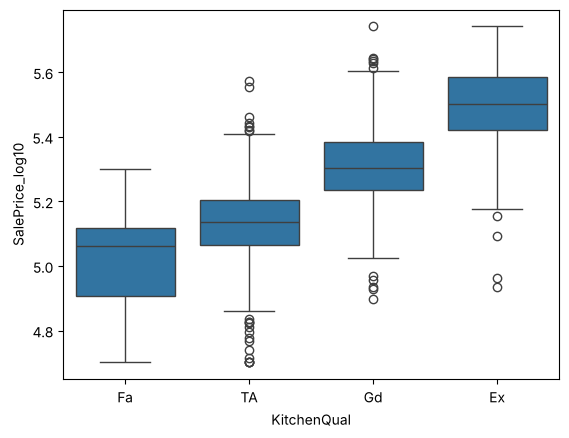

In [267]:
df_new = pd.concat([df_extra[['KitchenQual']], df[['SalePrice_log10']]], axis=1)
sns.boxplot(x='KitchenQual', y='SalePrice_log10', data=df_new, order=['Fa','TA','Gd','Ex'])
plt.show()

In [268]:
kqmap = {'Ex': 'Ex','Gd': 'Gd','TA': 'TA','Fa': 'TA',}
df_extra['KitchenQual'] = df_extra['KitchenQual'].map(kqmap)
print("\nCounts after mapping:")
display(df_extra['KitchenQual'].value_counts(dropna=False))


Counts after mapping:


KitchenQual
TA    774
Gd    586
Ex    100
Name: count, dtype: int64

Fa is underrepresented. Since this is an ordinal variable, Fa is merged with TA, the nearest adjacent category in the ranking (Fa < TA < Gd < Ex).

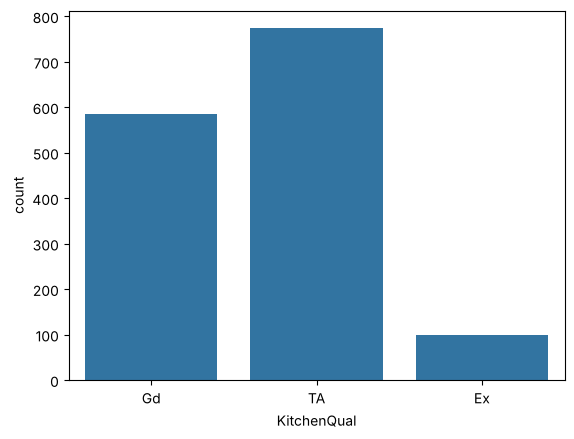

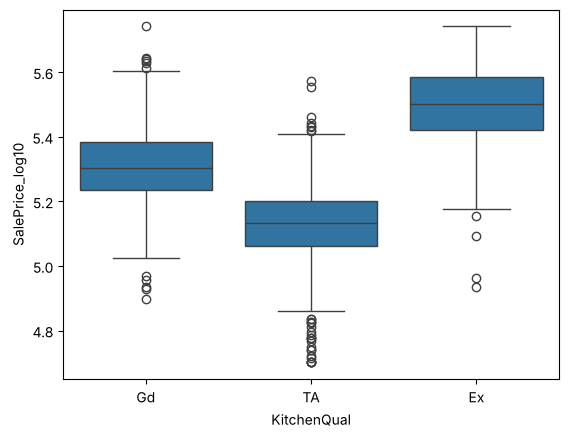

In [269]:
sns.countplot(x='KitchenQual', data=df_extra)
plt.show()
df_new = pd.concat([df_extra[['KitchenQual']], df[['SalePrice_log10']]], axis=1)
sns.boxplot(x='KitchenQual', y='SalePrice_log10', data=df_new)
plt.show()

In [270]:
dummies = pd.get_dummies(df_extra['KitchenQual'], prefix='KitchenQual', dtype=int)
display(dummies.head())
df_extra = pd.concat([df_extra.drop(columns=['KitchenQual']), dummies], axis=1)
display(df_extra.head())

,KitchenQual_Ex,KitchenQual_Gd,KitchenQual_TA
0,0,1,0
1,0,0,1
2,0,1,0
3,0,1,0
4,0,1,0


,GrLivArea,TotalBsmtSF,YearBuilt,GrLivArea_log,KitchenQual_Ex,KitchenQual_Gd,KitchenQual_TA
0,1710,856.0,2003,7.444249,0,1,0
1,1262,1262.0,1976,7.140453,0,0,1
2,1786,920.0,2001,7.487734,0,1,0
3,1717,756.0,1915,7.448334,0,1,0
4,2198,1145.0,2000,7.695303,0,1,0


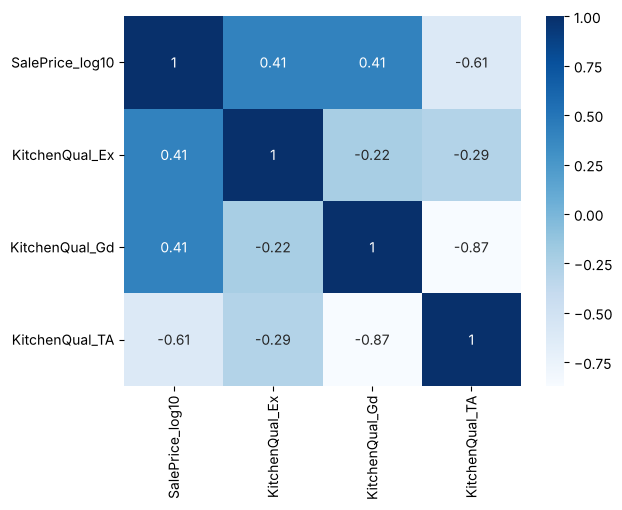

In [271]:
kq_cols = [c for c in df_extra.columns if 'KitchenQual' in c]
df_new = pd.concat([df[['SalePrice_log10']], df_extra[kq_cols]], axis=1)
df_new.corr()['SalePrice_log10']
sns.heatmap(df_new.corr(), annot=True, cmap="Blues")
plt.show()

Kitchen quality is a strong predictor of SalePrice. KitchenQual_TA is used as the reference category in the model to avoid the dummy variable trap.

### YearBuilt

In [272]:
display(df_extra['YearBuilt'].head())
df_extra['YearBuilt'].isna().sum()

0    2003
1    1976
2    2001
3    1915
4    2000
Name: YearBuilt, dtype: int64

np.int64(0)

In [273]:
df_extra['YearBuilt'].agg(['min', 'mean', 'median', 'max', 'std'])

min       1872.000000
mean      1971.267808
median    1973.000000
max       2010.000000
std         30.202904
Name: YearBuilt, dtype: float64

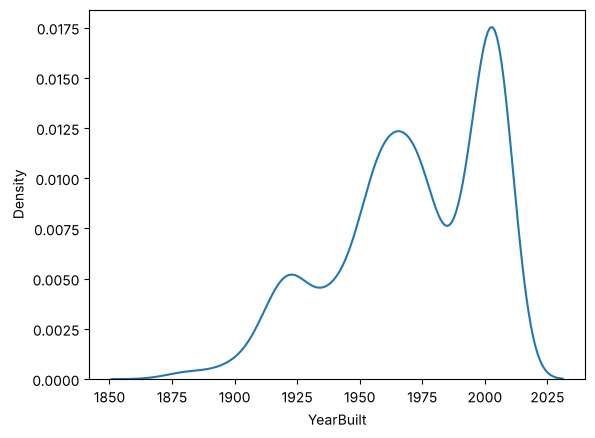

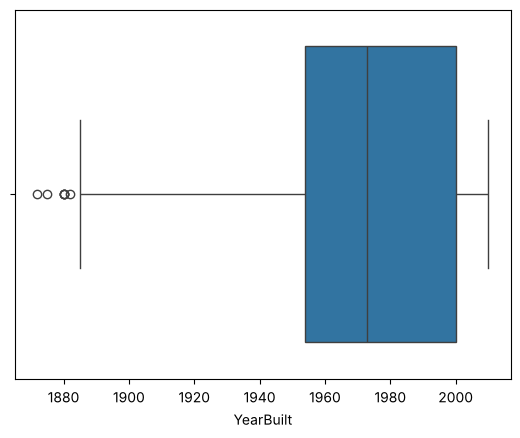

In [274]:
sns.kdeplot(x='YearBuilt', data=df_extra)
plt.show()
sns.boxplot(x='YearBuilt', data=df_extra)
plt.show()

Correlation = 0.59


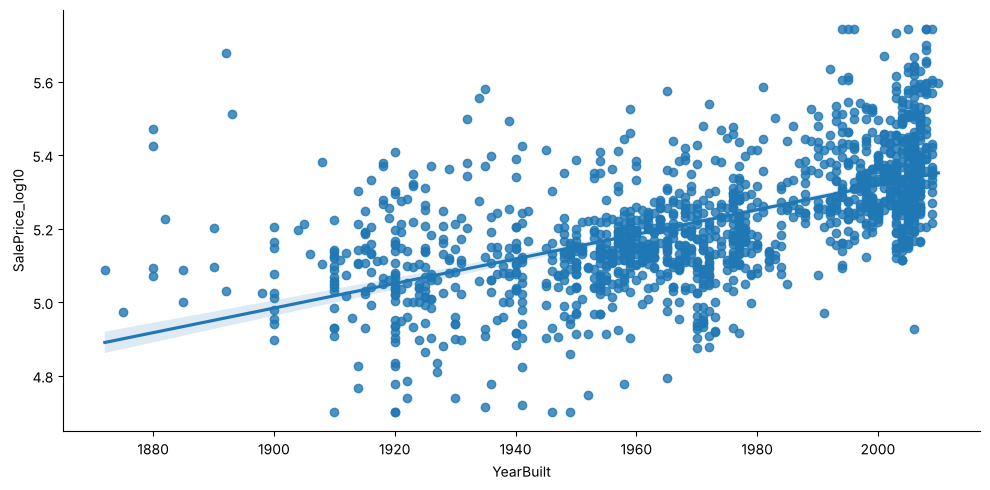

In [275]:
df_new = pd.concat([df_extra[['YearBuilt']], df[['SalePrice_log10']]], axis=1)
sns.lmplot(x='YearBuilt', y='SalePrice_log10', data=df_new, aspect=2)
print("Correlation =", df_new['YearBuilt'].corr(df_new['SalePrice_log10']).round(3))

Newer homes tend to sell for higher prices — positive relationship with SalePrice.

In [276]:
df_extra['HomeAge'] = 2010 - df_extra['YearBuilt']
df_extra.drop(columns=['YearBuilt'], inplace=True)
print(df_extra['HomeAge'].skew())

0.6134611724881861


YearBuilt is converted to HomeAge (2010 - YearBuilt) so that the variable is directly interpretable, so older homes have higher HomeAge and lower prices.This makes the linear relationship negative and more intuitive.

In [277]:
col = 'HomeAge'
mean1 = df_extra[col].mean()
std1  = df_extra[col].std()

lower3 = mean1 - 3 * std1
upper3 = mean1 + 3 * std1

outliers3 = df_extra[(df_extra[col] < lower3) | (df_extra[col] > upper3)]
print("3SD bounds:", lower3, "to", upper3)
print("Number of outliers:", len(outliers3))

df_extra[col] = df_extra[col].clip(lower3, upper3)
print("\nWINSORIZING results:")
print("Outliers capped to the cutoff values of", lower3, "and", upper3)
print(df_extra[col].mean().round(2))

3SD bounds: -51.87652034675385 to 129.3409039083977
Number of outliers: 6

WINSORIZING results:
Outliers capped to the cutoff values of -51.87652034675385 and 129.3409039083977
38.72


In [278]:
df_extra['HomeAge'].skew()

np.float64(0.6056239960448017)

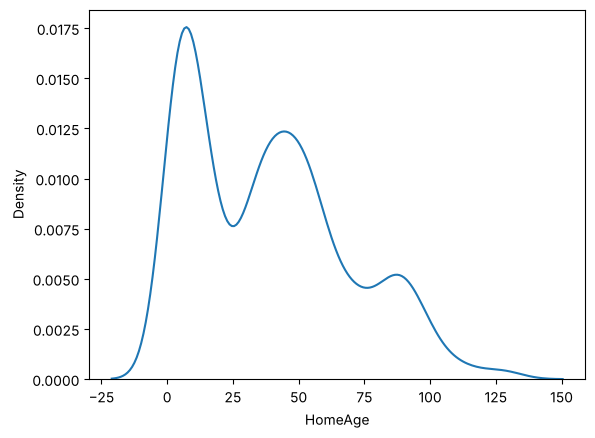

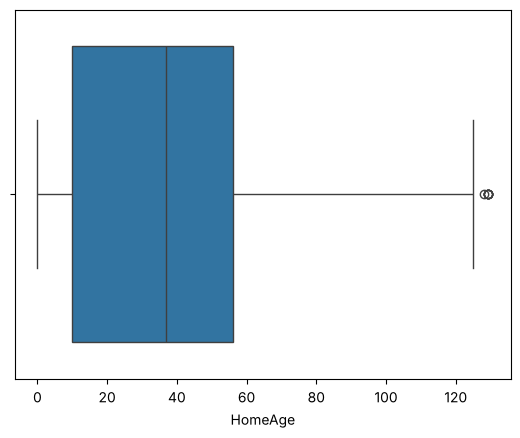

In [279]:
sns.kdeplot(x='HomeAge', data=df_extra)
plt.show()
sns.boxplot(x='HomeAge', data=df_extra)
plt.show()

Correlation = -0.59


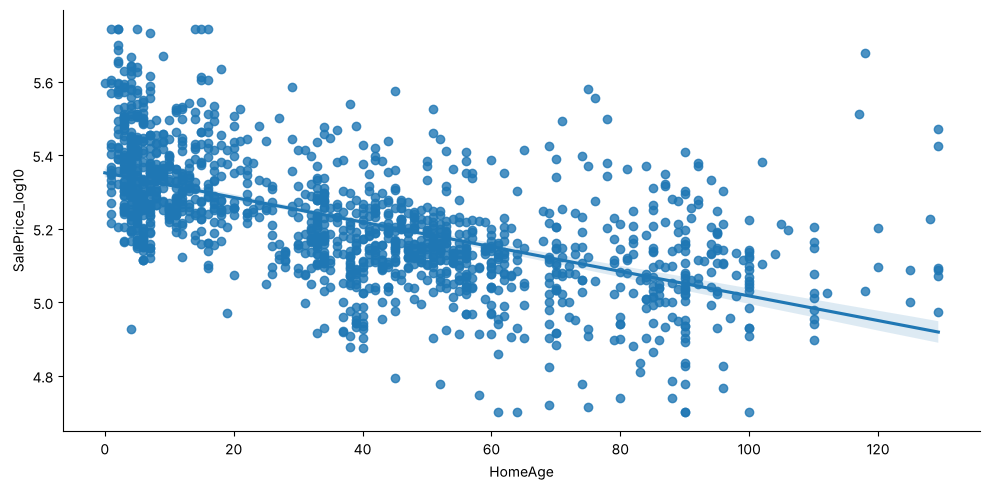

In [280]:
df_new = pd.concat([df_extra[['HomeAge']], df[['SalePrice_log10']]], axis=1)
sns.lmplot(x='HomeAge', y='SalePrice_log10', data=df_new, aspect=2)
print("Correlation =", df_new['HomeAge'].corr(df_new['SalePrice_log10']).round(3))

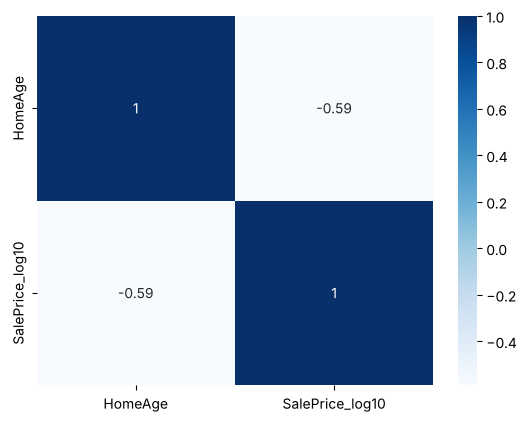

In [281]:
df_new.corr()['SalePrice_log10']
sns.heatmap(df_new.corr(), annot=True, cmap="Blues")
plt.show()

Older homes (higher HomeAge) tend to sell for lower prices, it has strong negative correlation with SalePrice_log10. HomeAge is a useful predictor for the model.

In [282]:
onehot_extra = [c for c in df_extra.select_dtypes(include='number').columns
                if df_extra[c].isin([0,1]).all() and df_extra[c].nunique() == 2]
continuous_extra = [c for c in df_extra.select_dtypes(include='number').columns
                    if c not in onehot_extra]

df_extra_std = df_extra.copy()
df_extra_std[continuous_extra] = df_extra_std[continuous_extra].apply(
    lambda x: zscore(x, nan_policy='omit'))

print("Standardized:", continuous_extra)
print("One-hot skipped:", onehot_extra)

Standardized: ['GrLivArea', 'TotalBsmtSF', 'GrLivArea_log', 'HomeAge']
One-hot skipped: ['KitchenQual_Ex', 'KitchenQual_Gd', 'KitchenQual_TA']


### Part 2 

In [283]:
# Combine the cleaned Part 1 predictors with the extra Part 2 columns
df_model = pd.concat([df_std, df_extra_std], axis=1)
model_df = df_model.drop(columns=['SalePrice'], errors='ignore').dropna()

# Define outcome and predictors
outcome = model_df['SalePrice_log10']
predictors = model_df.drop(['SalePrice_log10'], axis=1)
predictors = predictors.select_dtypes(include='number').astype(float)

In [284]:
model = pg.linear_regression(X=predictors, y=outcome)
print(model)

              names      coef        se          T           pval        r2  \
0         Intercept  1.005810  0.017709  56.797703   0.000000e+00  0.901046   
1       LotFrontage -0.001669  0.002249  -0.741906   4.582720e-01  0.901046   
2           LotArea  0.043805  0.019408   2.257086   2.416001e-02  0.901046   
3       GarageYrBlt  0.302786  0.211600   1.430936   1.526772e-01  0.901046   
4        GarageArea  0.003024  0.003947   0.766164   4.437110e-01  0.901046   
..              ...       ...       ...        ...            ...       ...   
110   GrLivArea_log  0.065044  0.007991   8.139970   8.811317e-16  0.901046   
111  KitchenQual_Ex  0.359427  0.008076  44.504582  3.845815e-268  0.901046   
112  KitchenQual_Gd  0.333925  0.006859  48.687535  7.466066e-301  0.901046   
113  KitchenQual_TA  0.312458  0.007054  44.294511  1.756042e-266  0.901046   
114         HomeAge -0.021573  0.004629  -4.660805   3.457236e-06  0.901046   

       adj_r2     CI2.5    CI97.5  
0    0.894386  

/usr/local/lib/python3.13/dist-packages/pingouin/regression.py:373: UserWarning: Design matrix supplied with `X` parameter is rank deficient (rank 93 with 115 columns). That means that one or more of the columns in `X` are a linear combination of one of more of the other columns.
  warnings.warn(


### Linear Relationship between X and Y

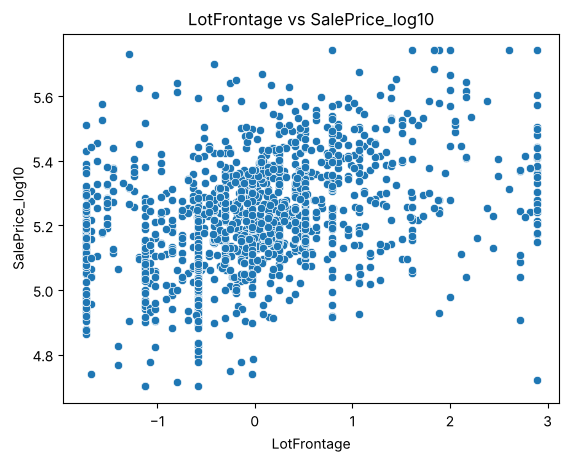

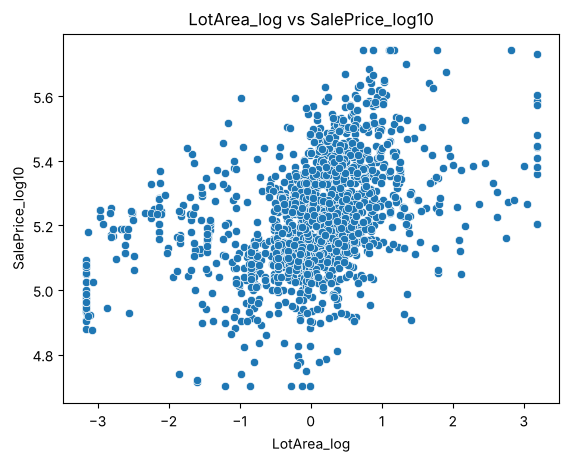

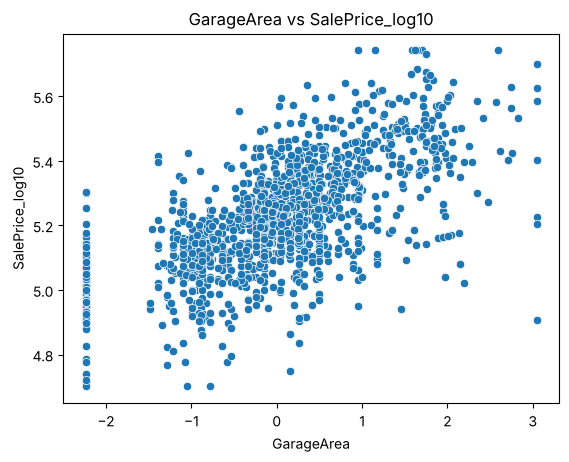

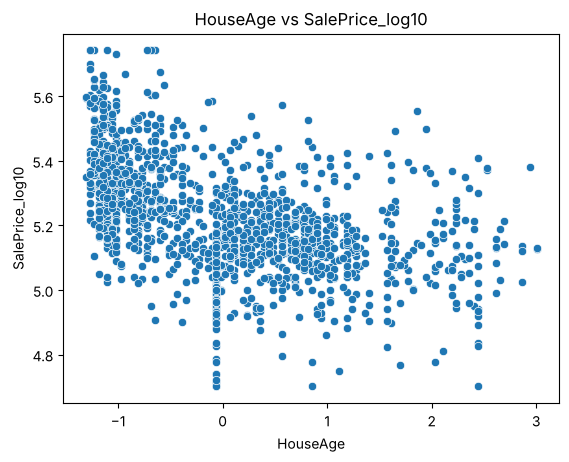

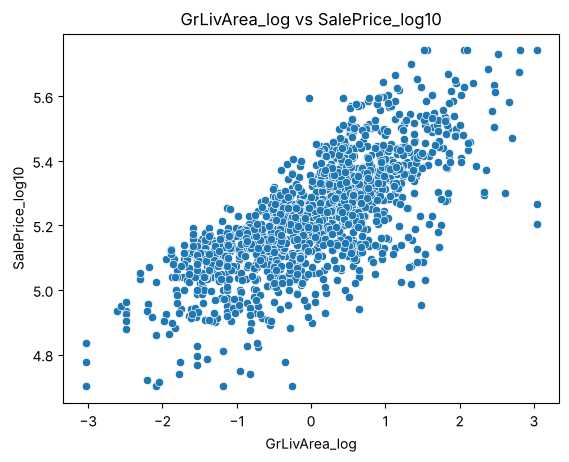

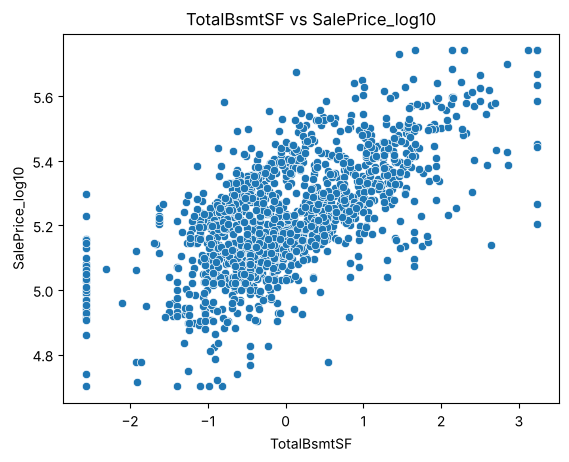

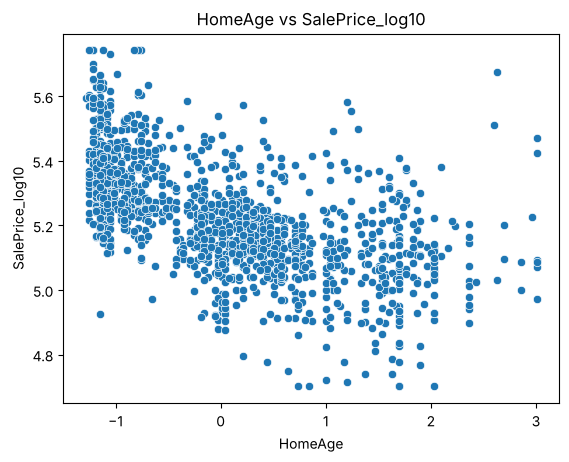

In [285]:
predict = ['LotFrontage', 'LotArea_log', 'GarageArea', 'HouseAge',
                    'GrLivArea_log', 'TotalBsmtSF', 'HomeAge']

for col in predict:
    sns.scatterplot(x=col, y='SalePrice_log10', data=df_model)
    plt.title(f'{col} vs SalePrice_log10')
    plt.show()

Each scatterplot shows an approximately linear relationship between the continuous predictor and SalePrice_log10, confirming the linearity assumption. Log transformations applied to GrLivArea and LotArea were specifically chosen to linearize their relationships with SalePrice_log10.

### Error Terms Normally Distributed with Mean = 0

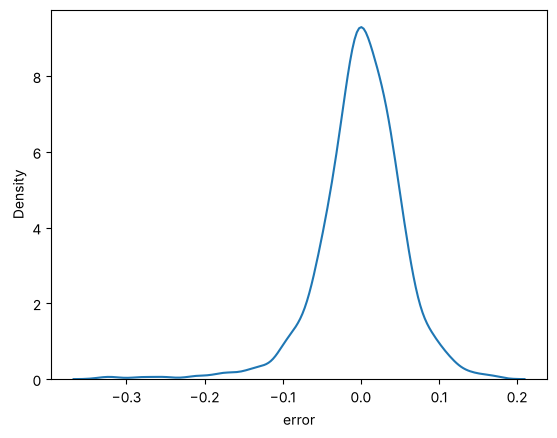

Mean of errors: -0.0


In [286]:
#Normality of Errors
residuals = pd.Series(model.residuals_)
model_df = model_df.copy()
model_df['error'] = residuals.values
model_df['calculated_SalePrice_log10'] = model_df['SalePrice_log10'] - residuals.values

sns.kdeplot(x='error', data=model_df)
plt.show()
print("Mean of errors:", model_df['error'].mean().round(6))

The KDE plot shows residuals are approximately normally distributed and centered near 0, confirming the assumption of normal error terms with mean = 0.

### Homoscedasticity

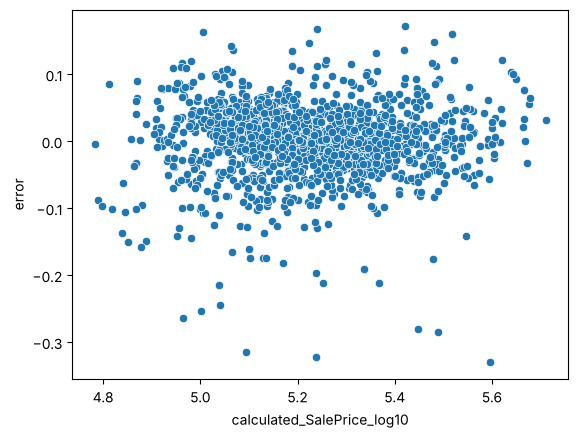

In [287]:
sns.scatterplot(x='calculated_SalePrice_log10', y='error', data=model_df)
plt.show()

In [288]:
from scipy.stats import zscore

residual_z = zscore(model_df['error'])
df_model_clean = model_df[abs(residual_z) < 2.5].copy()

In [289]:
outcome_clean = df_model_clean['SalePrice_log10']
predictors_clean = df_model_clean.drop(['SalePrice_log10', 'error','calculated_SalePrice_log10'], axis=1, errors='ignore')
predictors_clean = predictors_clean.select_dtypes(include='number').astype(float)

model = pg.linear_regression(X=predictors_clean, y=outcome_clean)
print(model)

              names      coef        se          T          pval        r2  \
0         Intercept  1.017808  0.013879  73.332238  0.000000e+00  0.935638   
1       LotFrontage -0.000471  0.001796  -0.262351  7.930914e-01  0.935638   
2           LotArea  0.013710  0.015572   0.880413  3.787947e-01  0.935638   
3       GarageYrBlt  0.322089  0.165571   1.945318  5.194719e-02  0.935638   
4        GarageArea  0.006327  0.003146   2.011203  4.450548e-02  0.935638   
..              ...       ...       ...        ...           ...       ...   
110   GrLivArea_log  0.024917  0.007179   3.470768  5.355865e-04  0.935638   
111  KitchenQual_Ex  0.362829  0.006364  57.010806  0.000000e+00  0.935638   
112  KitchenQual_Gd  0.336841  0.005393  62.455516  0.000000e+00  0.935638   
113  KitchenQual_TA  0.318139  0.005557  57.249274  0.000000e+00  0.935638   
114         HomeAge -0.028945  0.003718  -7.784901  1.394076e-14  0.935638   

       adj_r2     CI2.5    CI97.5  
0    0.931186  0.990580  1.

/usr/local/lib/python3.13/dist-packages/pingouin/regression.py:373: UserWarning: Design matrix supplied with `X` parameter is rank deficient (rank 93 with 115 columns). That means that one or more of the columns in `X` are a linear combination of one of more of the other columns.
  warnings.warn(


The final model explains 93.1% of the variance in SalePrice_log10 (Adj. R² = 0.931), indicating a very strong fit.

- GarageArea (coef = 0.006): larger garage area increases SalePrice
- GrLivArea_log (coef = 0.025): larger living area increases SalePrice  
- HomeAge (coef = -0.029): older homes sell for less

Not significant (p > 0.05):
- LotFrontage (p = 0.79) and LotArea (p = 0.38): weak predictors when controlling for other variables

Also, all three KitchenQual dummies (Ex, Gd, TA) were included, which creates perfect multicollinearity (the dummy variable trap): one must be dropped as the reference category. Drop KitchenQual_TA and rerun the model.

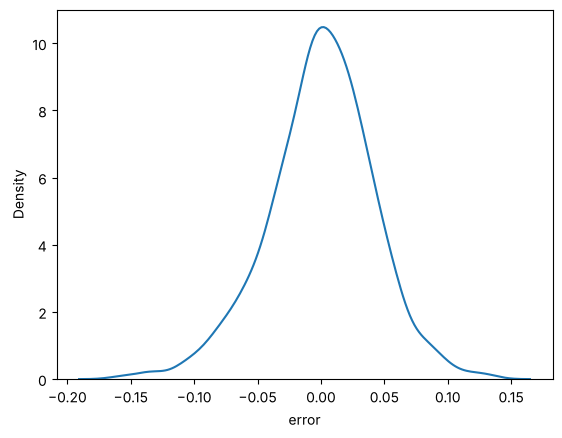

In [290]:
#Recalculate errors on clean data
residuals = pd.Series(model.residuals_)
df_model_clean['error'] = residuals.values
df_model_clean['calculated_SalePrice_log10']= outcome_clean.values - residuals.values

sns.kdeplot(x='error', data=df_model_clean)
plt.show()

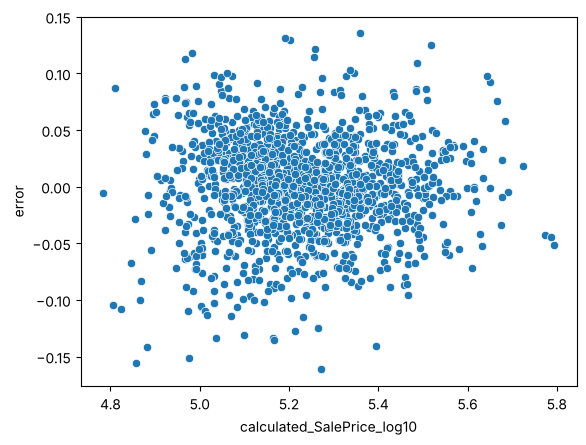

In [291]:
# Homoscedasticity after cleaning
sns.scatterplot(x='calculated_SalePrice_log10', y='error', data=df_model_clean)
plt.show()

After plotting error terms against calculated SalePrice_log10, a small number of extreme residuals were identified that created uneven spread and violated the homoscedasticity assumption. So I am trying to fix it with residuals were standardized using z-scores and any observation with an absolute z-score greater than 2.5 was removed. This follows the standard 
outlier removal threshold discussed in class.

Since SalePrice_log10 was already applied to reduce the funnel-shaped heteroscedasticity seen with raw SalePrice, removing these remaining extreme residuals is the final step needed to fully satisfy the assumption of constant  error variance.

### VIF

In [292]:
vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(predictors.values, i)
              for i in range(predictors.shape[1])]
vif['variable'] = predictors.columns
vif

/tmp/ipykernel_825/3167192008.py:2: UserWarning: The design matrix is poorly conditioned (condition number=5.32e+34). VIF calculations may be numerically unstable.
  vif['VIF'] = [variance_inflation_factor(predictors.values, i)
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stat

...

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


,VIF,variable
0,2.389413e+00,LotFrontage
1,1.778687e+02,LotArea
2,2.103204e+04,GarageYrBlt
3,7.356939e+00,GarageArea
4,1.109367e+02,BsmtFullBath
...,...,...
109,3.015255e+01,GrLivArea_log
110,2.740263e+06,KitchenQual_Ex
111,1.224072e+06,KitchenQual_Gd
112,4.541330e+05,KitchenQual_TA


In [293]:
#Drop high VIF columns (>10) 
predictors_clean2 = predictors_clean.drop(['KitchenQual_TA', 'GarageYrBlt', 'LotArea', 'BsmtFullBath'],axis=1, errors='ignore')

# Recheck VIF
vif = pd.DataFrame()
vif['VIF'] = [variance_inflation_factor(predictors_clean2.values, i)
              for i in range(predictors_clean2.shape[1])]
vif['variable'] = predictors_clean2.columns
vif

/tmp/ipykernel_825/4162910996.py:6: UserWarning: The design matrix is poorly conditioned (condition number=2.32e+32). VIF calculations may be numerically unstable.
  vif['VIF'] = [variance_inflation_factor(predictors_clean2.values, i)


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stat

...

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stat

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stat

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stat

/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
/usr/local/lib/python3.13/dist-packages/statsmodels/stats/outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared


,VIF,variable
0,2.396950,LotFrontage
1,7.237199,GarageArea
2,118.554259,BsmtHalfBath
3,4.564303,FullBath
4,537.394325,HalfBath
...,...,...
105,3.453899,TotalBsmtSF
106,38.015065,GrLivArea_log
107,2.445313,KitchenQual_Ex
108,2.437239,KitchenQual_Gd


In [294]:
# Refit final model
model = pg.linear_regression(X=predictors_clean2, y=outcome_clean)
print(model)

              names      coef        se          T          pval        r2  \
0         Intercept  1.106956  0.012693  87.209402  0.000000e+00  0.935028   
1       LotFrontage -0.000398  0.001802  -0.220880  8.252199e-01  0.935028   
2        GarageArea  0.006435  0.003156   2.039185  4.162849e-02  0.935028   
3      BsmtHalfBath -0.002499  0.012552  -0.199093  8.422203e-01  0.935028   
4          FullBath -0.007837  0.002477  -3.163967  1.591508e-03  0.935028   
..              ...       ...       ...        ...           ...       ...   
106     TotalBsmtSF  0.018721  0.002164   8.649398  1.463434e-17  0.935028   
107   GrLivArea_log  0.025636  0.007201   3.559985  3.839143e-04  0.935028   
108  KitchenQual_Ex  0.044398  0.007231   6.140092  1.086265e-09  0.935028   
109  KitchenQual_Gd  0.018658  0.003666   5.089652  4.100470e-07  0.935028   
110         HomeAge -0.029469  0.003723  -7.914539  5.182861e-15  0.935028   

       adj_r2     CI2.5    CI97.5  
0    0.930691  1.082055  1.

/usr/local/lib/python3.13/dist-packages/pingouin/regression.py:373: UserWarning: Design matrix supplied with `X` parameter is rank deficient (rank 90 with 111 columns). That means that one or more of the columns in `X` are a linear combination of one of more of the other columns.
  warnings.warn(


In [295]:
#Recalculate errors + RMSE
residuals = pd.Series(model.residuals_)
df_model_clean['error'] = residuals.values
df_model_clean['calculated_SalePrice_log10'] = outcome_clean.values - residuals.values

rmse = np.sqrt(np.mean(df_model_clean['error']**2))
rmse

np.float64(0.04213973117243679)

The RMSE is 0.042, which is very small, it means the model's predictions are very close to the actual SalePrice values on average. The lower the RMSE, the better the model

Intepret

The initial VIF results show several multicollinearity issues that need to be fixed:

- KitchenQual_Ex, Gd, TA → VIF = inf:  all three dummy columns were included at the same time, which causes perfect multicollinearity (dummy variable trap). KitchenQual_TA is dropped as the reference category.
- GarageYrBlt (VIF = 21,145): this is redundant with HomeAge since both measure the same thing (age of the home). GarageYrBlt is dropped.
- LotArea (VIF = 178): highly correlated with other size variables. LotArea is dropped since LotArea_log is already in the model.
- BsmtFullBath (VIF = 111): correlated with TotalFullBath. BsmtFullBath is dropped.
- HomeAge (VIF = 10.1): borderline, expected to improve after GarageYrBlt is removed.

After dropping KitchenQual_TA, GarageYrBlt, LotArea, and BsmtFullBath, the VIF check above still shows very high values for most dummy columns. The reason is that **every** one-hot group (Neighborhood, MSSubClass, OverallQual, GarageCars, …) still includes all of its categories, so the same dummy variable trap applies to all of them, not just KitchenQual. This is fixed in the **Final Model** section below.

# Final Model: Fixing Multicollinearity

The VIF check above showed that multicollinearity was not fully resolved. Each one-hot encoded group still contained **all** of its categories, and since every row belongs to exactly one category, the dummies in each group always sum to 1. That is perfectly collinear with the intercept (the dummy variable trap), which affects all 17 categorical groups.

Steps:
1. Drop **one reference category per group** (the most common category, so other categories are interpreted relative to the typical home).
2. Drop redundant versions of the same variable (`LotArea`, `LotArea_log10`, `LotArea_sqrt` → keep `LotArea_log`; `GrLivArea` → keep `GrLivArea_log`; `GarageYrBlt` → keep `HouseAge`).
3. Iteratively remove the predictor with the highest VIF until **all VIF < 10**.
4. Refit, apply the same residual outlier rule as before (|z| > 2.5), and evaluate.

In [296]:
import warnings
warnings.filterwarnings('ignore')  # silence numerical warnings from rank-deficient VIF steps

X_all = model_df.drop(columns=['SalePrice_log10', 'error', 'calculated_SalePrice_log10'], errors='ignore')
X_all = X_all.select_dtypes(include='number').astype(float)
y_all = model_df['SalePrice_log10']

# Group one-hot columns by their prefix (e.g. Neighborhood_*)
groups = {}
for col in X_all.columns:
    if X_all[col].isin([0, 1]).all():
        groups.setdefault(col.rsplit('_', 1)[0], []).append(col)

# Reference category = most common category in each group
reference = [X_all[cols].sum().idxmax() for cols in groups.values()]
print("Reference categories dropped:")
for r in reference:
    print("  -", r)

redundant = ['LotArea', 'LotArea_log10', 'LotArea_sqrt', 'GrLivArea', 'GarageYrBlt']
X_final = X_all.drop(columns=reference + redundant, errors='ignore')
print("\nPredictors remaining:", X_final.shape[1])

Reference categories dropped:
  - MSSubClass_20
  - LotConfig_Inside
  - LandSlope_Gtl
  - Neighborhood_NAmes
  - OverallQual_5
  - ExterQual_TA
  - NumFireplaces_0
  - FireplaceQu_None
  - BedroomAbvGr_3
  - TotalFullBath_2
  - TotalHalfBath_0
  - GarageCars_2
  - GarageType_Attchd
  - GarageFinish_Unf
  - GarageQual_TA
  - GarageCond_Decent
  - KitchenQual_TA

Predictors remaining: 92


In [297]:
# Iteratively drop the highest-VIF predictor until every VIF < 10
def vif_table(X):
    Xc = sm.add_constant(X)
    return pd.Series([variance_inflation_factor(Xc.values, i + 1) for i in range(X.shape[1])],
                     index=X.columns).sort_values(ascending=False)

vif_dropped = []
vif_final = vif_table(X_final)
while vif_final.max() >= 10:
    worst = vif_final.index[0]
    vif_dropped.append((worst, round(vif_final.iloc[0], 1)))
    X_final = X_final.drop(columns=worst)
    vif_final = vif_table(X_final)

print("Dropped for high VIF:")
for name, v in vif_dropped:
    print(f"  - {name} (VIF = {v:,})")
print("\nFinal number of predictors:", X_final.shape[1])
print("Max VIF:", round(vif_final.max(), 2))
vif_final.head(10).round(2).to_frame('VIF')

Dropped for high VIF:
  - FireplaceQu_Fa (VIF = 21,913,098.4)
  - GarageFinish_None (VIF = 4,194,304.0)
  - GarageCond_None (VIF = 262,144.0)
  - GarageQual_None (VIF = 4,194,304.0)
  - GarageCars_0 (VIF = 1,000,799,917,193,443.6)
  - HalfBath (VIF = 644.3)
  - FullBath (VIF = 103.6)
  - NumFireplaces_1 (VIF = 12.5)
  - HomeAge (VIF = 10.0)

Final number of predictors: 83
Max VIF: 7.41


,VIF
GrLivArea_log,7.41
GarageArea,7.23
HouseAge,4.35
MSSubClass_60,4.14
GarageType_None,4.09
LotArea_log,3.95
BsmtFullBath,3.93
OverallQual_8,3.47
TotalBsmtSF,3.42
ExterQual_Gd,3.38


In [298]:
# Fit on all rows, then remove extreme residuals (|z| > 2.5) and refit
model_final = pg.linear_regression(X=X_final, y=y_all)
resid_z = zscore(model_final.residuals_)
keep = np.abs(resid_z) < 2.5

X_fc, y_fc = X_final[keep], y_all[keep]
model_final = pg.linear_regression(X=X_fc, y=y_fc)

final_rmse = np.sqrt(np.mean(model_final.residuals_ ** 2))
print("Observations:", keep.sum(), f"(removed {(~keep).sum()} extreme residuals)")
print("R²:     ", round(model_final['r2'].iloc[0], 3))
print("Adj. R²:", round(model_final['adj_r2'].iloc[0], 3))
print("RMSE (log10 scale):", round(final_rmse, 4))
print(f"Typical prediction error: about ±{(10 ** final_rmse - 1) * 100:.1f}% of the sale price")

Observations: 1424 (removed 36 extreme residuals)
R²:      0.932
Adj. R²: 0.927
RMSE (log10 scale): 0.0434
Typical prediction error: about ±10.5% of the sale price


In [299]:
# Significant predictors (p < 0.05), ranked by effect size
sig = model_final[(model_final['names'] != 'Intercept') & (model_final['pval'] < 0.05)]
sig = sig.reindex(sig['coef'].abs().sort_values(ascending=False).index)
print("Significant predictors:", len(sig), "of", X_final.shape[1])
sig[['names', 'coef', 'se', 'pval']].head(15).round(4)

Significant predictors: 51 of 83


,names,coef,se,pval
44,OverallQual_3 or less,-0.1119,0.0103,0.0
43,OverallQual_10,0.0959,0.0166,0.0
49,OverallQual_9,0.0944,0.0117,0.0
26,Neighborhood_Crawfor,0.0833,0.0085,0.0
64,TotalFullBath_4 or more,0.0690,0.0146,0.0
48,OverallQual_8,0.0679,0.0069,0.0
41,Neighborhood_StoneBr,0.0590,0.0117,0.0
40,Neighborhood_Somerst,0.0535,0.0079,0.0
6,MSSubClass_160,-0.0519,0.0104,0.0
34,Neighborhood_NridgHt,0.0515,0.0088,0.0


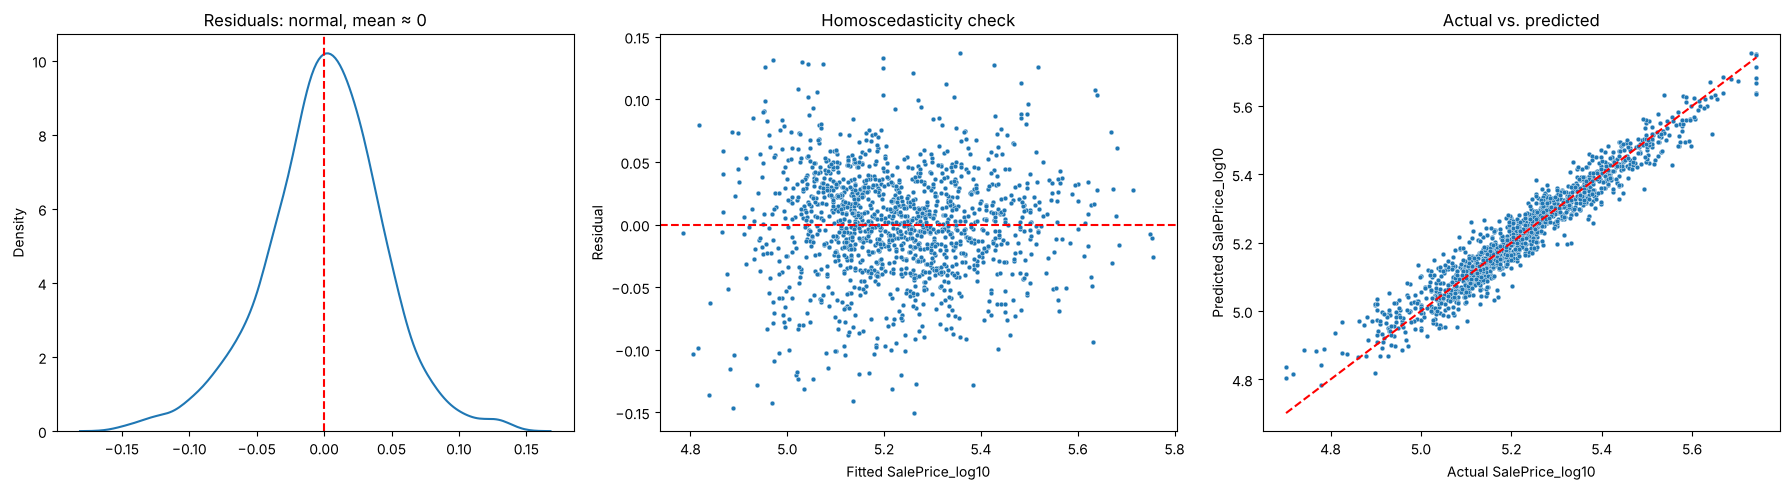

Mean of residuals: 0.0


In [300]:
fitted = y_fc.values - model_final.residuals_

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
sns.kdeplot(x=model_final.residuals_, ax=ax[0])
ax[0].axvline(0, color='red', linestyle='--')
ax[0].set_title('Residuals: normal, mean ≈ 0')

sns.scatterplot(x=fitted, y=model_final.residuals_, ax=ax[1], s=12)
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_xlabel('Fitted SalePrice_log10'); ax[1].set_ylabel('Residual')
ax[1].set_title('Homoscedasticity check')

sns.scatterplot(x=y_fc.values, y=fitted, ax=ax[2], s=12)
lims = [y_fc.min(), y_fc.max()]
ax[2].plot(lims, lims, color='red', linestyle='--')
ax[2].set_xlabel('Actual SalePrice_log10'); ax[2].set_ylabel('Predicted SalePrice_log10')
ax[2].set_title('Actual vs. predicted')
plt.tight_layout()
plt.show()

print("Mean of residuals:", round(model_final.residuals_.mean(), 6))

## Final Model Summary

- **Multicollinearity resolved:** 17 reference categories and 5 redundant variables were dropped, then 9 more predictors were removed iteratively. All **83 remaining predictors have VIF < 10** (max = 7.4).
- **Fit:** R² = 0.932, **Adj. R² = 0.927** on 1,424 homes (after removing 36 extreme residuals). This is almost the same as the earlier model (0.931), but now the coefficients can be interpreted reliably.
- **Accuracy:** RMSE = 0.043 on the log10 scale, i.e. a typical prediction error of about **±10%** of the sale price.
- **Key drivers of price** (relative to the reference home): overall quality (OverallQual 8–10 strongly increases price, 3 or less strongly decreases it), neighborhood (Crawford, Stone Brook, Somerset, Northridge Heights, Northridge carry a premium), living area (`GrLivArea_log`), excellent kitchen quality, and having a garage (`GarageType_None` lowers price).
- **Assumptions:** residuals are approximately normal with mean ≈ 0, show no clear funnel pattern, and actual vs. predicted values follow the 45° line closely.